# Differential Expression Analysis — MSqRob (Precursor → Protein)

Tests for differential protein abundance between K562 and HEK293T cells using `msqrob2`, a ridge-regression-based mixed-effects model that operates on precursor-level intensities aggregated to proteins via median polish. Two complementary analyses are performed:

1. **Integrated analysis** — all cells across all plates fitted jointly with progressively richer batch-covariate sets, showing how correcting for technical effects changes sensitivity and specificity.
2. **Per-plate analysis** — each plate treated as an independent experiment, simulating a single-lab scenario. Results are compared back to the integrated hits to assess cross-lab reproducibility.

**Modelling framework** — `msqrob` uses a per-protein ridge-penalised robust mixed-effects model. The formula progression matches the scplainer variance-partitioning stages:

| Model | Covariates added | Captures |
|---|---|---|
| `norm` | `medianIntensityPeptide + nPrecursors` | Intensity-scale normalisation |
| `plate` | `+ (1\|plate_id)` | Plate-level batch intercept |
| `batch` | `+ (0 + X.position \| plate_id)` | Per-plate injection-position gradient |
| `all` | `+ injection_order + Diameter + (1\|plate:date)` | Run order + cell size + acquisition day |

**Inputs** (`Data/scplainer/SC/precursor/`)

| File | Description |
|---|---|
| `sce.rds` | Fitted scplainer SCE — provides the n/p-filtered precursor matrix and colData |

**Outputs** (`Data/MSqRob/`)

| File | Description |
|---|---|
| `res_{model}.rds` | Per-protein DEA results (logFC, SE, pval, adjPval) for each integrated model |
| `res_{model}.csv` | Same, CSV format |
| `results_per_plate.rds` | Named list of per-plate DEA results |

---

## Imports

In [3]:
library(reticulate)
use_condaenv("r45_msqrob", required = TRUE)

pkgs <- c(
    "anndata",
    "dplyr",
    "tidyr",
    "purrr",
    "tibble",
    "ggplot2",
    "patchwork",
    "ggrepel",
    "scales",
    "msqrob2",
    "scp",
    "QFeatures",
    "SingleCellExperiment",
    "MsCoreUtils",
    "UpSetR",
    "lubridate"
)

cat("Package check\n")
cat(strrep("─", 40), "\n")
for (p in pkgs) {
    status  <- requireNamespace(p, quietly = TRUE)
    version <- if (status) as.character(packageVersion(p)) else "MISSING"
    cat(sprintf("  %-25s %s\n", p, version))
}
cat("\n")

suppressPackageStartupMessages({
    invisible(lapply(pkgs, library, character.only = TRUE))
})

source("../../SCI_R/plotting_utils.R")
source("../../SCI_R/msqrob_plots.R")

Package check
──────────────────────────────────────── 
  anndata                   0.9.0
  dplyr                     1.2.1
  tidyr                     1.3.2
  purrr                     1.2.2
  tibble                    3.3.1
  ggplot2                   4.0.3
  patchwork                 1.3.2
  ggrepel                   0.9.8
  scales                    1.4.0
  msqrob2                   1.18.0
  scp                       1.20.0
  QFeatures                 1.20.0
  SingleCellExperiment      1.32.0
  MsCoreUtils               1.22.1
  UpSetR                    1.4.0
  lubridate                 1.9.5



## 0. Path Configuration

| Variable | Default | Environment override |
|---|---|---|
| `ROOT_OUT` | `../../Data` | `SCI_DATA_DIR` |
| `FIGURES_OUT` | `../../Figures` | `SCI_FIGURES_DIR` |

The scplainer SCE (`sce.rds`) is read from `ROOT_OUT/scplainer/SC/precursor/`. Results are written to `ROOT_OUT/MSqRob/`.

**Contrast and threshold constants** are also defined here so they are visible and easy to change without hunting through the notebook.

In [4]:
NOTEBOOK_DIR  <- normalizePath(getwd())
ROOT_OUT      <- normalizePath(file.path(NOTEBOOK_DIR, "../../Data"))
ROOT_OUT      <- Sys.getenv("SCI_DATA_DIR",    unset = ROOT_OUT)

FIGURES_OUT   <- normalizePath(file.path(NOTEBOOK_DIR, "../../Figures"))
FIGURES_OUT   <- Sys.getenv("SCI_FIGURES_DIR", unset = FIGURES_OUT)

ANNDATA_IN    <- file.path(ROOT_OUT, "AnnData", "out")
RESULTS_DIR   <- file.path(ROOT_OUT, "MSqRob")
FIG_OUT       <- file.path(FIGURES_OUT, "Figure_6", "MSqRob")

for (d in c( RESULTS_DIR,
            file.path(RESULTS_DIR, "per_plate"), FIG_OUT)) {
    dir.create(d, recursive = TRUE, showWarnings = FALSE)
}

# ── Column name constants ──────────────────────────────────────────────────
COL_CELL_TYPE   <- "source.name"
COL_PLATE       <- "plate_idx"
COL_INSTRUMENT  <- "instrument_type"
COL_X_POS       <- "comment.X.position."
COL_DATE        <- "comment.Gradient.time._date"
COL_DATETIME    <- "comment.Gradient.time._datetime"
COL_DIAMETER    <- "Diameter"
COL_N_PROTEINS  <- "n_proteins"
COL_MED_INT     <- "medianIntensityProtein"
COL_INJ_ORDER   <- "injection_order"

# ── Contrast constants (ridge-penalised coefficients are prefixed "ridge") ──
CONTRAST_STR    <- "ridgesource.nameK562 - ridgesource.nameHEK293T = 0"
CONTRAST_PARAMS <- c("ridgesource.nameK562", "ridgesource.nameHEK293T")
CONTRAST_LABEL  <- gsub(" = 0", "", CONTRAST_STR)

CONDITIONS <- c("HEK293T", "K562")

# ── Significance thresholds ────────────────────────────────────────────────
FDR_THRESHOLD <- 0.001
FC_THRESHOLD  <- 0.5

# ── Feature-preparation thresholds ────────────────────────────────────────
MIN_CELL_PCT <- 0.25  # within-plate completeness for per-plate analysis
MIN_N_PLATES <- 5  # number of plates a protein must be observed in for per-plate analysis
MIN_PREC_PER_PG <- 1 # minimum number of precursors per protein group for MSqRob analysis

cat("Setup complete.\n")
cat(sprintf("  Results dir   : %s\n", RESULTS_DIR))
cat(sprintf("  Figures dir   : %s\n", FIG_OUT))

Setup complete.
  Results dir   : /home/sam/SCI/SCI/Data/MSqRob
  Figures dir   : /home/sam/SCI/SCI/Figures/Figure_6/MSqRob


## 1. Load Data

Loads the scplainer SCE saved by `01_scplainer.ipynb`. This object already carries:
- A log₂-transformed precursor intensity matrix
- All fitted scplainer models (used only for the n/p ratio filter)
- Full `colData` with sample-level metadata

The SCE is the canonical input here; no additional AnnData loading is needed.

In [5]:
adata_precursor <- read_h5ad(file.path(ANNDATA_IN, "adata_precursor.h5ad"))

int_mat   <- t(as.matrix(adata_precursor$layers['X_log2']))

# Extract obs metadata for both plates
cd_3 <- adata_precursor$obs[adata_precursor$obs$plate_idx == "Astral_3", ]
cd_6 <- adata_precursor$obs[adata_precursor$obs$plate_idx == "Astral_6", ]
# Build lookup from Astral_3
injection_lookup <- setNames(cd_3$injection_order, cd_3$sample_name)
# Copy injection_order to Astral_6 cells where sample_name matches
mask <- adata_precursor$obs$plate_idx == "Astral_6" &
        adata_precursor$obs$sample_name %in% names(injection_lookup)

adata_precursor$obs$injection_order[mask] <-
    injection_lookup[adata_precursor$obs$sample_name[mask]]

cell_meta <- adata_precursor$obs
# filter samples
keep_samples <- !cell_meta[['completeness_outlier']] &
                cell_meta[['source name']] %in% CONDITIONS
cell_meta <- cell_meta[keep_samples, ]
int_mat   <- int_mat[, keep_samples]

# filter features: keep precursors observed in at least one remaining sample
keep_features <- rowSums(!is.na(int_mat)) > 0
int_mat       <- int_mat[keep_features, ]
var_meta      <- adata_precursor$var[keep_features, ]

# Parse into SingleCellExperiment and QFeatures
sce <- SingleCellExperiment(
    assays  = list(precursors_log = int_mat),
    colData = DataFrame(cell_meta),
    rowData = DataFrame(var_meta)
)
sce$medianIntensityprecursor <- colMedians(assay(sce, "precursors_log"), na.rm = TRUE)

In [6]:
mask <- adata_precursor$obs$plate_idx == "Astral_6" &
        adata_precursor$obs$`source name` %in% c("K562", "HEK293T") &
        is.na(adata_precursor$obs$injection_order)

cat("Missing injection_order in Astral_6 (K562 + HEK293T):", sum(mask), "\n")
print(table(adata_precursor$obs$`source name`[mask], useNA = "always"))

Missing injection_order in Astral_6 (K562 + HEK293T): 0 



<NA> 
   0 


## 2. Pre-processing

Two steps prepare the sample metadata for modelling:

1. **Injection order** — reconstructed from the gradient-start timestamp per plate and stored in `colData`. Required for `formula_all` and the per-plate formulae.
2. **Variable type coercion** — categorical colData columns are cast to `factor` and continuous columns to `numeric`, with a before/after summary to confirm correct coercion.

> `Diameter` has ~11% structural missingness. Cells without a Diameter measurement are excluded from the QFeatures object at the end of this section, consistent with the treatment in `01_scplainer.ipynb`.

### 2.3 Variable Type Audit and Cell Exclusion

In [7]:
FACTOR_COLS     <- c(COL_CELL_TYPE, COL_INSTRUMENT, COL_PLATE, COL_DATE)
CONTINUOUS_COLS <- c(COL_X_POS, COL_DIAMETER, COL_INJ_ORDER)

# Type summary before coercion
type_summary <- sapply(c(FACTOR_COLS, CONTINUOUS_COLS), function(v) {
    x <- colData(sce)[[v]]
    data.frame(type = class(x)[1], n_unique = length(unique(x[!is.na(x)])),
               n_na = sum(is.na(x)), example = paste(head(unique(x[!is.na(x)]), 3), collapse = ", "))
}, simplify = FALSE) %>% bind_rows(.id = "variable")
cat("Before coercion:\n"); print(type_summary)

for (v in FACTOR_COLS)     colData(sce)[[v]] <- factor(colData(sce)[[v]])
for (v in CONTINUOUS_COLS) colData(sce)[[v]] <- as.numeric(colData(sce)[[v]])

cat("\nDiameter missingness: ", sum(is.na(colData(sce)[[COL_DIAMETER]])), "\n")

# Exclude cells with missing Diameter
complete_cells <- !is.na(colData(sce)[[COL_DIAMETER]])
# sce <- sce[, complete_cells]
# cat(sprintf("Cells with Diameter: %d / %d  (%.1f%% retained)\n",
#             ncol(sce), length(complete_cells), 100 * mean(complete_cells)))

Before coercion:
                     variable      type n_unique n_na
1                 source.name character        2    0
2             instrument_type character        2    0
3                   plate_idx character        9    0
4 comment.Gradient.time._date character       13    0
5         comment.X.position.   numeric       12    0
6                    Diameter   numeric      489    0
7             injection_order   numeric      273    0
                                                  example
1                                           K562, HEK293T
2                                         timsTOF, Astral
3                           timsTOF_2, Astral_1, Astral_5
4                      2025-10-17, 2025-10-10, 2025-10-15
5                                                 3, 4, 5
6                                     18.85, 20.82, 19.01
7 0.932114882506527, 0.433420365535248, 0.519582245430809

Diameter missingness:  0 


## 3. Feature Preparation

Three steps convert the precursor-level SCE into a protein-level QFeatures ready for `msqrob`:

1. **n/p ratio filter** — re-applies the same threshold used in `01_scplainer.ipynb` (`NP_THRESHOLD = 10`) to retain only well-fitted precursors.
2. **Protein group validation** — removes precursors with missing or ambiguous `PG.ProteinGroups` annotations, and protein groups with fewer than 2 precursors (required for median polish to be meaningful).
3. **Aggregation** — precursors are aggregated to proteins using median polish, which is robust to outlier precursors and handles the sparse missing-value pattern of single-cell data.

### 3.2 Build QFeatures and Filter Protein Groups

In [8]:
filter_features_qf <- function(
    qf,
    assay_name   = "precursors_log",
    col_plate    = COL_PLATE,
    min_cell_pct = 0.25,
    min_n_plates = 5
) {
    X      <- assay(qf[[assay_name]])
    meta   <- as.data.frame(colData(qf))
    plates <- levels(factor(meta[[col_plate]]))

    plate_comp <- sapply(plates, function(plate) {
        idx  <- which(meta[[col_plate]] == plate)
        m    <- X[, idx, drop = FALSE]
        comp <- rowMeans(!is.na(m))
        comp[rowSums(!is.na(m)) == 0] <- NA
        comp
    })

    passes           <- plate_comp >= min_cell_pct
    n_plates_passing <- rowSums(passes, na.rm = TRUE)
    keep             <- n_plates_passing >= min_n_plates

    cat(sprintf("Feature filter (%s):\n", assay_name))
    cat(sprintf("  Min. %% cells within plate : %.0f%%\n",  min_cell_pct * 100))
    cat(sprintf("  Min. number of plates     : %d / %d\n", min_n_plates, length(plates)))
    cat(sprintf("  Features before           : %d\n",      nrow(X)))
    cat(sprintf("  Features after            : %d  (%.1f%% retained)\n",
                sum(keep), 100 * mean(keep)))

    qf[keep, ]
}

In [9]:
qf <- QFeatures(
    experiments = list(precursors_log = sce),
    colData     = colData(sce)
)

pg          <- rowData(qf[["precursors_log"]])$PG.ProteinAccessions
is_contam   <- rowData(qf[["precursors_log"]])$Contaminant
pg_valid    <- !is.na(pg) & trimws(pg) != "" & !is_contam
pg_counts   <- table(pg[pg_valid])
valid_pgs   <- names(pg_counts[pg_counts >= MIN_PREC_PER_PG])

cat(sprintf("Precursors total              : %d\n", length(pg)))
cat(sprintf("  with NA/empty PG            : %d\n", sum(!pg_valid & !is_contam)))
cat(sprintf("  contaminants removed        : %d\n", sum(is_contam, na.rm = TRUE)))
cat(sprintf("  in single-precursor groups  : %d\n", sum(pg_counts == 1)))
cat(sprintf("Protein groups before filter  : %d\n", length(pg_counts)))
cat(sprintf("Protein groups after filter   : %d\n", length(valid_pgs)))

qf <- qf[pg_valid & pg %in% valid_pgs, ]
cat(sprintf("Precursors after filter       : %d\n", nrow(qf[["precursors_log"]])))

Precursors total              : 61000
  with NA/empty PG            : 0
  contaminants removed        : 3817
  in single-precursor groups  : 1665
Protein groups before filter  : 6628
Protein groups after filter   : 6628
Precursors after filter       : 57183


### 3.3 Aggregate Precursors to Proteins

`MsCoreUtils::medianPolish` fits a two-way additive model (row + column effects) by iteratively polishing row and column medians. It is robust to the outlier precursors common in single-cell data and handles `NA` values. The result is a protein × cell intensity matrix stored in the `proteins_medianPolish` experiment of `qf`.

In [10]:
qf <- aggregateFeatures(
    qf,
    i    = "precursors_log",
    fcol = "PG.ProteinAccessions",
    name = "proteins_medianPolish",
    fun  = MsCoreUtils::medianPolish,
    na.rm = TRUE
)

cat(sprintf("Proteins x cells: %d x %d\n",
            nrow(qf[["proteins_medianPolish"]]),
            ncol(qf[["proteins_medianPolish"]])))
print(qf)

Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.



Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() 

Proteins x cells: 6628 x 1864
An instance of class QFeatures (type: scp) with 2 sets:

 [1] precursors_log: SingleCellExperiment with 57183 rows and 1864 columns 
 [2] proteins_medianPolish: SingleCellExperiment with 6628 rows and 1864 columns 


In [11]:
sample_medians <- colMedians(assay(qf, "proteins_medianPolish"), na.rm = TRUE)
sample_n_proteins <- colSums(!is.na(assay(qf, "proteins_medianPolish")))

qf$medianIntensityProtein <- sample_medians
qf$n_proteins             <- sample_n_proteins

In [16]:
qf_filtered <- filter_features_qf(
    qf,
    assay_name   = "proteins_medianPolish",
    col_plate    = COL_PLATE,
    min_cell_pct = MIN_CELL_PCT,
    min_n_plates = MIN_N_PLATES
)

Feature filter (proteins_medianPolish):
  Min. % cells within plate : 25%
  Min. number of plates     : 5 / 9
  Features before           : 6628
  Features after            : 2153  (32.5% retained)


In [18]:
saveRDS(qf, file.path(RESULTS_DIR, 'QFeatures', "qf_checkpoint.rds"))
saveRDS(qf_filtered, file.path(RESULTS_DIR, 'QFeatures', "qf_filtered_checkpoint.rds"))

## 4. Helper Functions

Three reusable functions used throughout the analysis:

- **`fit_msqrob_model`** — wraps `msqrob → makeContrast → hypothesisTest → extract` into a single call, eliminating the copy-paste pattern that would otherwise repeat four times in the integrated analysis and many more times in the per-plate loop.
- **`plot_volcano`** — publication-ready volcano plot with configurable thresholds, optional protein labelling, and optional highlighting of an external protein set.
- **`plot_top_proteins`** — intensity box + jitter plots for the top-N most significant proteins, coloured by cell type and jittered by plate.

In [12]:
# Wraps the full msqrob → test → extract pipeline for one model
fit_msqrob_model <- function(qf, formula, model_name,
                              assay_name = "proteins_medianPolish") {
    qf <- msqrob(qf, i = assay_name, modelColumnName = model_name,
                 formula = formula, ridge = TRUE, robust = TRUE)

    L  <- makeContrast(CONTRAST_STR, parameterNames = CONTRAST_PARAMS)

    qf <- hypothesisTest(qf, i = assay_name, contrast = L,
                          modelColumn             = model_name,
                          resultsColumnNamePrefix = paste0(model_name, "_"),
                          adjust.method           = "BH")

    result_col <- paste0(model_name, "_", CONTRAST_LABEL)

    res <- rowData(qf[[assay_name]])[[result_col]] %>%
        as.data.frame() %>%
        rownames_to_column("protein") %>%
        arrange(pval)

    list(qf = qf, res = res)
}

## 5. Integrated Analysis

All cells across all plates are analysed jointly. Four models are fitted, each adding one more layer of technical covariates. This progressive design shows how controlling for additional technical effects changes the number of significant proteins and the precision of the fold-change estimates.

### 5.1 Model Formulas

**Design note for `formula_batch`** — `(1 | plate_id) + (0 + comment.X.position. | plate_id)` is preferred over the single `(1 + comment.X.position. | plate_id)` because the uncorrelated parameterisation is numerically more stable with 9 plates and avoids the correlation parameter estimation that can destabilise the solver at low plate counts. Both capture the same plate random intercept + per-plate X-position slope.

In [13]:
# Normalisation factors only
formula_norm <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins

# + Plate-level random intercept
formula_plate <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins +
    (1 | plate_id)

# + Per-plate injection-position gradient (uncorrelated with intercept)
formula_batch <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins +
    (1 | plate_id) +
    (0 + comment.X.position. | plate_id)

# Full model: + run order, acquisition day
formula_all <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins +
    injection_order +
    (1 | plate_id) +
    (0 + comment.X.position. | plate_id) +
    (1 | plate_id:comment.Gradient.time._date)

cat("Formulas defined.\n")

Formulas defined.


### 5.2 Fit Models

Each model is fitted, tested, and saved in a loop. Progress and significant-protein counts are printed after each fit so the runtime behaviour is visible.

In [19]:
model_configs <- list(
    list(formula = formula_norm,  name = "norm",  label = "Normalisation only"),
    list(formula = formula_plate, name = "plate", label = "Normalisation + plate"),
    list(formula = formula_batch, name = "batch", label = "Normalisation + plate + X-position"),
    list(formula = formula_all,   name = "all",   label = "Full model (all covariates)")
)

model_configs_filtered <- list(
    list(formula = formula_norm,  name = "norm_filtered",  label = "Normalisation only"),
    list(formula = formula_plate, name = "plate_filtered", label = "Normalisation + plate"),
    list(formula = formula_batch, name = "batch_filtered", label = "Normalisation + plate + X-position"),
    list(formula = formula_all,   name = "all_filtered",   label = "Full model (all covariates)")
)

model_labels <- list(
    list(formula = formula_norm,  name = "norm",  label = "Normalisation only"),
    list(formula = formula_plate, name = "plate", label = "Normalisation + plate"),
    list(formula = formula_batch, name = "batch", label = "Normalisation + plate + X-position"),
    list(formula = formula_all,   name = "all",   label = "Full model (all covariates)")
)

datasets <- list(
    list(qf_name = "qf",          suffix = "",          label = "unfiltered"),
    list(qf_name = "qf_filtered", suffix = "_filtered", label = "filtered")
)

for (dataset in datasets) {
    cat(sprintf("\n══ Fitting models on %s data ══\n", dataset$label))
    qf_current <- get(dataset$qf_name)

    for (cfg in model_labels) {
        name <- paste0(cfg$name, dataset$suffix)
        cat(sprintf("  [%s] %s...\n", name, cfg$label))
        flush.console()

        out        <- fit_msqrob_model(qf_current, cfg$formula, name)
        qf_current <- out$qf
        res        <- out$res

        assign(paste0("res_", name), res)

        n_sig <- sum(res$adjPval < FDR_THRESHOLD & abs(res$logFC) > FC_THRESHOLD, na.rm = TRUE)
        cat(sprintf("    Proteins tested : %d\n", nrow(res)))
        cat(sprintf("    Significant     : %d  (FDR < %.3f, |FC| > %.1f)\n",
                    n_sig, FDR_THRESHOLD, FC_THRESHOLD))

        saveRDS(res, file.path(RESULTS_DIR, sprintf("res_%s.rds", name)))
        write.csv(res, file.path(RESULTS_DIR, sprintf("res_%s.csv", name)), row.names = FALSE)
    }

    # write back enriched QFeatures using the stored name string
    assign(dataset$qf_name, qf_current)
}


══ Fitting models on unfiltered data ══
  [norm] Normalisation only...


Warning message:
“the ‘findbars’ function has moved to the reformulas package. Please update your imports, or ask an upstream package maintainter to do so.
This warning is displayed once per session.”
Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: I

    Proteins tested : 6628
    Significant     : 529  (FDR < 0.001, |FC| > 0.5)
  [plate] Normalisation + plate...


Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zm

    Proteins tested : 6628
    Significant     : 494  (FDR < 0.001, |FC| > 0.5)
  [batch] Normalisation + plate + X-position...


Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_

... (7 outputs left out)

Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zm

    Proteins tested : 2153
    Significant     : 329  (FDR < 0.001, |FC| > 0.5)
  [all_filtered] Full model (all covariates)...


Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_

    Proteins tested : 2153
    Significant     : 328  (FDR < 0.001, |FC| > 0.5)


### 5.3 Results Summary

Tabulates the number of significant proteins and mean standard error per model. A decreasing SE across models indicates that controlling for additional technical effects improves precision. A large jump in significant proteins between stages reveals that the corrected-for effect was suppressing differential signal.

In [15]:
summary_tab <- lapply(model_configs, function(cfg) {
    res   <- get(paste0("res_", cfg$name))
    n_sig <- sum(res$adjPval < FDR_THRESHOLD & abs(res$logFC) > FC_THRESHOLD, na.rm = TRUE)
    data.frame(
        model    = cfg$label,
        n_tested = nrow(res),
        n_sig    = n_sig,
        mean_se  = round(mean(res$se, na.rm = TRUE), 4),
        mean_fc  = round(mean(abs(res$logFC), na.rm = TRUE), 3)
    )
}) %>% bind_rows()

cat("Model comparison summary:\n")
print(summary_tab)

Model comparison summary:
                               model n_tested n_sig mean_se mean_fc
1                 Normalisation only     6628   529  0.1056   0.243
2              Normalisation + plate     6628   494  0.0753   0.247
3 Normalisation + plate + X-position     6628   510  0.0734   0.247
4        Full model (all covariates)     6628   514  0.0709   0.245


In [16]:
# Unfiltered
summary_tab <- lapply(model_configs_filtered, function(cfg) {
    res   <- get(paste0("res_", cfg$name))
    n_sig <- sum(res$adjPval < FDR_THRESHOLD & abs(res$logFC) > FC_THRESHOLD, na.rm = TRUE)
    data.frame(
        model    = cfg$label,
        n_tested = nrow(res),
        n_sig    = n_sig,
        mean_se  = round(mean(res$se, na.rm = TRUE), 4),
        mean_fc  = round(mean(abs(res$logFC), na.rm = TRUE), 3)
    )
}) %>% bind_rows()

cat("Model comparison summary:\n")
print(summary_tab)

Model comparison summary:
                               model n_tested n_sig mean_se mean_fc
1                 Normalisation only     2153   310  0.0380   0.269
2              Normalisation + plate     2153   327  0.0314   0.278
3 Normalisation + plate + X-position     2153   329  0.0309   0.278
4        Full model (all covariates)     2153   328  0.0303   0.278


### 5.4 Volcano Plots

Four volcano plots on shared axes, one per model. Using shared `x_lim` and `y_lim` makes fold-change distributions and significance levels directly comparable across panels.

In [17]:
source('../../SCI_R/msqrob_plots.R')

Shared x_lim: [-14.0, 4.0]  y_lim: [0.0, 338.0]
Shared x_lim: [-3.0, 3.0]  y_lim: [0.0, 338.0]


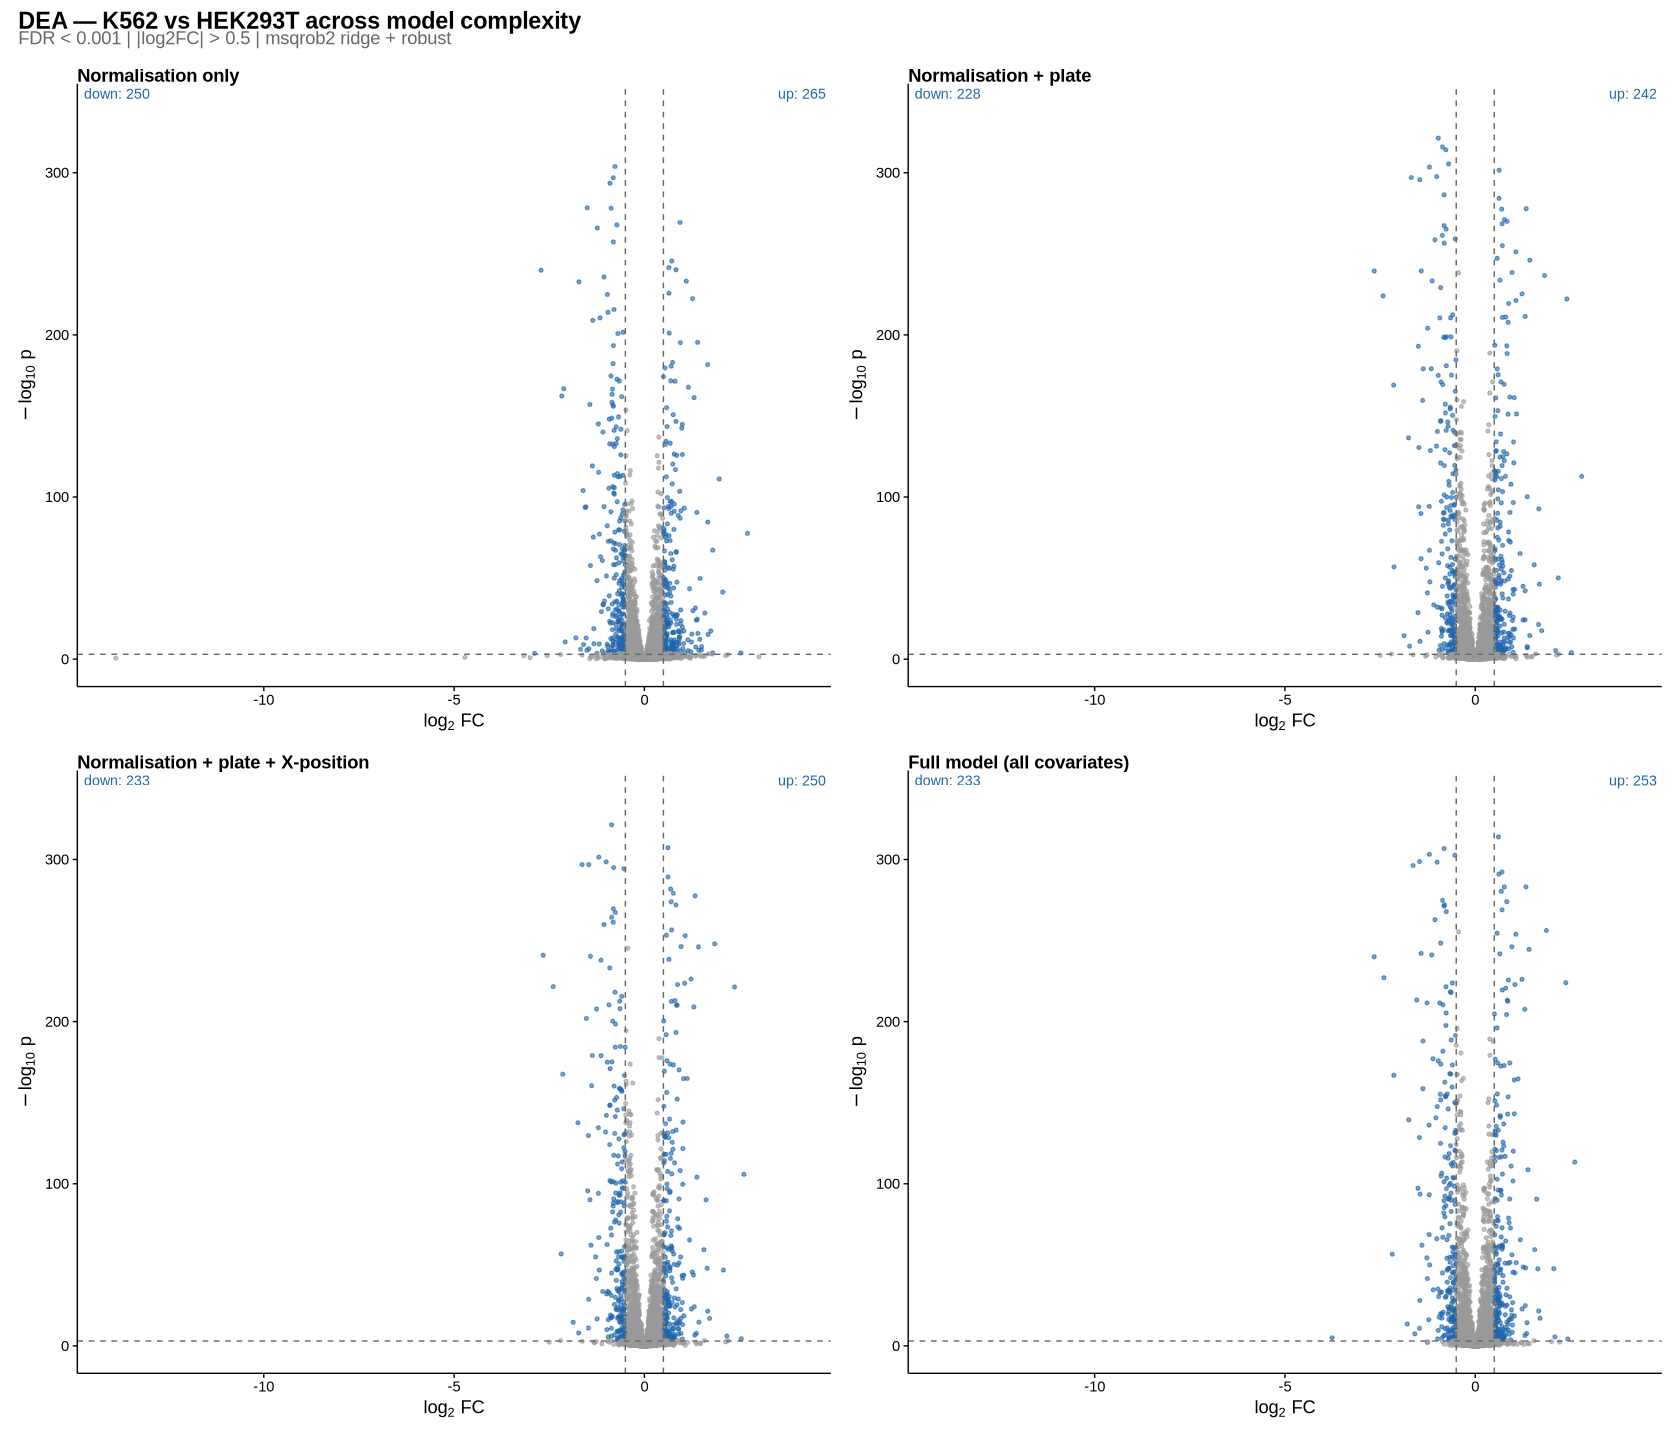

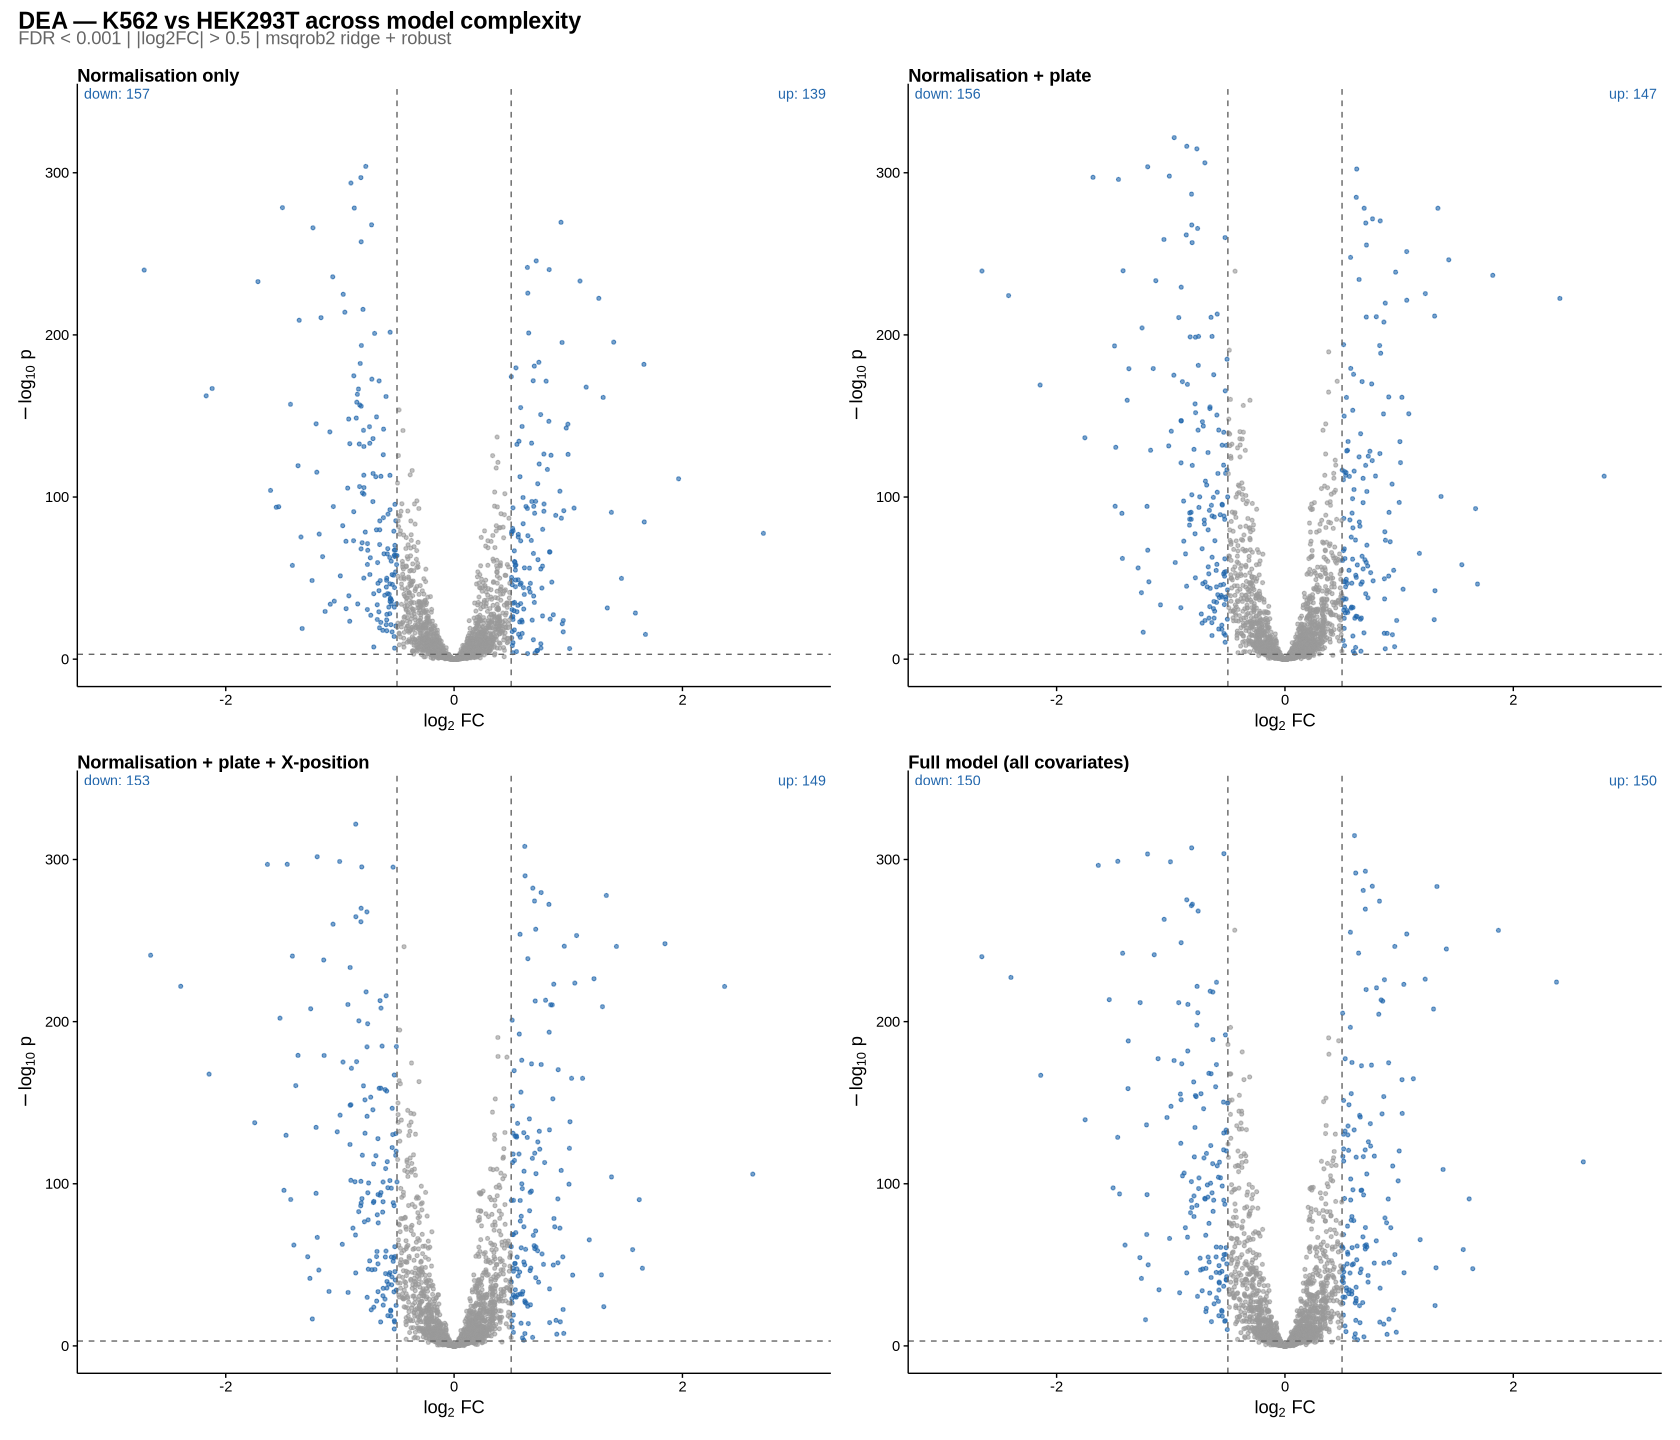

In [18]:
plot_volcano_grid(
    model_configs = model_configs,
    save_dir      = FIG_OUT,
    filename      = "volcano_grid",
    show          = TRUE
)

plot_volcano_grid(
    model_configs = model_configs_filtered,
    save_dir      = FIG_OUT,
    filename      = "volcano_grid_filtered",
    show          = TRUE
)

### 5.5 UpSet Plot — Model Overlap

Shows how significant protein sets overlap across the four models. Proteins that are significant in all models represent the most robust hits; proteins that appear only in the full model may reflect real signal uncovered by controlling for technical effects, or may be artefacts of over-fitting.

Significant proteins per model:
                Normalisation only              Normalisation + plate 
                               529                                494 
Normalisation + plate + X-position        Full model (all covariates) 
                               510                                514 


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”


Significant proteins per model:
                Normalisation only              Normalisation + plate 
                               310                                327 
Normalisation + plate + X-position        Full model (all covariates) 
                               329                                328 


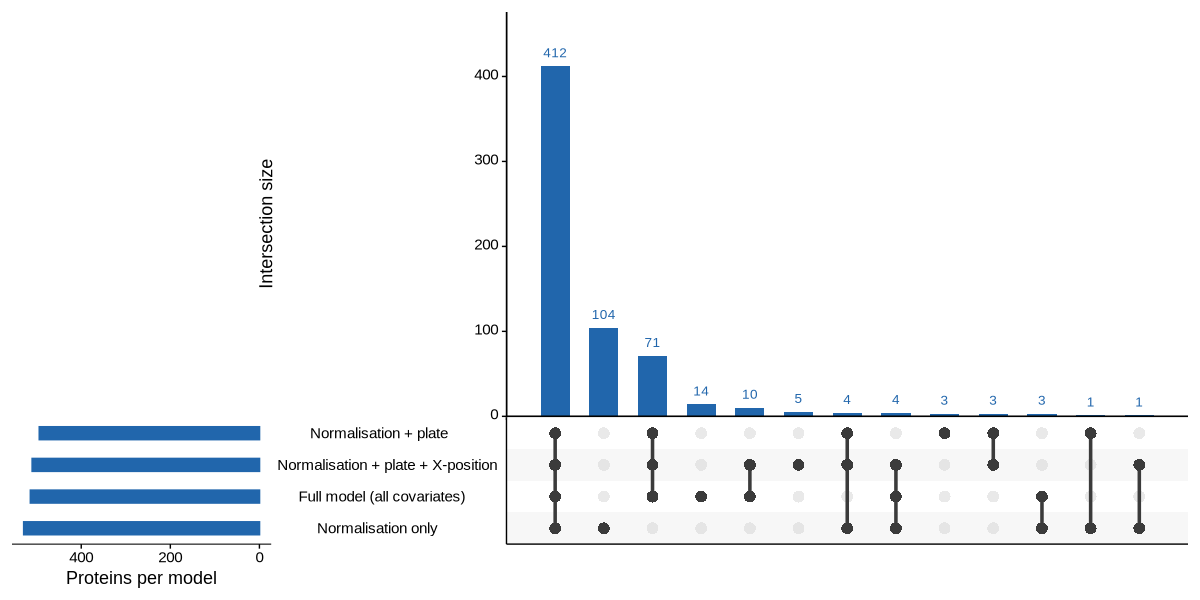

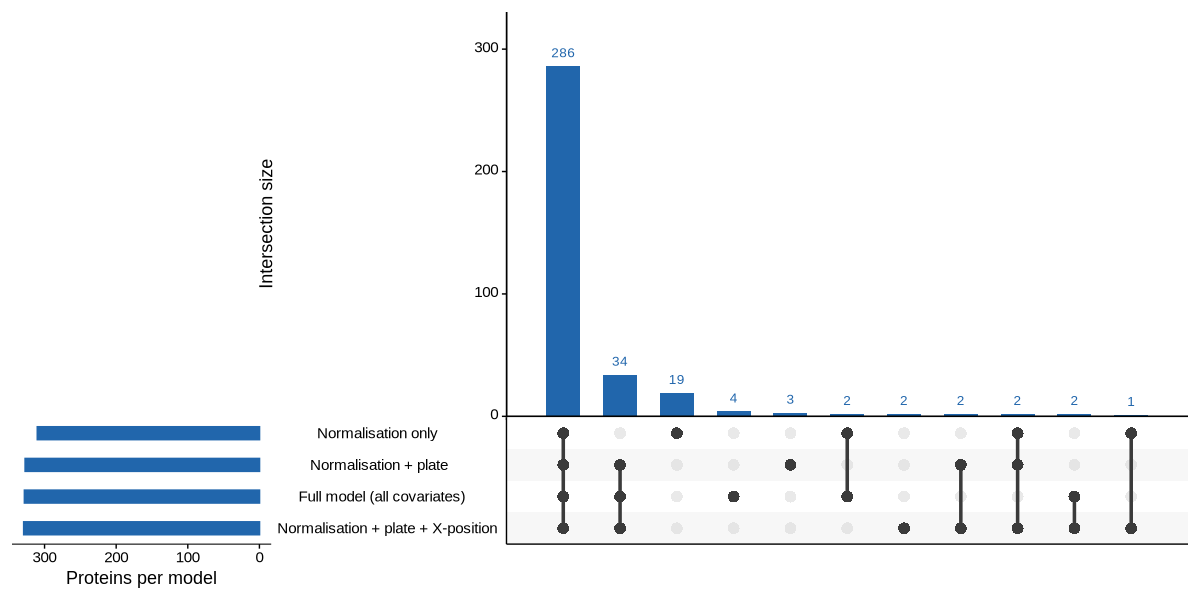

In [19]:
plot_upset_sig(
    model_configs = model_configs,
    save_dir      = FIG_OUT,
    filename      = "upset_sig",
    show          = TRUE
)

plot_upset_sig(
    model_configs = model_configs_filtered,
    save_dir      = FIG_OUT,
    filename      = "upset_sig_filtered",
    show          = TRUE
)

### 5.6 logFC and SE Comparison Across Models

Compares the log fold-change estimates and standard errors between the simplest model (norm) and the full model. A shrinkage in SE confirms that the additional covariates absorbed technical noise. A strong FC correlation (r > 0.95) confirms the biological contrast is robust to model choice.

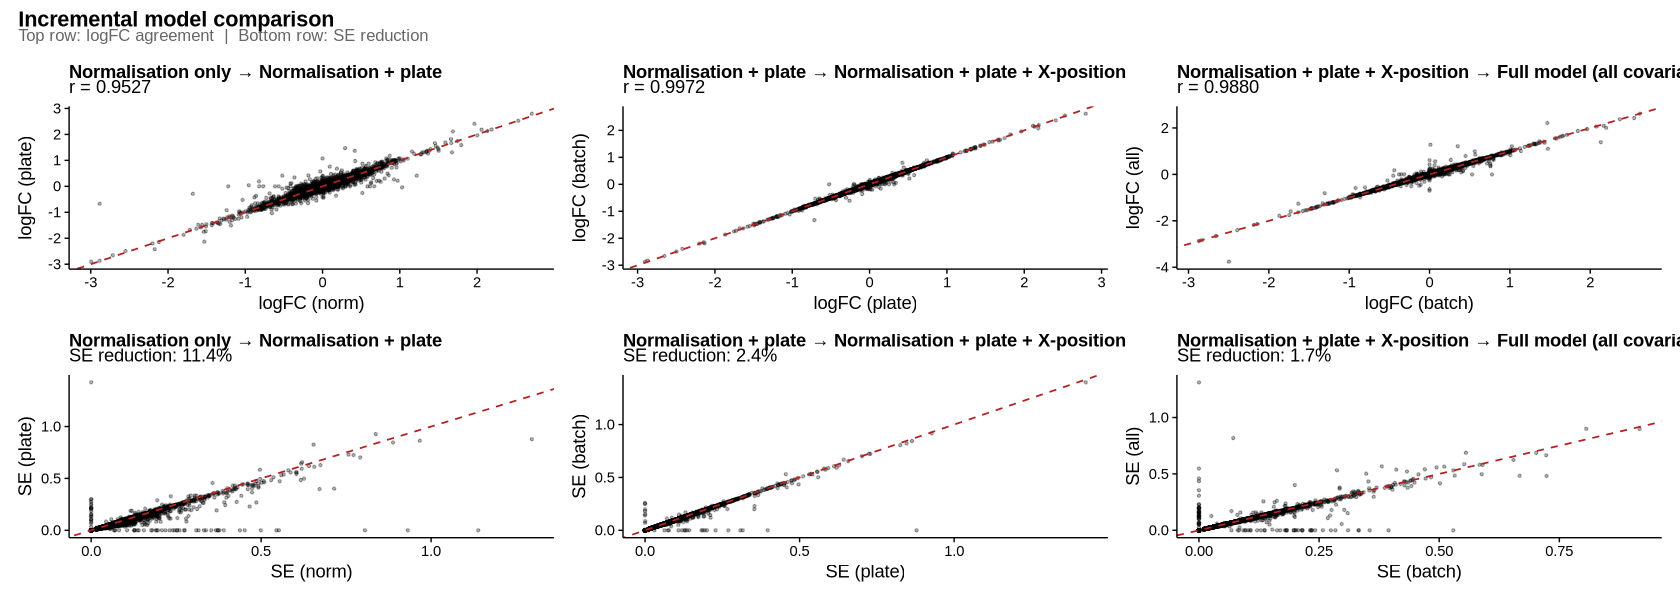

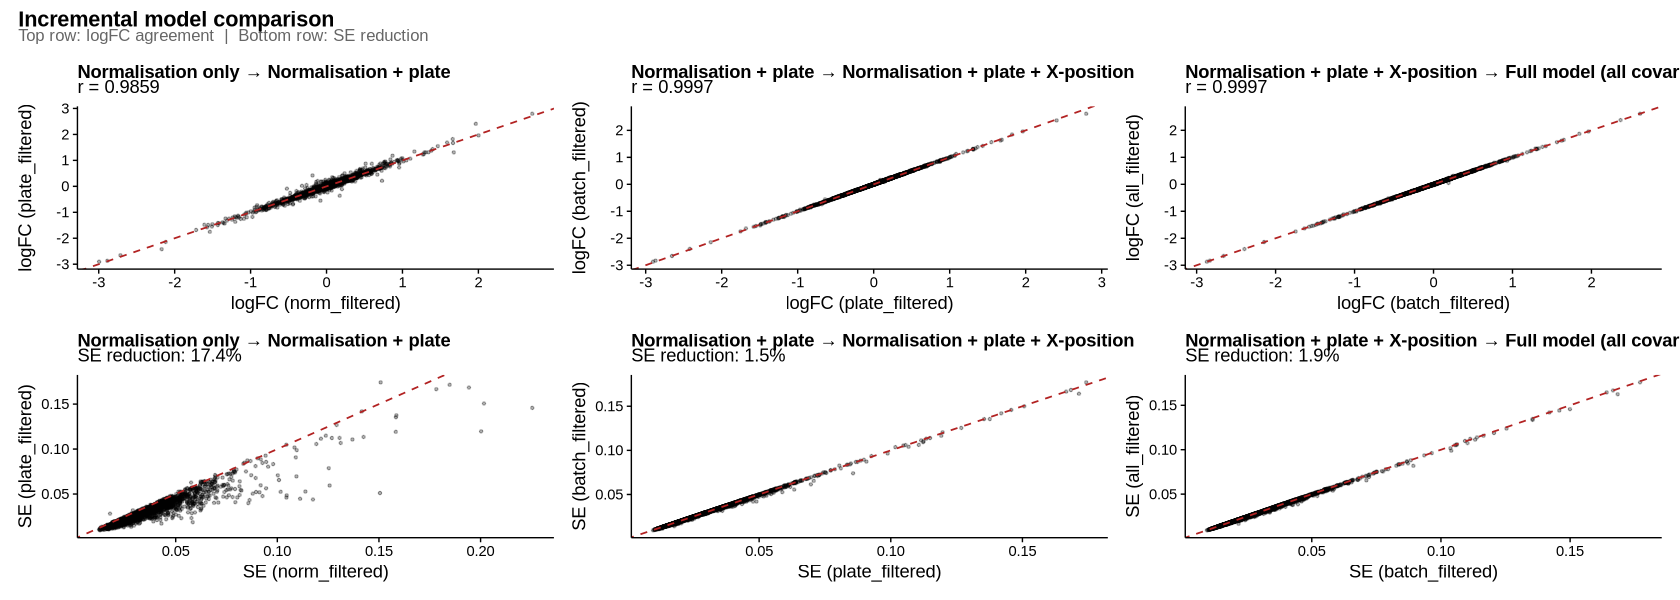

In [20]:
plot_model_comparison_grid(
    model_configs = model_configs,
    save_dir      = FIG_OUT,
    filename      = "model_comparison_grid",
    show          = TRUE
)

plot_model_comparison_grid(
    model_configs = model_configs_filtered,
    save_dir      = FIG_OUT,
    filename      = "model_comparison_grid_filtered",
    show          = TRUE
)

### 5.7 Top Protein Intensity Plots

Intensity distributions for the top 6 most significant proteins from the full model, boxed by cell type and jittered by plate. This is a visual sanity check: the fold changes should match what is visible in the raw intensities, and the within-group spread should be reasonable.

In [21]:
library(limma)

# remove batch effects, keeping source.name
batch_corrected <- removeBatchEffect(
    assay(qf[["proteins_medianPolish"]]),
    batch    = colData(qf)$plate_id,
    covariates = cbind(
        colData(qf)$medianIntensityProtein,
        colData(qf)$n_proteins,
        colData(qf)$injection_order,
        colData(qf)$comment.X.position.
    ),
    design = model.matrix(~ source.name, data = as.data.frame(colData(qf)))
)

assay(qf[["proteins_medianPolish"]], "batch_corrected") <- batch_corrected


Attaching package: ‘limma’


The following object is masked from ‘package:BiocGenerics’:

    plotMA




Warning message:
“Partial NA coefficients for 5095 probe(s)”


In [22]:
cat(sprintf("NA count before correction : %d (%.1f%%)\n",
            sum(is.na(assay(qf[["proteins_medianPolish"]], "assay"))),
            100 * mean(is.na(assay(qf[["proteins_medianPolish"]], "assay")))))
cat(sprintf("NA count after correction  : %d (%.1f%%)\n",
            sum(is.na(assay(qf[["proteins_medianPolish"]], "batch_corrected"))),
            100 * mean(is.na(assay(qf[["proteins_medianPolish"]], "batch_corrected")))))

NA count before correction : 8718108 (70.6%)
NA count after correction  : 8718108 (70.6%)


In [23]:
source("../../SCI_R/msqrob_plots.R")

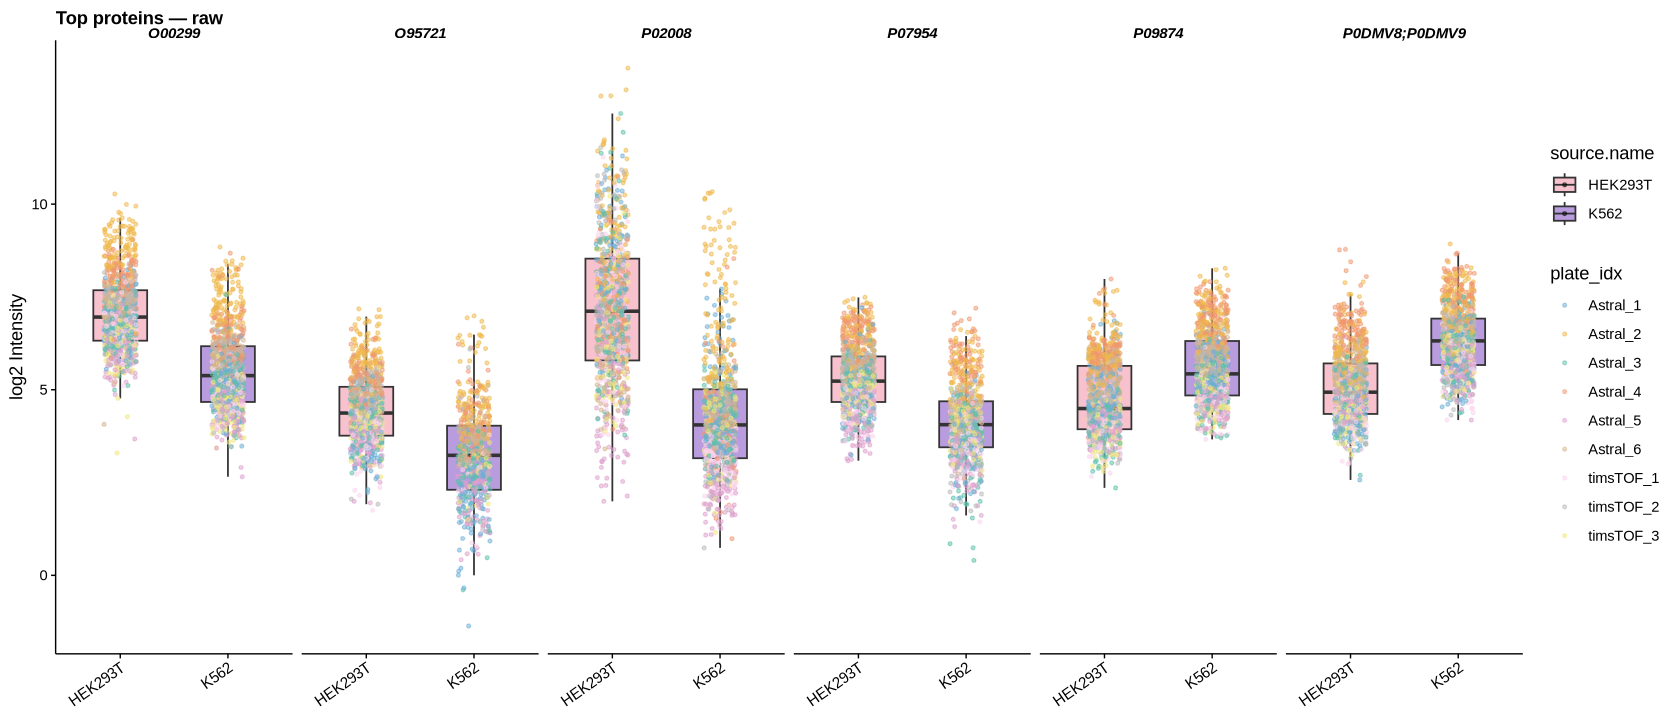

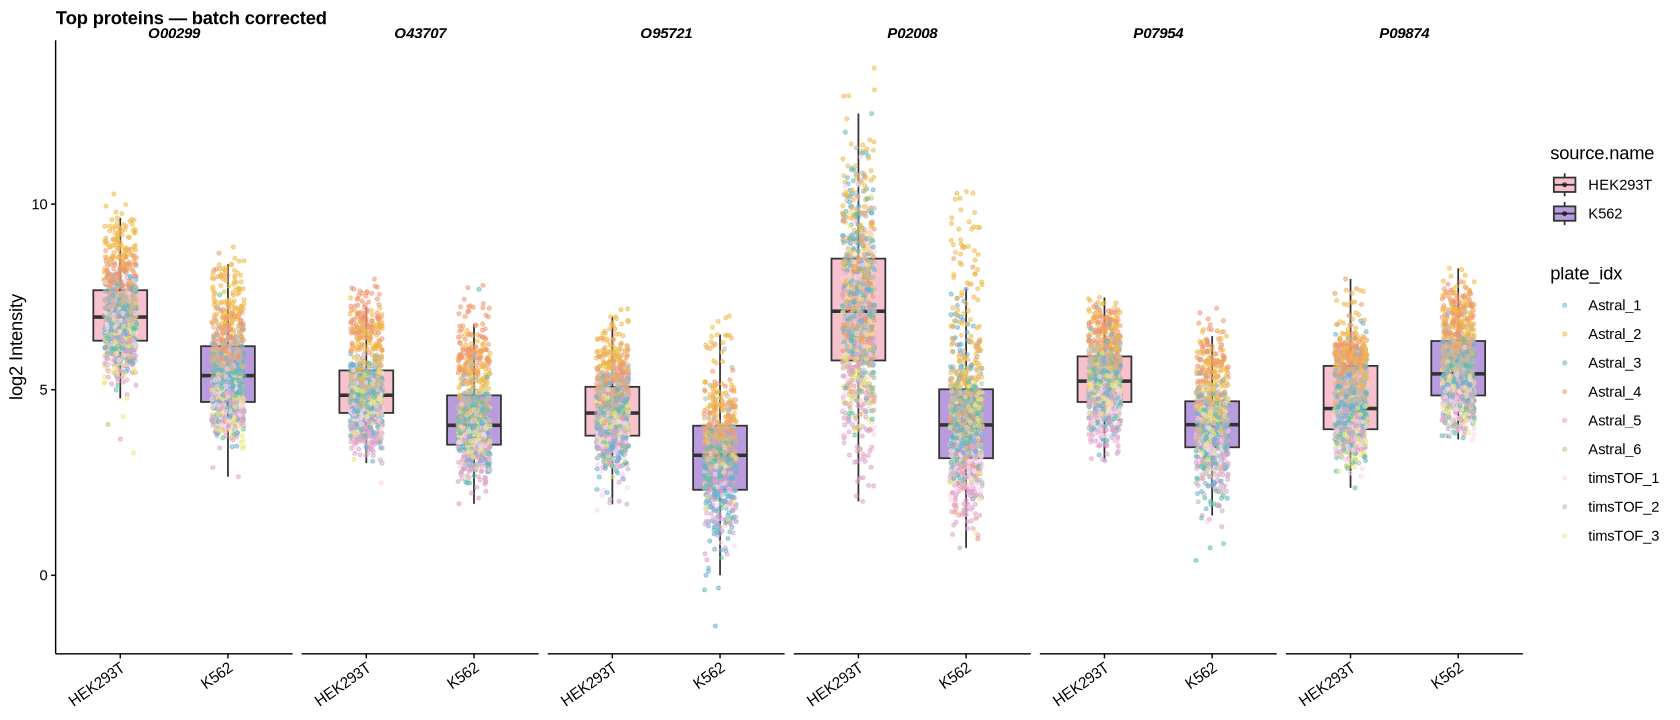

In [24]:
plot_top_proteins(res_norm, qf,
    experiment_name = "proteins_medianPolish",
    assay_name = 'assay',
    title      = "Top proteins — raw",
    save_dir   = FIG_OUT,
    filename   = "top_proteins_norm_raw",
    share_y    = TRUE,
    show       = TRUE
)

plot_top_proteins(res_all, qf,
    experiment_name = "proteins_medianPolish",
    assay_name = "assay",
    title      = "Top proteins — batch corrected",
    save_dir   = FIG_OUT,
    filename   = "top_proteins_all_corrected",
    share_y    = TRUE,
    show       = TRUE
)

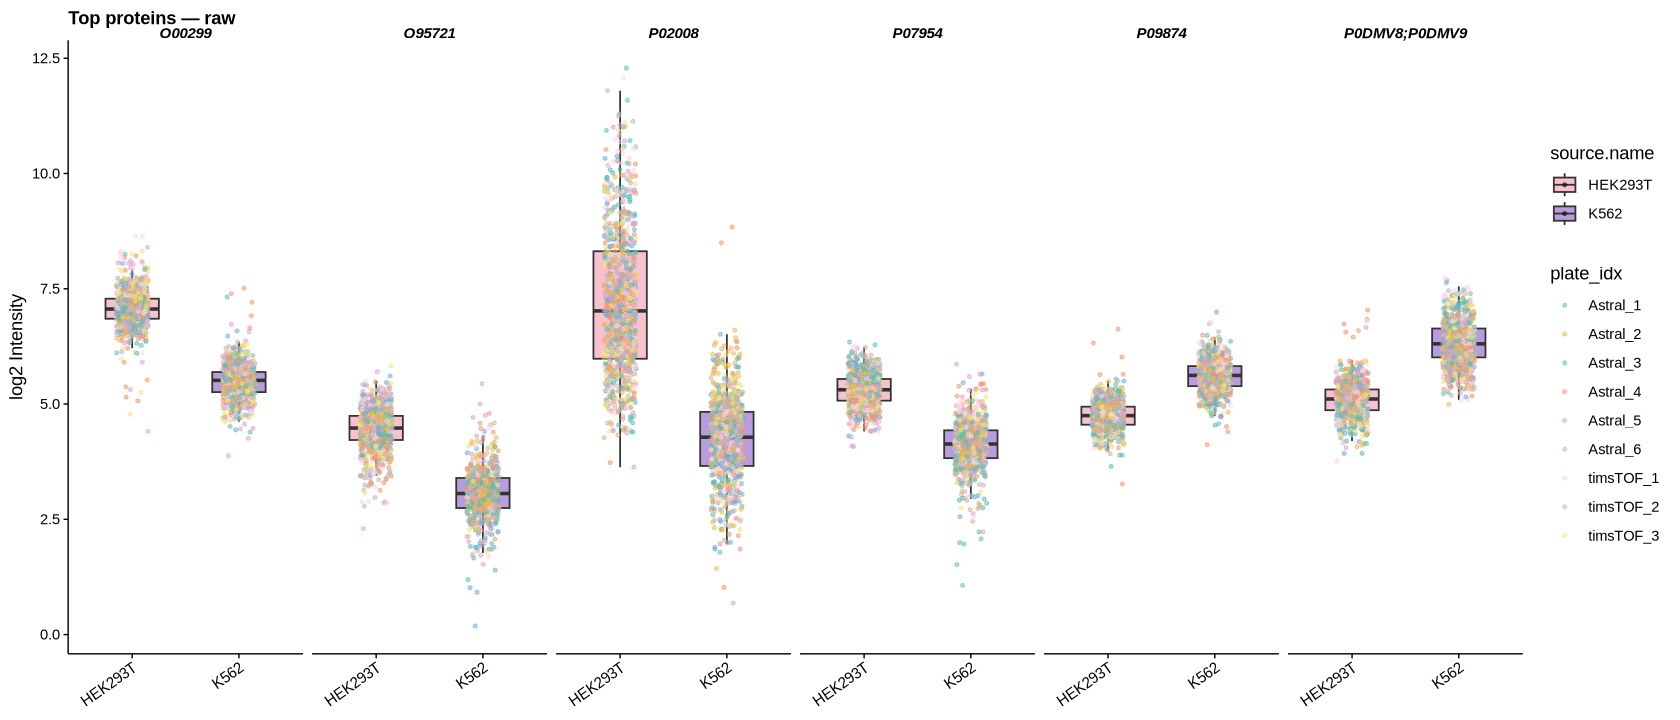

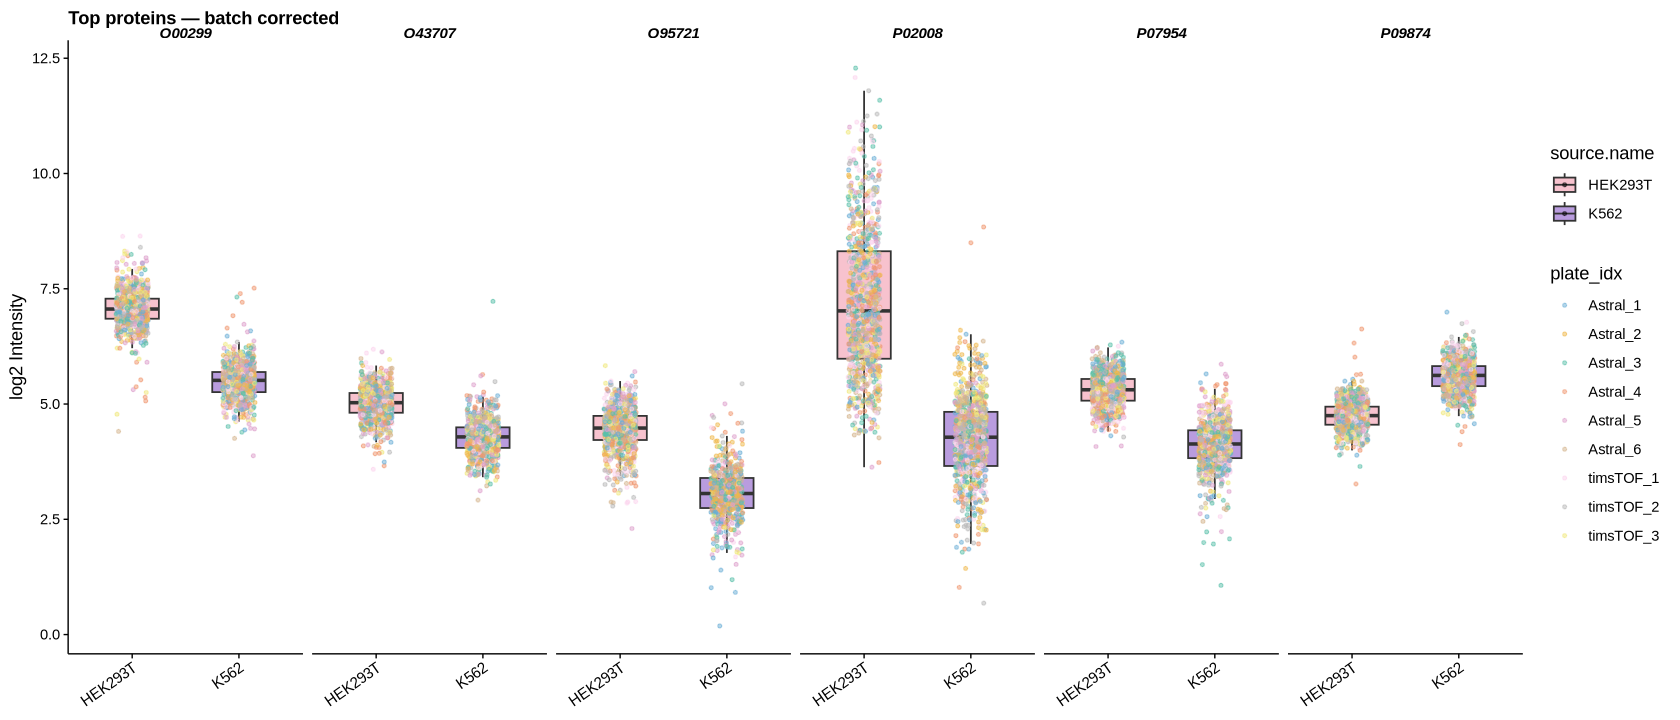

In [25]:
plot_top_proteins(res_norm, qf,
    experiment_name = "proteins_medianPolish",
    assay_name = 'batch_corrected',
    title      = "Top proteins — raw",
    save_dir   = FIG_OUT,
    filename   = "top_proteins_norm_raw",
    share_y    = TRUE,
    show       = TRUE
)

plot_top_proteins(res_all, qf,
    experiment_name = "proteins_medianPolish",
    assay_name = "batch_corrected",
    title      = "Top proteins — batch corrected",
    save_dir   = FIG_OUT,
    filename   = "top_proteins_all_corrected",
    share_y    = TRUE,
    show       = TRUE
)

### 5.8 Sanity Check — PCA on Differentially Regulated Proteins

PCA restricted to the significantly differentially regulated proteins (full model) provides a final sanity check: if the DE list is biologically meaningful, cells should separate cleanly by cell type along PC1, and plates should be well-mixed (no plate-driven clustering).

In [14]:
plot_pca_proteins <- function(
    qf,
    proteins,
    experiment_name = "proteins_medianPolish",
    assay_name      = "batch_corrected",
    min_obs_pct     = 0.25,
    colour_vars     = c(COL_CELL_TYPE, COL_PLATE),
    title           = "PCA",
    save_dir        = NULL,
    filename        = "pca_proteins",
    width           = 12,
    height          = 5,
    show            = TRUE
) {
    mat <- assay(qf[[experiment_name]], assay_name)[proteins, , drop = FALSE]

    # filter sparse proteins then impute remaining NAs with row mean
    keep <- rowSums(!is.na(mat)) >= min_obs_pct * ncol(mat)
    mat  <- mat[keep, ]
    mat_imp <- t(apply(mat, 1, function(x) { x[is.na(x)] <- mean(x, na.rm = TRUE); x }))

    cat(sprintf("Proteins going into PCA: %d / %d\n", nrow(mat_imp), length(proteins)))

    pca      <- prcomp(t(mat_imp), scale. = TRUE, center = TRUE)
    var_expl <- summary(pca)$importance[2, 1:2] * 100

    df_pca <- data.frame(PC1 = pca$x[, 1], PC2 = pca$x[, 2]) %>%
        rownames_to_column("cell") %>%
        left_join(as.data.frame(colData(qf)) %>% rownames_to_column("cell"), by = "cell")

    panels <- lapply(colour_vars, function(cv) {
        colour_scale <- if (cv == COL_CELL_TYPE) {
            scale_colour_manual(values = CONDITION_COLORS, name = cv)
        } else if (cv == COL_PLATE) {
            scale_colour_manual(values = LAB_COLORS, name = cv)
        } else {
            scale_colour_brewer(palette = "Set2", name = cv)
        }

        ggplot(df_pca, aes(x = PC1, y = PC2, colour = .data[[cv]])) +
            geom_point(size = 1.5, alpha = 0.7) +
            colour_scale +
            labs(
                title    = title,
                subtitle = sprintf("%d proteins | %s", nrow(mat_imp), cv),
                x        = sprintf("PC1 (%.1f%%)", var_expl[1]),
                y        = sprintf("PC2 (%.1f%%)", var_expl[2])
            ) +
            theme(plot.title = element_text(face = "bold"))
    })

    fig <- Reduce(`|`, panels)

    if (!is.null(save_dir)) {
        save_figure(fig, file.path(save_dir, filename), width = width, height = height)
    }

    if (show) {
        options(repr.plot.width = width, repr.plot.height = height)
        print(fig)
    }

    invisible(fig)
}

Significant proteins: 514
Proteins going into PCA: 355 / 514
Proteins going into PCA: 355 / 514


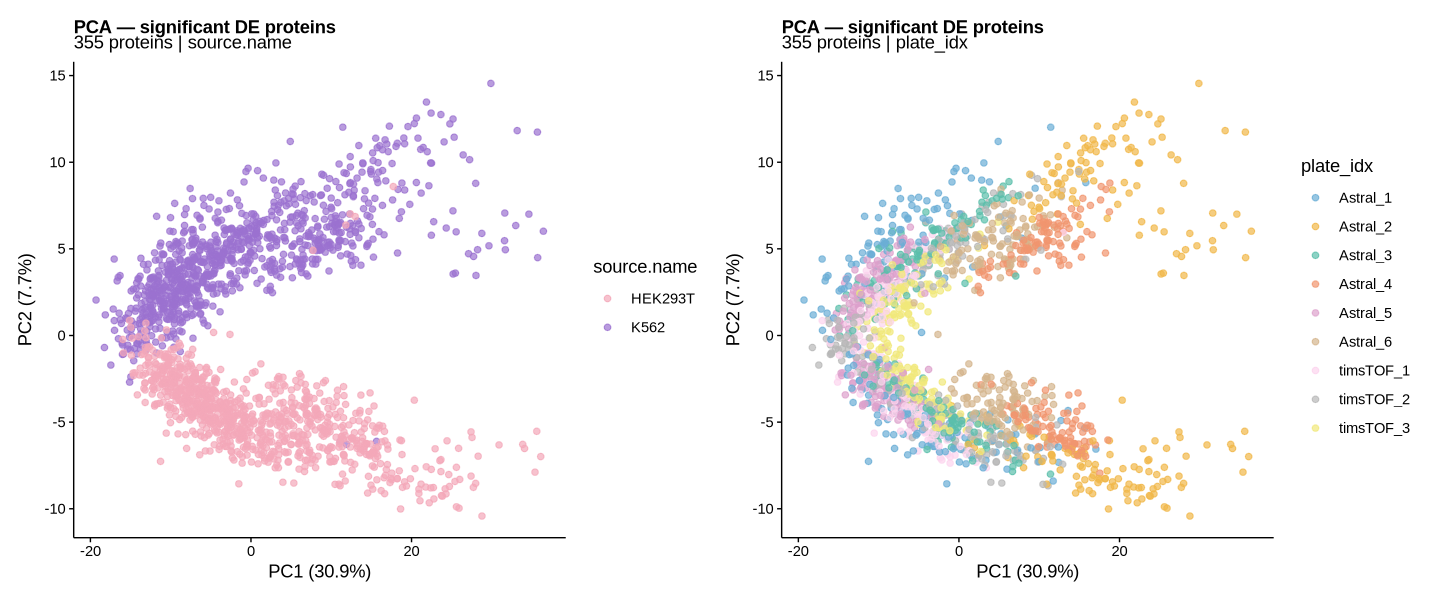

Non-significant proteins sampled: 514
Proteins going into PCA: 154 / 514


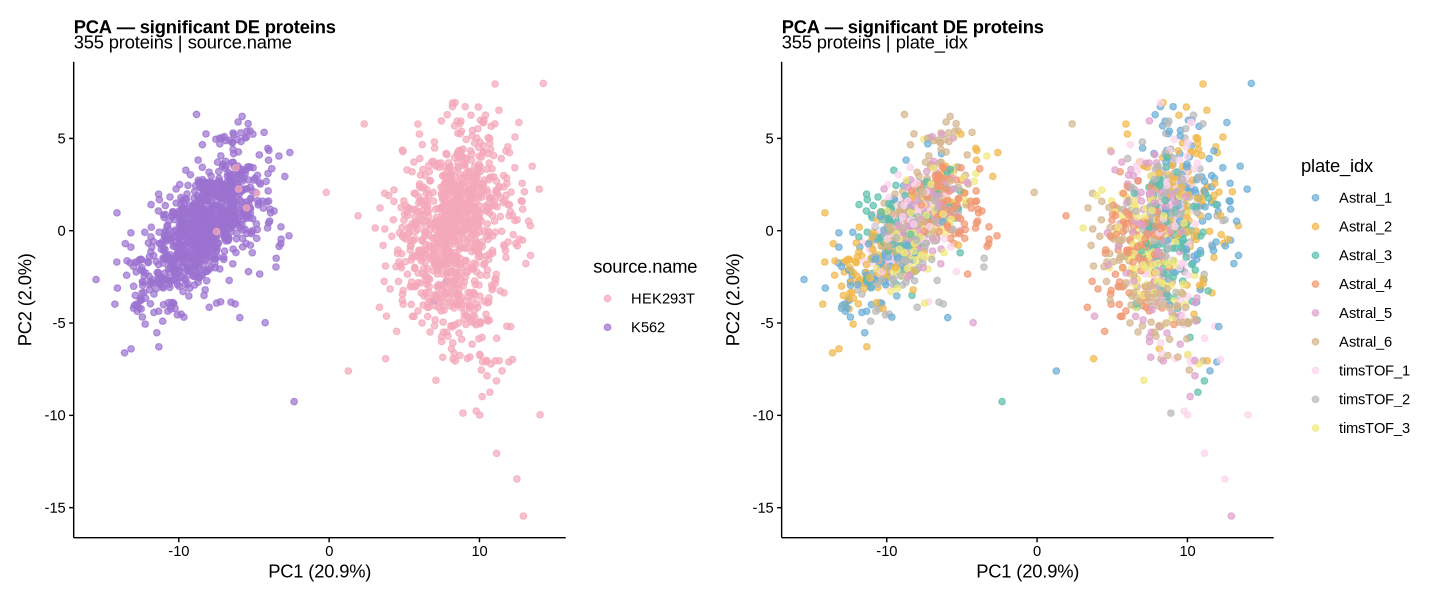

Proteins going into PCA: 154 / 514


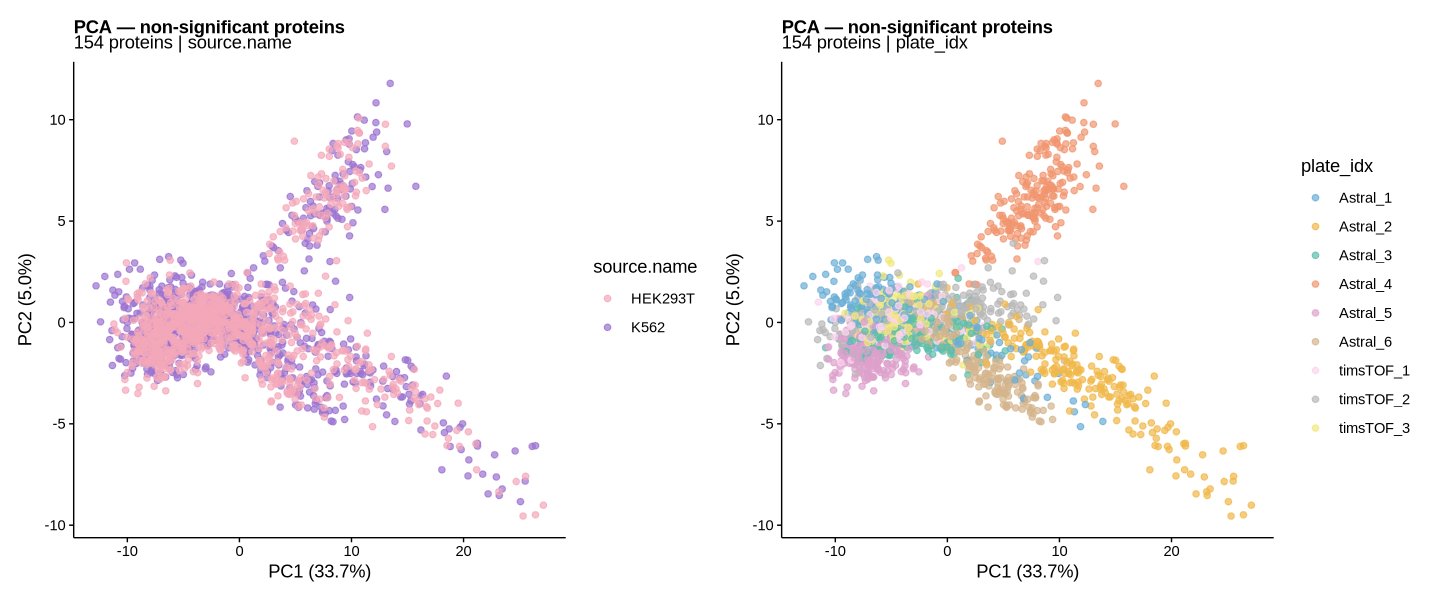

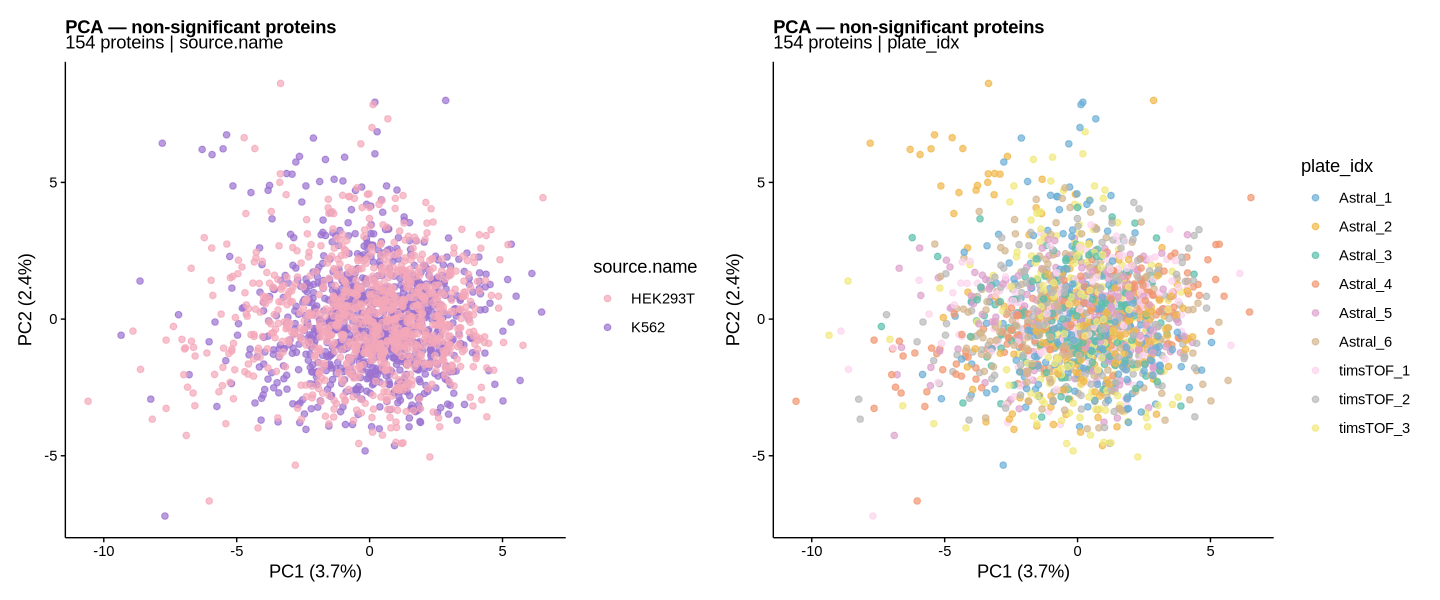

In [27]:
# significant proteins
sig_proteins <- res_all %>%
    filter(adjPval < FDR_THRESHOLD, !is.na(adjPval), abs(logFC) > FC_THRESHOLD) %>%
    pull(protein)
cat(sprintf("Significant proteins: %d\n", length(sig_proteins)))

plot_pca_proteins(
    qf         = qf,
    proteins   = sig_proteins,
    assay_name = "assay",
    title      = "PCA — significant DE proteins",
    save_dir   = FIG_OUT,
    filename   = "pca_sig_proteins_uncorrected",
    show       = TRUE
)
plot_pca_proteins(
    qf         = qf,
    proteins   = sig_proteins,
    assay_name = "batch_corrected",
    title      = "PCA — significant DE proteins",
    save_dir   = FIG_OUT,
    filename   = "pca_sig_proteins_corrected",
    show       = TRUE
)

# random non-significant proteins
n_random     <- length(sig_proteins)  # same n for fair comparison
ns_proteins  <- res_all %>%
    filter(!is.na(adjPval),
           adjPval >= FDR_THRESHOLD,
           abs(logFC) < 0.5) %>%      # low FC threshold
    slice_sample(n = n_random) %>%
    pull(protein)
cat(sprintf("Non-significant proteins sampled: %d\n", length(ns_proteins)))

plot_pca_proteins(
    qf         = qf,
    proteins   = ns_proteins,
    assay_name = "assay",
    title      = "PCA — non-significant proteins",
    save_dir   = FIG_OUT,
    filename   = "pca_ns_proteins_uncorrected",
    show       = TRUE
)
plot_pca_proteins(
    qf         = qf,
    proteins   = ns_proteins,
    assay_name = "batch_corrected",
    title      = "PCA — non-significant proteins",
    save_dir   = FIG_OUT,
    filename   = "pca_ns_proteins_corrected",
    show       = TRUE
)

## 6. Per-plate Analysis

Each plate is analysed independently, simulating a single-lab experiment. This measures how many of the integrated hits a single lab would recover on its own, and reveals whether certain labs are outliers. Two per-plate volcano grids are produced:

1. **Standalone hits** — significant proteins found within each plate alone.
2. **Highlighted hits** — same volcanos with proteins significant in the integrated full model highlighted in orange/purple, showing which integrated hits are independently replicated per lab.

**Formula selection** — most plates use `formula_default` (normalisation + X-position + injection order + acquisition day). Plates with fewer dates (only one acquisition day) or with known issues use a plate-specific formula override defined in `formula_per_plate`.

> **Excluded variables** — `plate_id` is not included in per-plate formulae (no between-plate batch correction needed); `n_proteins` and `medianIntensityProtein` serve as within-plate normalisation.

> **Feature set** - To make the analysis comparable, a 'common feature set' is chosen as shown in the notebook above.

In [15]:
qf

An instance of class QFeatures (type: scp) with 2 sets:

 [1] precursors_log: SingleCellExperiment with 57183 rows and 1864 columns 
 [2] proteins_medianPolish: SingleCellExperiment with 6628 rows and 1864 columns 

In [29]:
qf[, colData(qf)[['COL_PLATE']] == 'Astral_6'][['precursors_log']]$n_proteins

NULL

In [30]:
# ── Isolate Astral_6 ──────────────────────────────────────────────────────────
plate <- "Astral_5"
qf_p <- qf[, colData(qf)[[COL_PLATE]] == plate]

# 1. Basic dimensions
cat("Cells:", ncol(qf_p[["precursors_log"]]), "\n")

# 2. Check all formula variables for NAs and level counts
formula_vars <- c("source.name", "medianIntensityProtein", "n_proteins",
                  "comment.X.position.", "injection_order",
                  "comment.Gradient.time._date")

cd <- as.data.frame(colData(qf_p))
cat("\n── NA counts per variable ──\n")
print(colSums(is.na(cd[, formula_vars])))

cat("\n── Unique levels per variable ──\n")
print(sapply(cd[, formula_vars], function(x) length(unique(x[!is.na(x)]))))

cat("\n── Factor levels (including unused) ──\n")
print(sapply(cd[, formula_vars], function(x) if (is.factor(x)) nlevels(x) else NA))

# 3. Check source.name specifically (needed for contrast)
cat("\n── source.name table ──\n")
print(table(cd$source.name, useNA = "always"))

# 4. Check if K562 and HEK293T are both present
cat("\nK562 present:   ", any(grepl("K562",    cd$source.name)), "\n")
cat("HEK293T present:", any(grepl("HEK293T", cd$source.name)), "\n")

# 5. Check intensity matrix sparsity
assay_mat <- assay(qf_p[["precursors_log"]])
cat("\n── Assay NA proportion ──\n")
cat(round(sum(is.na(assay_mat)) / prod(dim(assay_mat)) * 100, 1), "% missing\n")

# 6. Try aggregation and inspect the resulting colData
# qf_p <- aggregateFeatures(qf_p, i = "precursors_log", fcol = "PG.ProteinAccessions",
#                            name = "proteins_medianPolish_lab",
#                            fun  = MsCoreUtils::medianPolish, na.rm = TRUE)

# 7. Build model matrix to see if it's rank deficien

Cells: 214 

── NA counts per variable ──
                source.name      medianIntensityProtein 
                          0                           0 
                 n_proteins         comment.X.position. 
                          0                           0 
            injection_order comment.Gradient.time._date 
                          0                           0 

── Unique levels per variable ──
                source.name      medianIntensityProtein 
                          2                         214 
                 n_proteins         comment.X.position. 
                        164                          12 
            injection_order comment.Gradient.time._date 
                        214                           4 

── Factor levels (including unused) ──
                source.name      medianIntensityProtein 
                          2                          NA 
                 n_proteins         comment.X.position. 
                         NA  

In [31]:
# ── Isolate Astral_6 ──────────────────────────────────────────────────────────
plate <- "Astral_6"
qf_p <- qf[, colData(qf)[[COL_PLATE]] == plate]

# 1. Basic dimensions
cat("Cells:", ncol(qf_p[["precursors_log"]]), "\n")

# 2. Check all formula variables for NAs and level counts
formula_vars <- c("source.name", "medianIntensityProtein", "n_proteins",
                  "comment.X.position.", "injection_order",
                  "comment.Gradient.time._date")

cd <- as.data.frame(colData(qf_p))
cat("\n── NA counts per variable ──\n")
print(colSums(is.na(cd[, formula_vars])))

cat("\n── Unique levels per variable ──\n")
print(sapply(cd[, formula_vars], function(x) length(unique(x[!is.na(x)]))))

cat("\n── Factor levels (including unused) ──\n")
print(sapply(cd[, formula_vars], function(x) if (is.factor(x)) nlevels(x) else NA))

# 3. Check source.name specifically (needed for contrast)
cat("\n── source.name table ──\n")
print(table(cd$source.name, useNA = "always"))

# 4. Check if K562 and HEK293T are both present
cat("\nK562 present:   ", any(grepl("K562",    cd$source.name)), "\n")
cat("HEK293T present:", any(grepl("HEK293T", cd$source.name)), "\n")

# 5. Check intensity matrix sparsity
assay_mat <- assay(qf_p[["precursors_log"]])
cat("\n── Assay NA proportion ──\n")
cat(round(sum(is.na(assay_mat)) / prod(dim(assay_mat)) * 100, 1), "% missing\n")

Cells: 195 

── NA counts per variable ──
                source.name      medianIntensityProtein 
                          0                           0 
                 n_proteins         comment.X.position. 
                          0                           0 
            injection_order comment.Gradient.time._date 
                          0                           0 

── Unique levels per variable ──
                source.name      medianIntensityProtein 
                          2                         195 
                 n_proteins         comment.X.position. 
                        179                          12 
            injection_order comment.Gradient.time._date 
                        195                           1 

── Factor levels (including unused) ──
                source.name      medianIntensityProtein 
                          2                          NA 
                 n_proteins         comment.X.position. 
                         NA  

In [32]:
# ── Parameters ────────────────────────────────────────────────────────────────
formula_default <- ~ 0 + source.name +
    medianIntensityProtein + n_proteins +
    comment.X.position. + injection_order +
    (1 | comment.Gradient.time._date)

formula_per_plate <- list()  # plate-specific overrides if needed

# common feature set from filtered integrated model
feature_set <- rownames(assay(qf_filtered, "proteins_medianPolish"))

# ── Helper: drop date random effect if < 2 levels ────────────────────────────
drop_date_re <- function(formula) {
    as.formula(sub("\\+ \\(1 \\| comment\\.Gradient\\.time\\._date\\)", "",
                   deparse(formula)))
}

# ── Helper: fit one plate ─────────────────────────────────────────────────────
fit_plate <- function(plate, qf, feature_set) {
    cat(sprintf("── %s ──\n", plate))
    flush.console()

    # subset to plate
    qf_p   <- qf[, colData(qf)[[COL_PLATE]] == plate]
    n_cells <- ncol(qf_p[["precursors_log"]])

    # aggregate precursors to proteins
    qf_p <- tryCatch(
        aggregateFeatures(qf_p, i = "precursors_log", fcol = "PG.ProteinAccessions",
                          name = "proteins_medianPolish_lab",
                          fun  = MsCoreUtils::medianPolish, na.rm = TRUE),
        error = function(e) {
            cat(sprintf("  aggregation failed: %s\n", e$message))
            NULL
        }
    )
    if (is.null(qf_p)) return(NULL)

    # restrict to common feature set
    common <- intersect(feature_set, rownames(qf_p[["proteins_medianPolish_lab"]]))
    qf_p[["proteins_medianPolish_lab"]] <- qf_p[["proteins_medianPolish_lab"]][common, ]

    n_proteins <- nrow(qf_p[["proteins_medianPolish_lab"]])
    n_dates    <- nlevels(factor(colData(qf_p)$comment.Gradient.time._date))
    cat(sprintf("  cells=%d  proteins=%d  dates=%d\n", n_cells, n_proteins, n_dates))

    # select formula
    formula_use <- if (plate %in% names(formula_per_plate)) {
        cat("  using plate-specific formula\n")
        formula_per_plate[[plate]]
    } else if (n_dates < 2) {
        cat("  date random effect dropped (< 2 levels)\n")
        drop_date_re(formula_default)
    } else {
        formula_default
    }

    # fit model
    qf_p <- tryCatch(
        msqrob(qf_p, i = "proteins_medianPolish_lab",
               formula         = formula_use,
               modelColumnName = "msqrob_lab",
               ridge = TRUE, robust = TRUE),
        error = function(e) {
            cat(sprintf("  model failed: %s\n", e$message))
            NULL
        }
    )
    if (is.null(qf_p)) return(NULL)

    # extract contrast parameters
    params   <- tryCatch(
        getCoef(rowData(qf_p[["proteins_medianPolish_lab"]])$msqrob_lab[[1]]),
        error = function(e) NULL
    )
    if (is.null(params)) { cat("  could not extract coefficients\n"); return(NULL) }

    k562_par <- grep("K562",    names(params), value = TRUE)
    hek_par  <- grep("HEK293T", names(params), value = TRUE)
    if (!length(k562_par) || !length(hek_par)) {
        cat("  source.name parameters not found — skipping\n")
        return(NULL)
    }

    # hypothesis test
    contr_str <- sprintf("%s - %s = 0", k562_par[1], hek_par[1])
    L         <- makeContrast(contr_str, parameterNames = c(k562_par[1], hek_par[1]))

    qf_p <- tryCatch(
        hypothesisTest(qf_p, i = "proteins_medianPolish_lab", contrast = L,
                       modelColumn             = "msqrob_lab",
                       resultsColumnNamePrefix = "lab_dea_",
                       adjust.method           = "BH"),
        error = function(e) {
            cat(sprintf("  hypothesis test failed: %s\n", e$message))
            NULL
        }
    )
    if (is.null(qf_p)) return(NULL)

    # extract results
    result_col <- paste0("lab_dea_", gsub(" = 0", "", contr_str))
    res <- tryCatch(
        rowData(qf_p[["proteins_medianPolish_lab"]])[[result_col]] %>%
            as.data.frame() %>%
            rownames_to_column("protein") %>%
            mutate(plate = plate) %>%
            arrange(pval),
        error = function(e) NULL
    )
    if (is.null(res)) return(NULL)

    n_sig <- sum(res$adjPval < FDR_THRESHOLD & abs(res$logFC) > FC_THRESHOLD, na.rm = TRUE)
    cat(sprintf("  significant: %d / %d\n\n", n_sig, nrow(res)))

    write.csv(res, file.path(RESULTS_DIR, "per_plate",
                             sprintf("dea_%s.csv", gsub("[/ ]", "_", plate))),
              row.names = FALSE)
    res
}

# ── Run per-plate fitting ─────────────────────────────────────────────────────
plates <- levels(colData(qf)[[COL_PLATE]])
cat(sprintf("Running per-plate msqrob for %d plates on %d common proteins...\n\n",
            length(plates), length(feature_set)))

results_per_plate <- setNames(
    lapply(plates, fit_plate, qf = qf, feature_set = feature_set),
    plates
)
results_per_plate <- Filter(Negate(is.null), results_per_plate)

cat(sprintf("Successfully fitted: %d / %d plates\n", length(results_per_plate), length(plates)))

# ── Combine and save ──────────────────────────────────────────────────────────
res_per_plate_all <- bind_rows(results_per_plate)
write.csv(res_per_plate_all,
          file.path(RESULTS_DIR, "per_plate", "combined.csv"), row.names = FALSE)
saveRDS(results_per_plate,
        file.path(RESULTS_DIR, "per_plate", "results_per_plate.rds"))

Running per-plate msqrob for 9 plates on 2153 common proteins...

── Astral_1 ──


Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.

Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warni

  cells=210  proteins=2153  dates=5


Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zm

  significant: 384 / 2153

── Astral_2 ──


Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.

Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warni

... (27 outputs left out)

Your quantitative and row data contain missing values. Please read the
relevant section(s) in the aggregateFeatures manual page regarding the
effects of missing values on data aggregation.

Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warning message in stats::medpolish(x, trace.iter = verbose, ...):
“medpolish() did not converge in 10 iterations”
Warni

  cells=201  proteins=2153  dates=5


Warning message:
“'experiments' dropped; see 'drops()'”
Warning message:
“Ignoring redundant column names in 'colData(x)':”
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zm

  significant: 238 / 2153

Successfully fitted: 9 / 9 plates


In [33]:
plate <- "Astral_6"
qf_p <- qf[, colData(qf)[[COL_PLATE]] == plate]
cd   <- as.data.frame(colData(qf_p))

# 1. Check injection_order specifically
cat("── injection_order ──\n")
cat("Unique values:", length(unique(cd$injection_order)), "\n")
cat("NAs:", sum(is.na(cd$injection_order)), "\n")
print(head(sort(unique(cd$injection_order)), 20))

# 2. Check ALL variables in the formula for NAs
formula_vars <- c("source.name", "medianIntensityProtein", "n_proteins",
                  "comment.X.position.", "injection_order", 
                  "comment.Gradient.time._date")

cat("\n── NA counts ──\n")
print(colSums(is.na(cd[, intersect(formula_vars, names(cd))])))

cat("\n── Unique value counts ──\n")
print(sapply(cd[, intersect(formula_vars, names(cd))], 
             function(x) length(unique(x[!is.na(x)]))))

# 3. Check for Inf or NaN (these also break logical checks)
cat("\n── Inf/NaN counts ──\n")
print(sapply(cd[, intersect(formula_vars, names(cd))], function(x) {
    if (is.numeric(x)) sum(!is.finite(x[!is.na(x)])) else 0
}))

# 4. Try building the model matrix explicitly
n_dates <- length(unique(cd$comment.Gradient.time._date))
formula_use <- if (n_dates < 2) drop_date_re(formula_default) else formula_default
cat("\n── Formula used ──\n")
print(formula_use)

# lme4-style formula → fixed effects only for model.matrix check
formula_fixed <- as.formula(
    gsub("\\+ \\(1 \\| [^)]+\\)", "", deparse(formula_use))
)
mm <- tryCatch(
    model.matrix(formula_fixed, data = cd),
    error = function(e) { cat("model.matrix failed:", e$message, "\n"); NULL }
)
if (!is.null(mm)) {
    cat("Model matrix dims:", nrow(mm), "x", ncol(mm), "\n")
    cat("Rank:", qr(mm)$rank, "\n")
    cat("Rank deficient?", qr(mm)$rank < ncol(mm), "\n")
}

── injection_order ──
Unique values: 195 
NAs: 0 
 [1] 0.1096606 0.1122715 0.1148825 0.1174935 0.1201044 0.1227154 0.1253264
 [8] 0.1279373 0.1305483 0.1331593 0.1357702 0.1383812 0.1409922 0.1436031
[15] 0.1462141 0.1488251 0.1514360 0.1540470 0.1566580 0.1592689

── NA counts ──
                source.name      medianIntensityProtein 
                          0                           0 
                 n_proteins         comment.X.position. 
                          0                           0 
            injection_order comment.Gradient.time._date 
                          0                           0 

── Unique value counts ──
                source.name      medianIntensityProtein 
                          2                         195 
                 n_proteins         comment.X.position. 
                        179                          12 
            injection_order comment.Gradient.time._date 
                        195                           1 

── Inf

Warning message in formula.character(object, env = baseenv()):
“Using formula(x) is deprecated when x is a character vector of length > 1.
  Consider formula(paste(x, collapse = " ")) instead.”



── Formula used ──
~0 + source.name + medianIntensityProtein + n_proteins + comment.X.position. + 
    injection_order
<environment: 0x55846fa79d10>


Warning message in formula.character(object, env = baseenv()):
“Using formula(x) is deprecated when x is a character vector of length > 1.
  Consider formula(paste(x, collapse = " ")) instead.”


Model matrix dims: 195 x 6 
Rank: 6 
Rank deficient? FALSE 


### 6.2 Per-plate Volcano Grid

One volcano per plate on shared axes, showing how many proteins each lab identifies independently.

In [41]:
source("../../SCI_R/msqrob_plots.R")


Upregulated proteins per model:
Integrated   Astral_1   Astral_2   Astral_3   Astral_4   Astral_5   Astral_6 
       259        190        176        187         69        131        135 
 timsTOF_1  timsTOF_2  timsTOF_3 
       157        146         97 

Downregulated proteins per model:
Integrated   Astral_1   Astral_2   Astral_3   Astral_4   Astral_5   Astral_6 
       255        194        209        189         97        140        147 
 timsTOF_1  timsTOF_2  timsTOF_3 
       172        177        141 


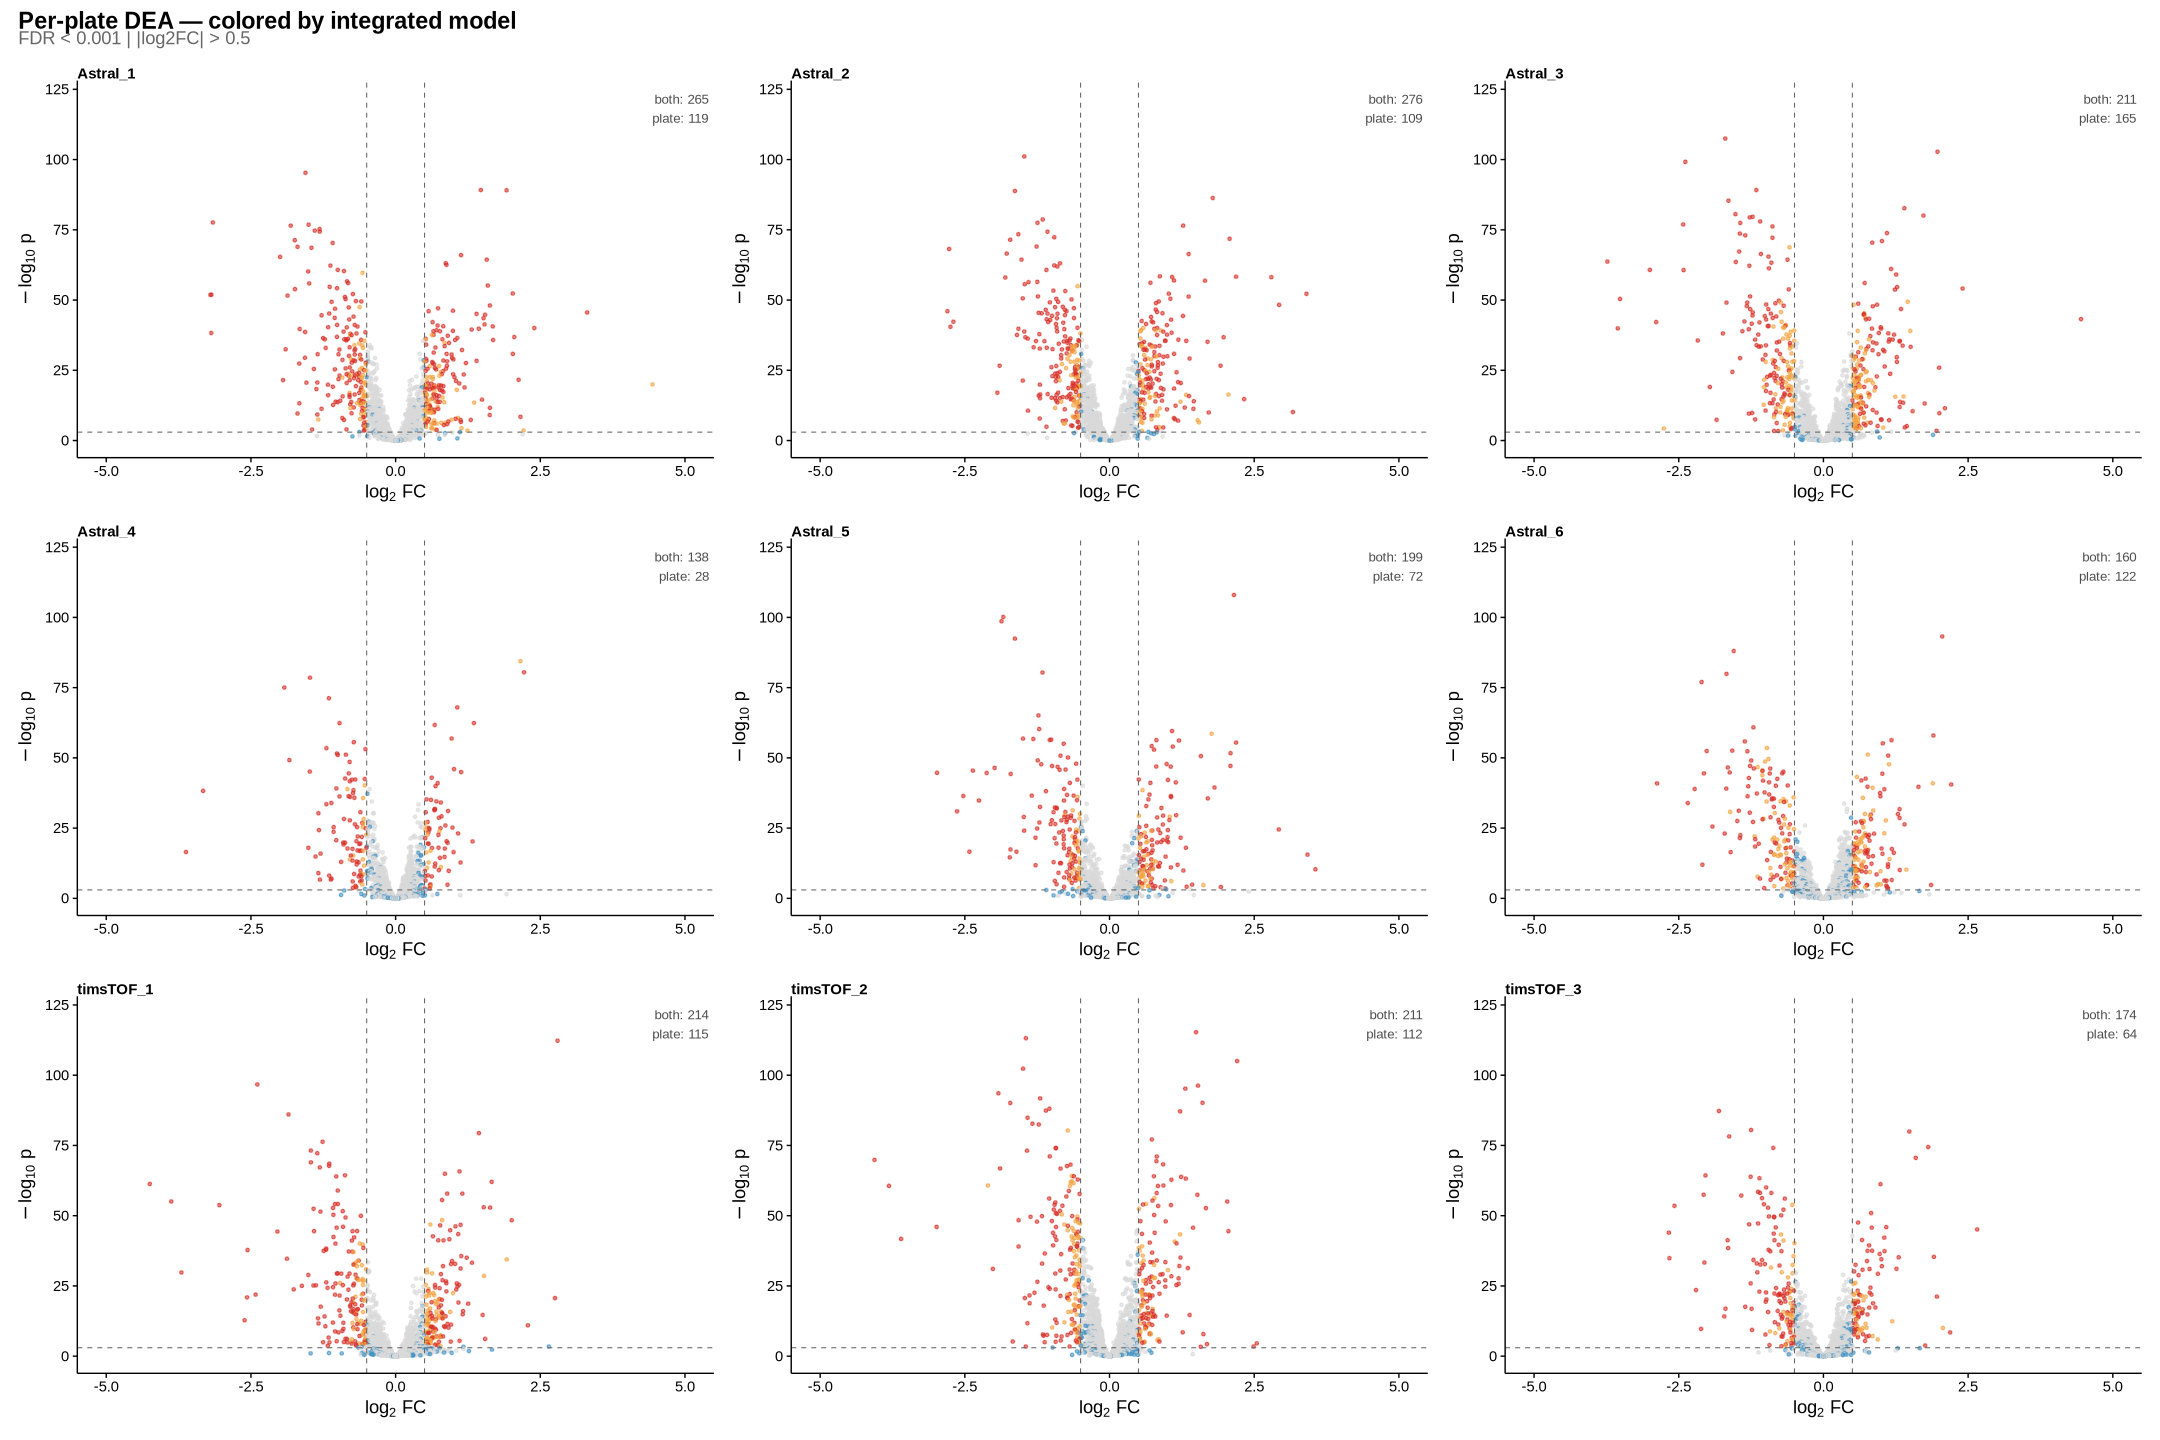

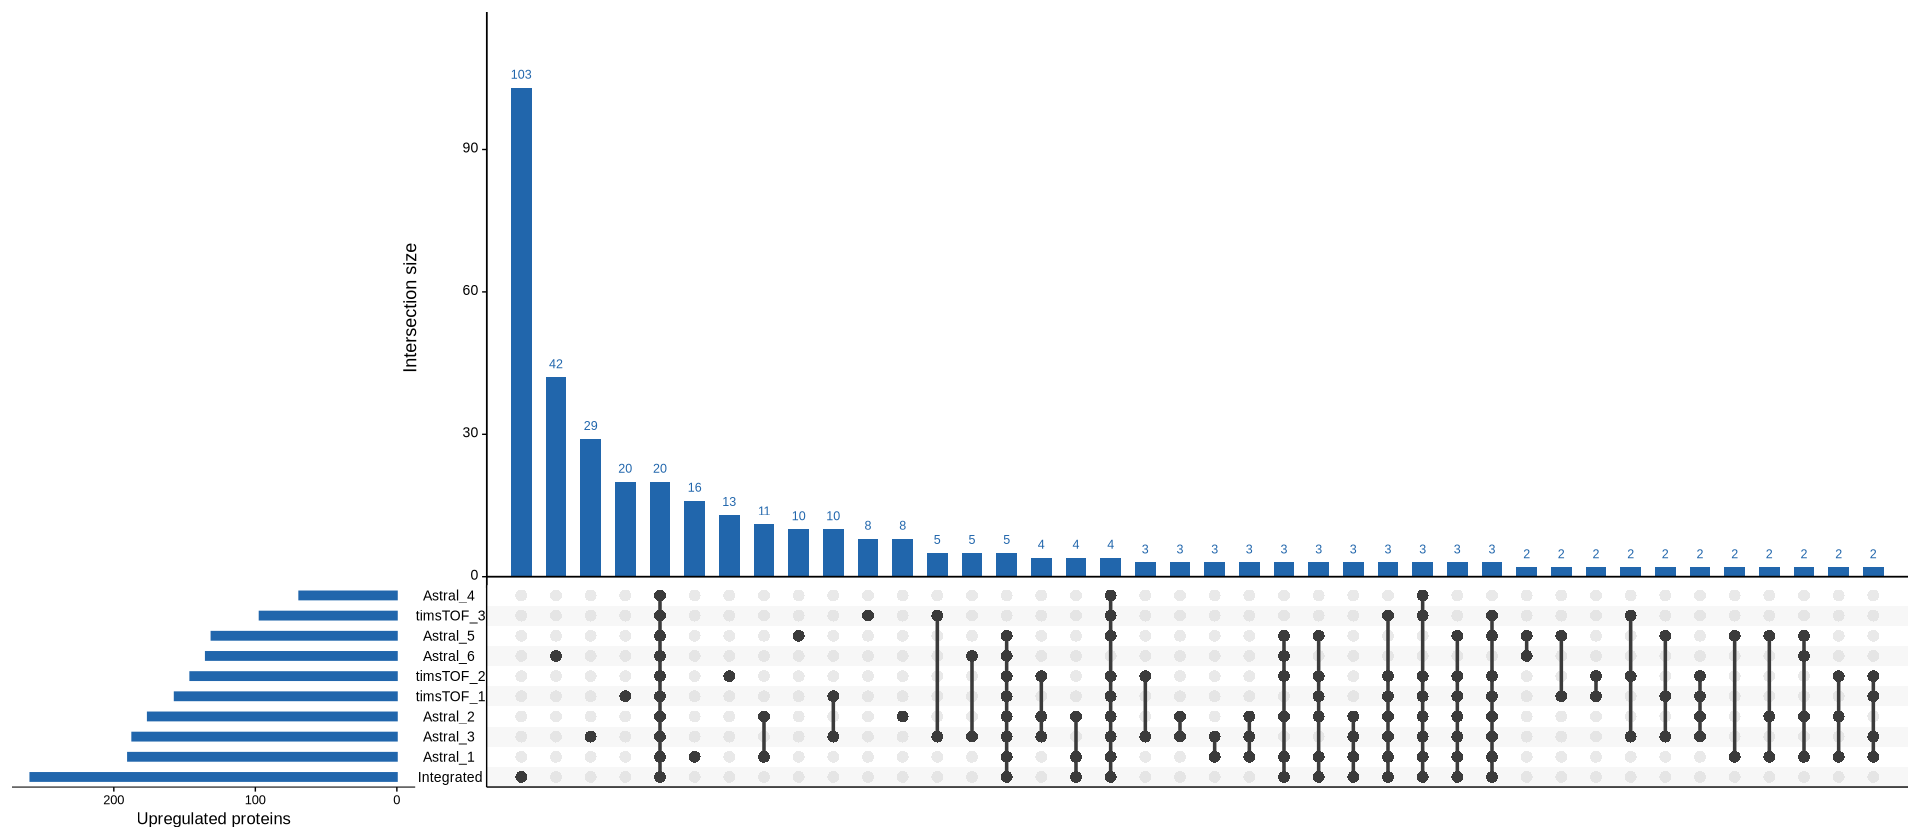

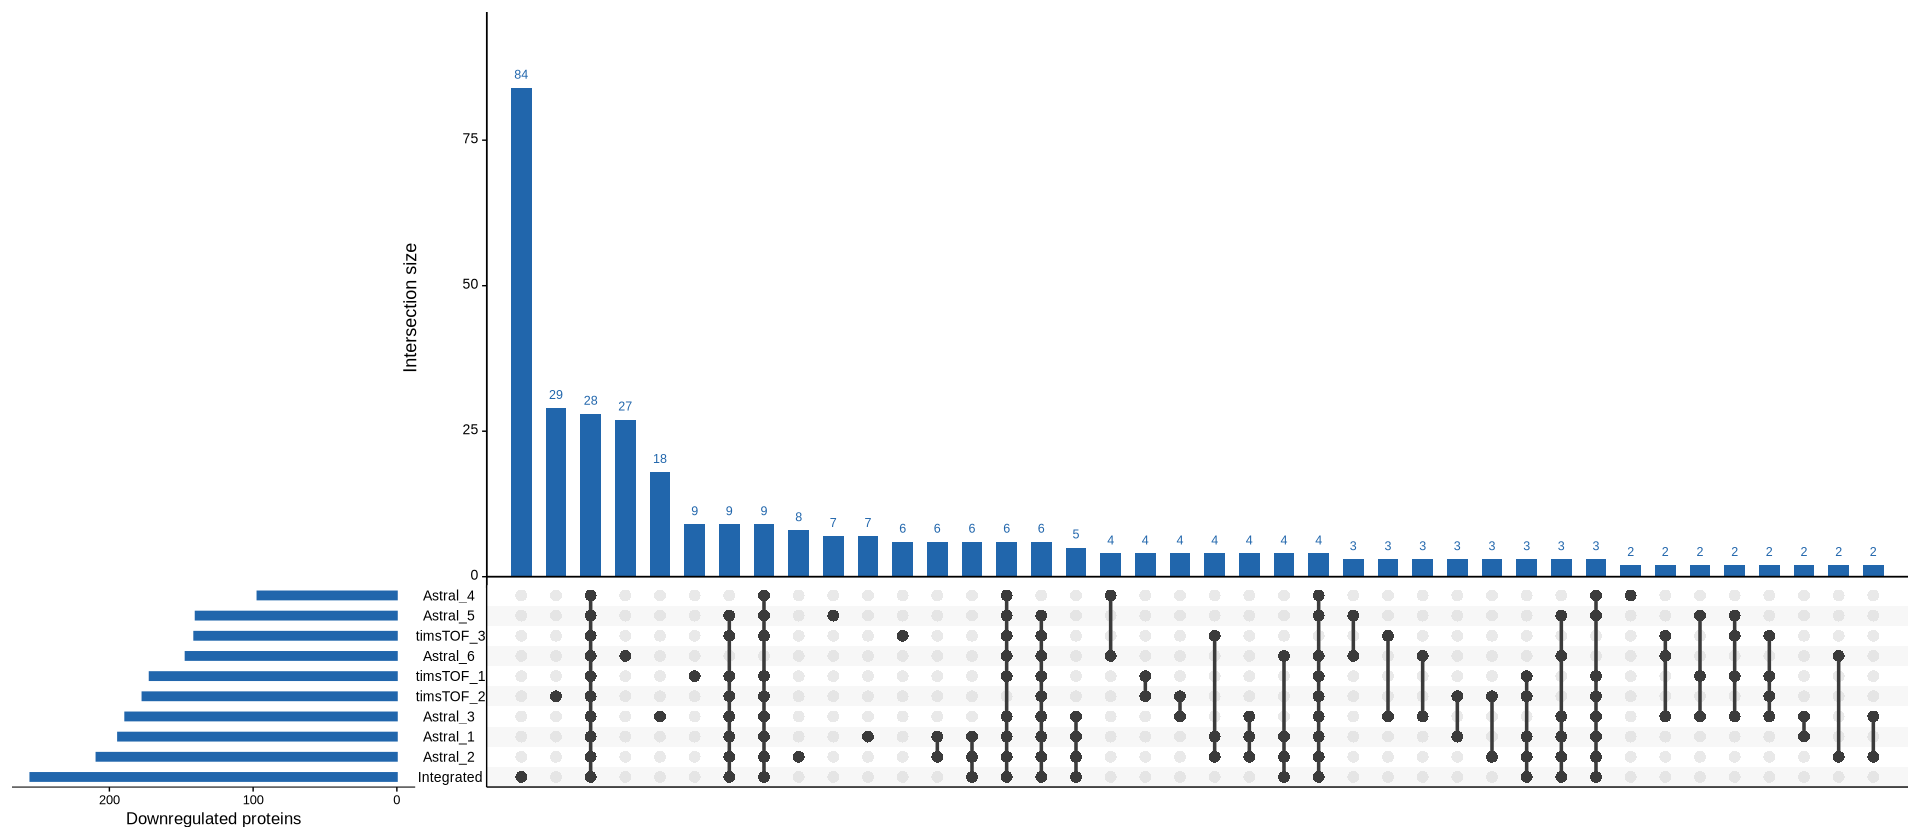

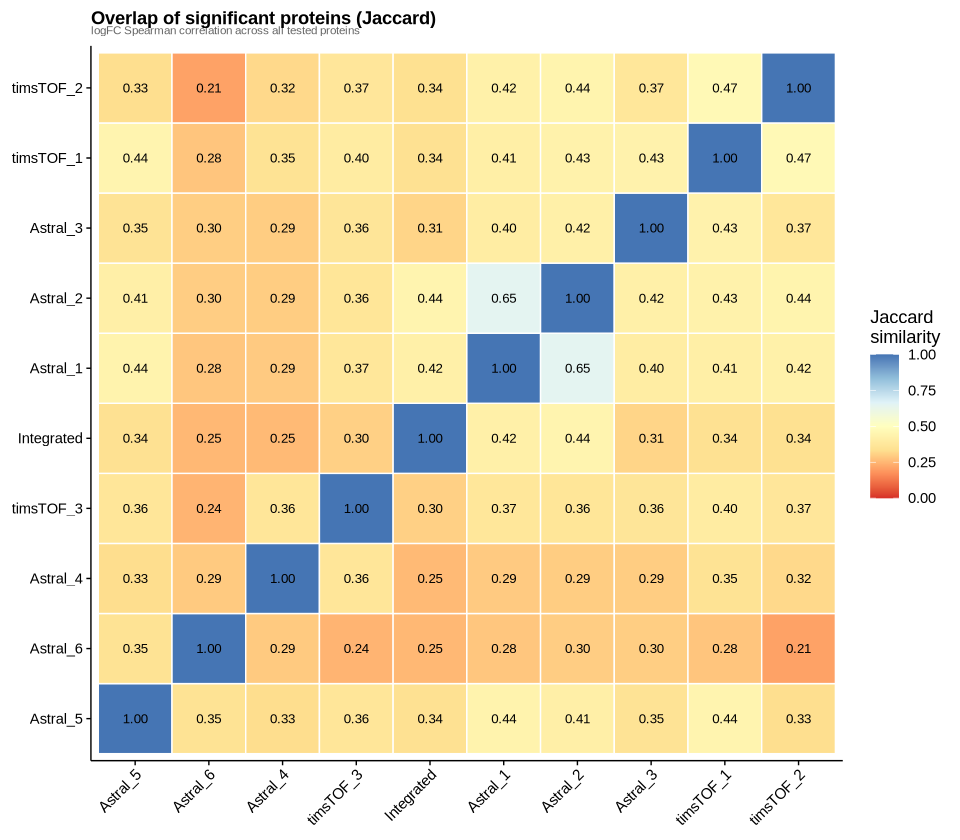

logFC correlation computed on 988 proteins (union of significant)


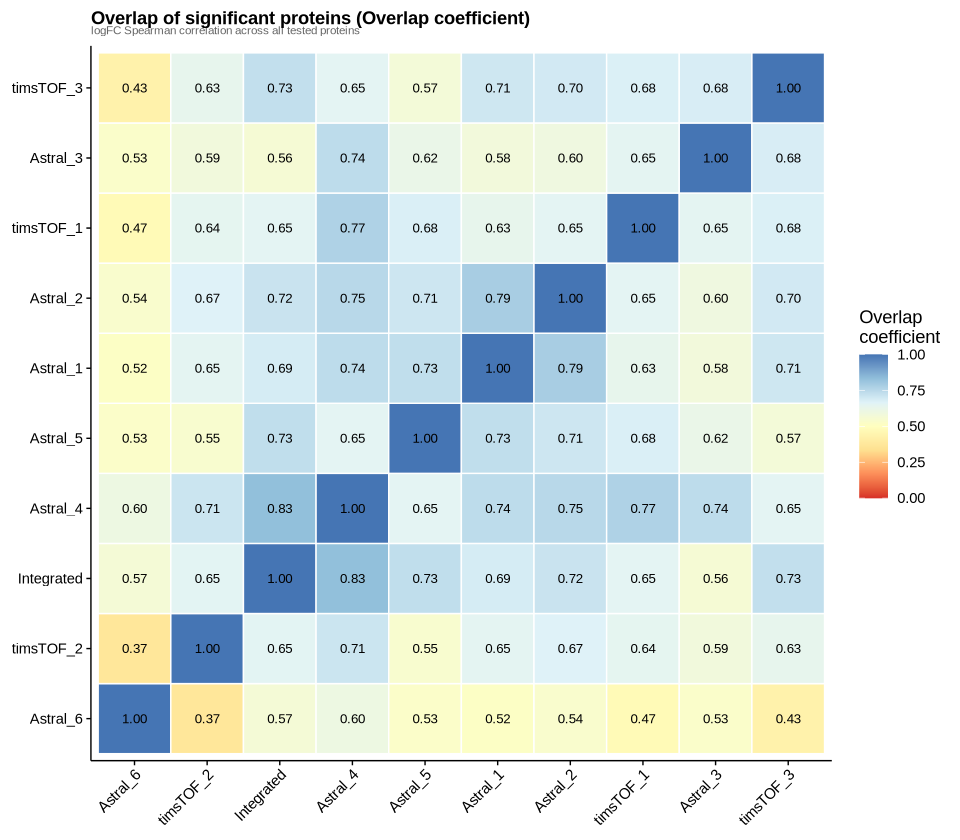

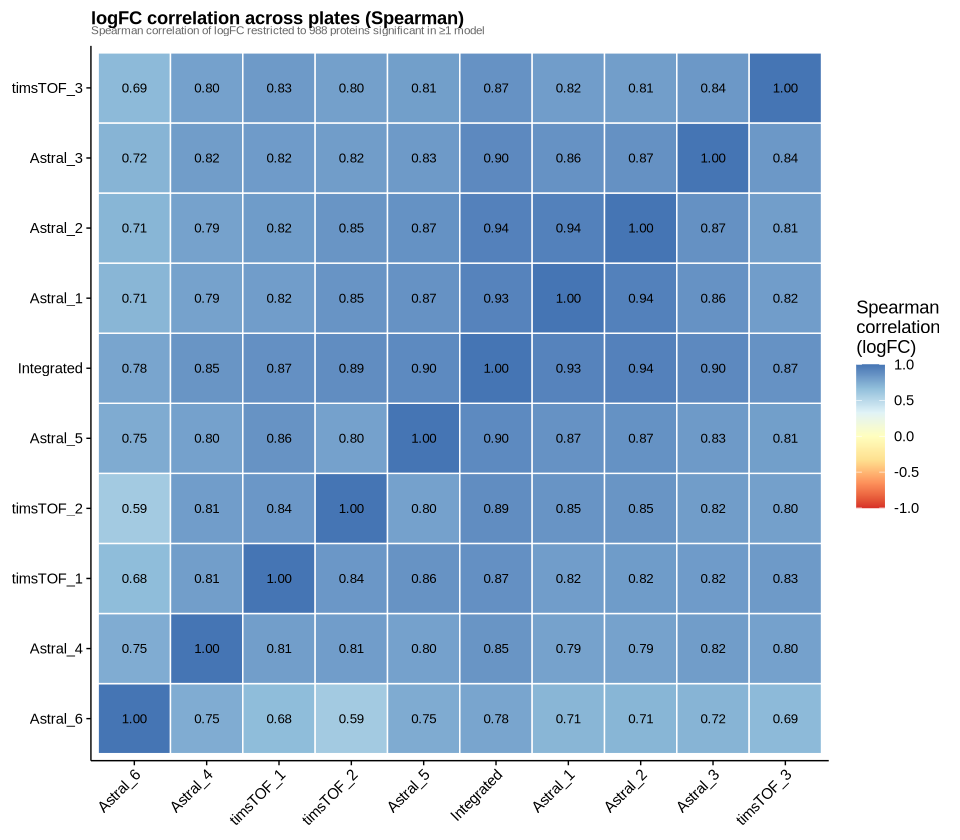

In [43]:
plot_volcano_grid_per_plate(
    results_per_plate = results_per_plate,
    res_integrated    = res_all,
    fc_threshold      = .5,
    save_dir          = FIG_OUT,
    show              = TRUE
)

plot_upset_per_plate(
    results_per_plate = results_per_plate,
    res_integrated    = res_all,
    save_dir          = FIG_OUT,
    show              = TRUE
)

plot_overlap_heatmap(
    results_per_plate,
    res_all,
    save_dir = FIG_OUT,
    metric = "jaccard",
    filename = 'overlap_heatmap_jaccard.png'
)
plot_overlap_heatmap(
    results_per_plate,
    res_all,
    save_dir = FIG_OUT,
    metric = "overlap",
    filename = 'overlap_heatmap_overlap.png'
)
plot_overlap_heatmap(
    results_per_plate,
    res_all,
    save_dir = FIG_OUT,
    metric = "logfc_cor",
    filename = 'overlap_heatmap_logfc_cor.png'
)

## 7. GSEA

In [57]:
library(fgsea)
library(msigdbr)
library(biomaRt)

# ── Load pathways ──────────────────────────────────────────────────────────────
msig     <- msigdbr(species = "Homo sapiens", category = "C5")
pathways <- split(msig$gene_symbol, msig$gs_name)
pathways <- lapply(pathways, unique)

# ── Background: ALL proteins (including those with NA pval) ───────────────────
all_proteins <- unique(unlist(strsplit(
    Reduce(union, lapply(results_per_plate, function(r) r$protein)), ";"
)))

# ── Map UniProt → gene symbol ──────────────────────────────────────────────────
mart <- useMart("ensembl", dataset = "hsapiens_gene_ensembl")

mapping <- getBM(
    attributes = c("uniprotswissprot", "hgnc_symbol"),
    filters    = "uniprotswissprot",
    values     = all_proteins,
    mart       = mart
) %>%
    filter(hgnc_symbol != "", uniprotswissprot != "") %>%
    distinct()

cat("Mapped:", nrow(mapping), "UniProt → gene symbol pairs\n")
cat("Unmapped proteins:", sum(!all_proteins %in% mapping$uniprotswissprot), "\n")

# ── Filter pathways to background ONCE ────────────────────────────────────────
bg_symbols  <- unique(mapping$hgnc_symbol)
pathways_bg <- lapply(pathways, function(p) intersect(p, bg_symbols))
pathways_bg <- pathways_bg[sapply(pathways_bg, length) >= 5]

cat("Background gene symbols:", length(bg_symbols), "\n")
cat("Pathways after background filtering:", length(pathways_bg), "\n")

# ── Helper: run GSEA for one plate ────────────────────────────────────────────
run_gsea_plate <- function(res, pathways, min_size = 5, max_size = 500) {

    ranked <- res %>%
        # NA filter only affects ranked list, not background
        filter(!is.na(pval), !is.na(logFC), is.finite(logFC)) %>%
        mutate(protein_single = strsplit(protein, ";")) %>%
        unnest(protein_single) %>%
        group_by(protein_single) %>%
        slice_min(pval, n = 1, with_ties = FALSE) %>%
        ungroup() %>%
        left_join(mapping, by = c("protein_single" = "uniprotswissprot")) %>%
        filter(!is.na(hgnc_symbol)) %>%
        group_by(hgnc_symbol) %>%
        slice_min(pval, n = 1, with_ties = FALSE) %>%
        ungroup() %>%
        mutate(rank = sign(logFC) * -log10(pval + 1e-300)) %>%
        arrange(desc(rank))

    ranks <- setNames(ranked$rank, ranked$hgnc_symbol)

    cat(sprintf("  ranked proteins: %d / background: %d\n",
                length(ranks), length(bg_symbols)))

    stopifnot(all(is.finite(ranks)))
    stopifnot(!anyDuplicated(names(ranks)))

    # further restrict pathways to genes present in ranks
    pathways_f <- lapply(pathways, function(p) intersect(p, names(ranks)))
    pathways_f <- pathways_f[sapply(pathways_f, length) >= min_size]

    cat(sprintf("  pathways after filtering to ranked genes: %d\n",
                length(pathways_f)))

    set.seed(42)
    fgsea_res <- fgseaMultilevel(
        pathways    = pathways_f,
        stats       = ranks,
        minSize     = min_size,
        maxSize     = max_size,
        nPermSimple = 10000,
        scoreType   = "std"
    )

    list(
        result = fgsea_res %>% as_tibble() %>% arrange(padj, pval),
        ranks  = ranks
    )
}

# ── Run across all plates ──────────────────────────────────────────────────────
gsea_results <- lapply(results_per_plate, function(res) {
    tryCatch(
        run_gsea_plate(res, pathways_bg),
        error = function(e) { cat("GSEA failed:", e$message, "\n"); NULL }
    )
})

# ── Combine and save ───────────────────────────────────────────────────────────
gsea_combined <- bind_rows(
    lapply(gsea_results, function(x) if (!is.null(x)) x$result else NULL),
    .id = "plate"
)

write.csv(
    gsea_combined %>% dplyr::select(-leadingEdge),
    file.path(RESULTS_DIR, "gsea_per_plate.csv"),
    row.names = FALSE
)
saveRDS(gsea_results, file.path(RESULTS_DIR, "gsea_per_plate.rds"))

Mapped: 2186 UniProt → gene symbol pairs
Unmapped proteins: 11 
Background gene symbols: 2185 
Pathways after background filtering: 6443 
  ranked proteins: 2116 / background: 2185
  pathways after filtering to ranked genes: 6318


Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (2.03% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”


  ranked proteins: 2171 / background: 2185
  pathways after filtering to ranked genes: 6420


Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (1.98% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”


  ranked proteins: 1831 / background: 2185
  pathways after filtering to ranked genes: 5814


Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (2.35% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”


... (8 outputs left out)

  ranked proteins: 2094 / background: 2185
  pathways after filtering to ranked genes: 6289


Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (2.05% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”


  ranked proteins: 2037 / background: 2185
  pathways after filtering to ranked genes: 6233


Warning message in preparePathwaysAndStats(pathways, stats, minSize, maxSize, gseaParam, :
“There are ties in the preranked stats (2.06% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”


── Plotting Astral_1 ──
  No significant pathways (padj < 0.05) for Astral_1
── Plotting Astral_2 ──


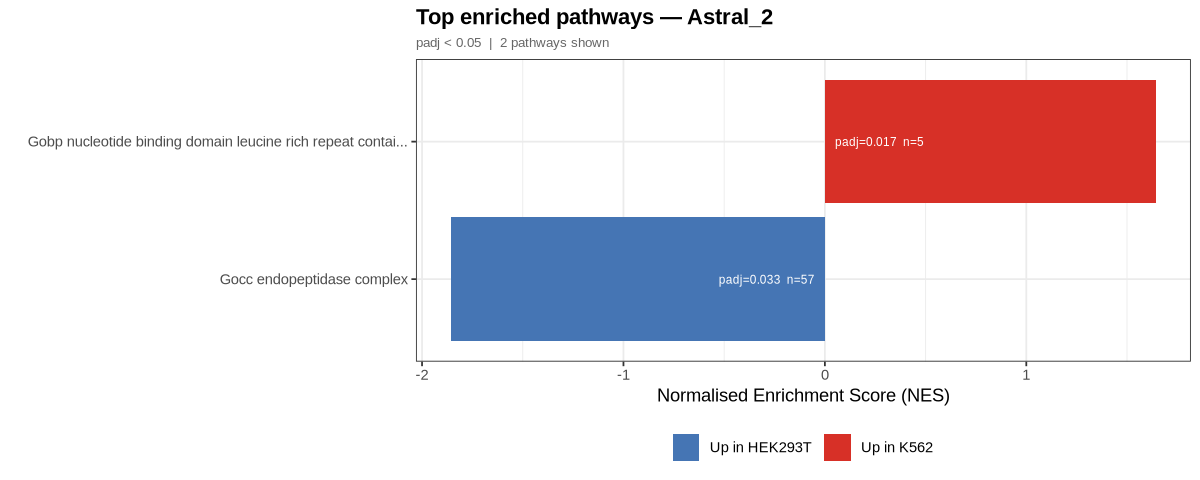

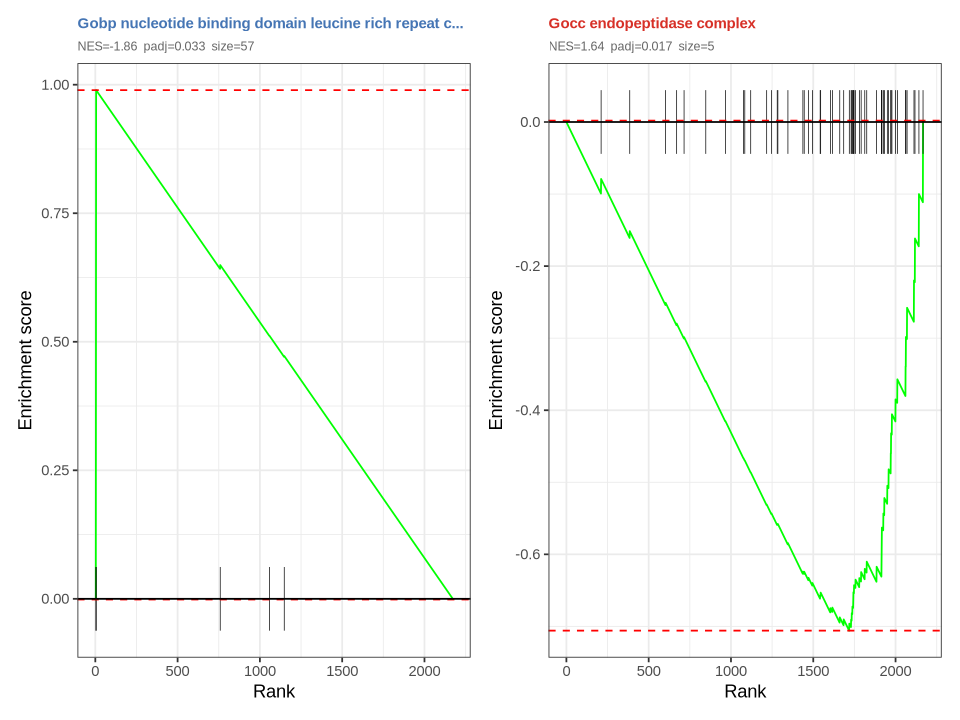

── Plotting Astral_3 ──
  No significant pathways (padj < 0.05) for Astral_3
── Plotting Astral_4 ──


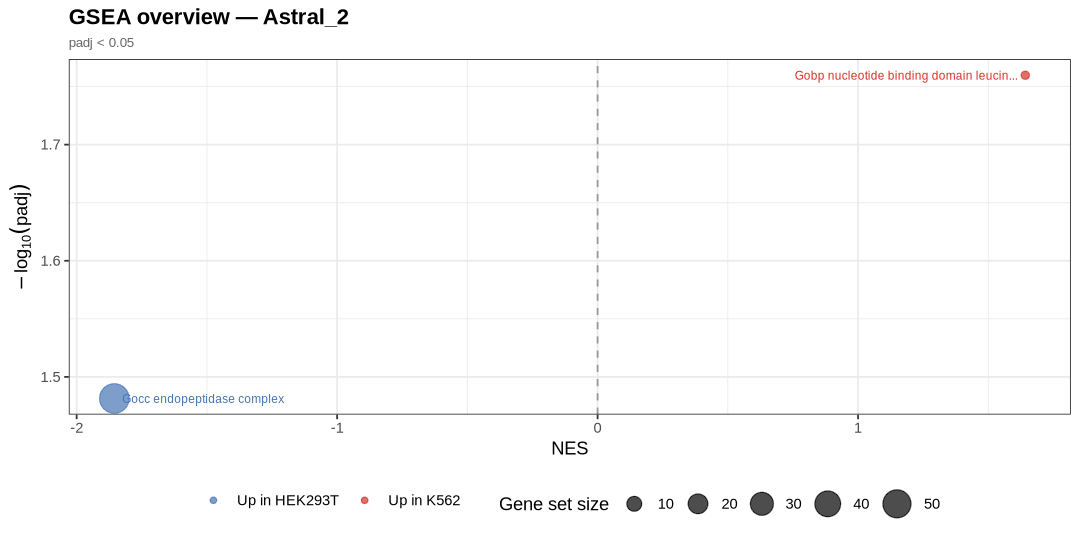

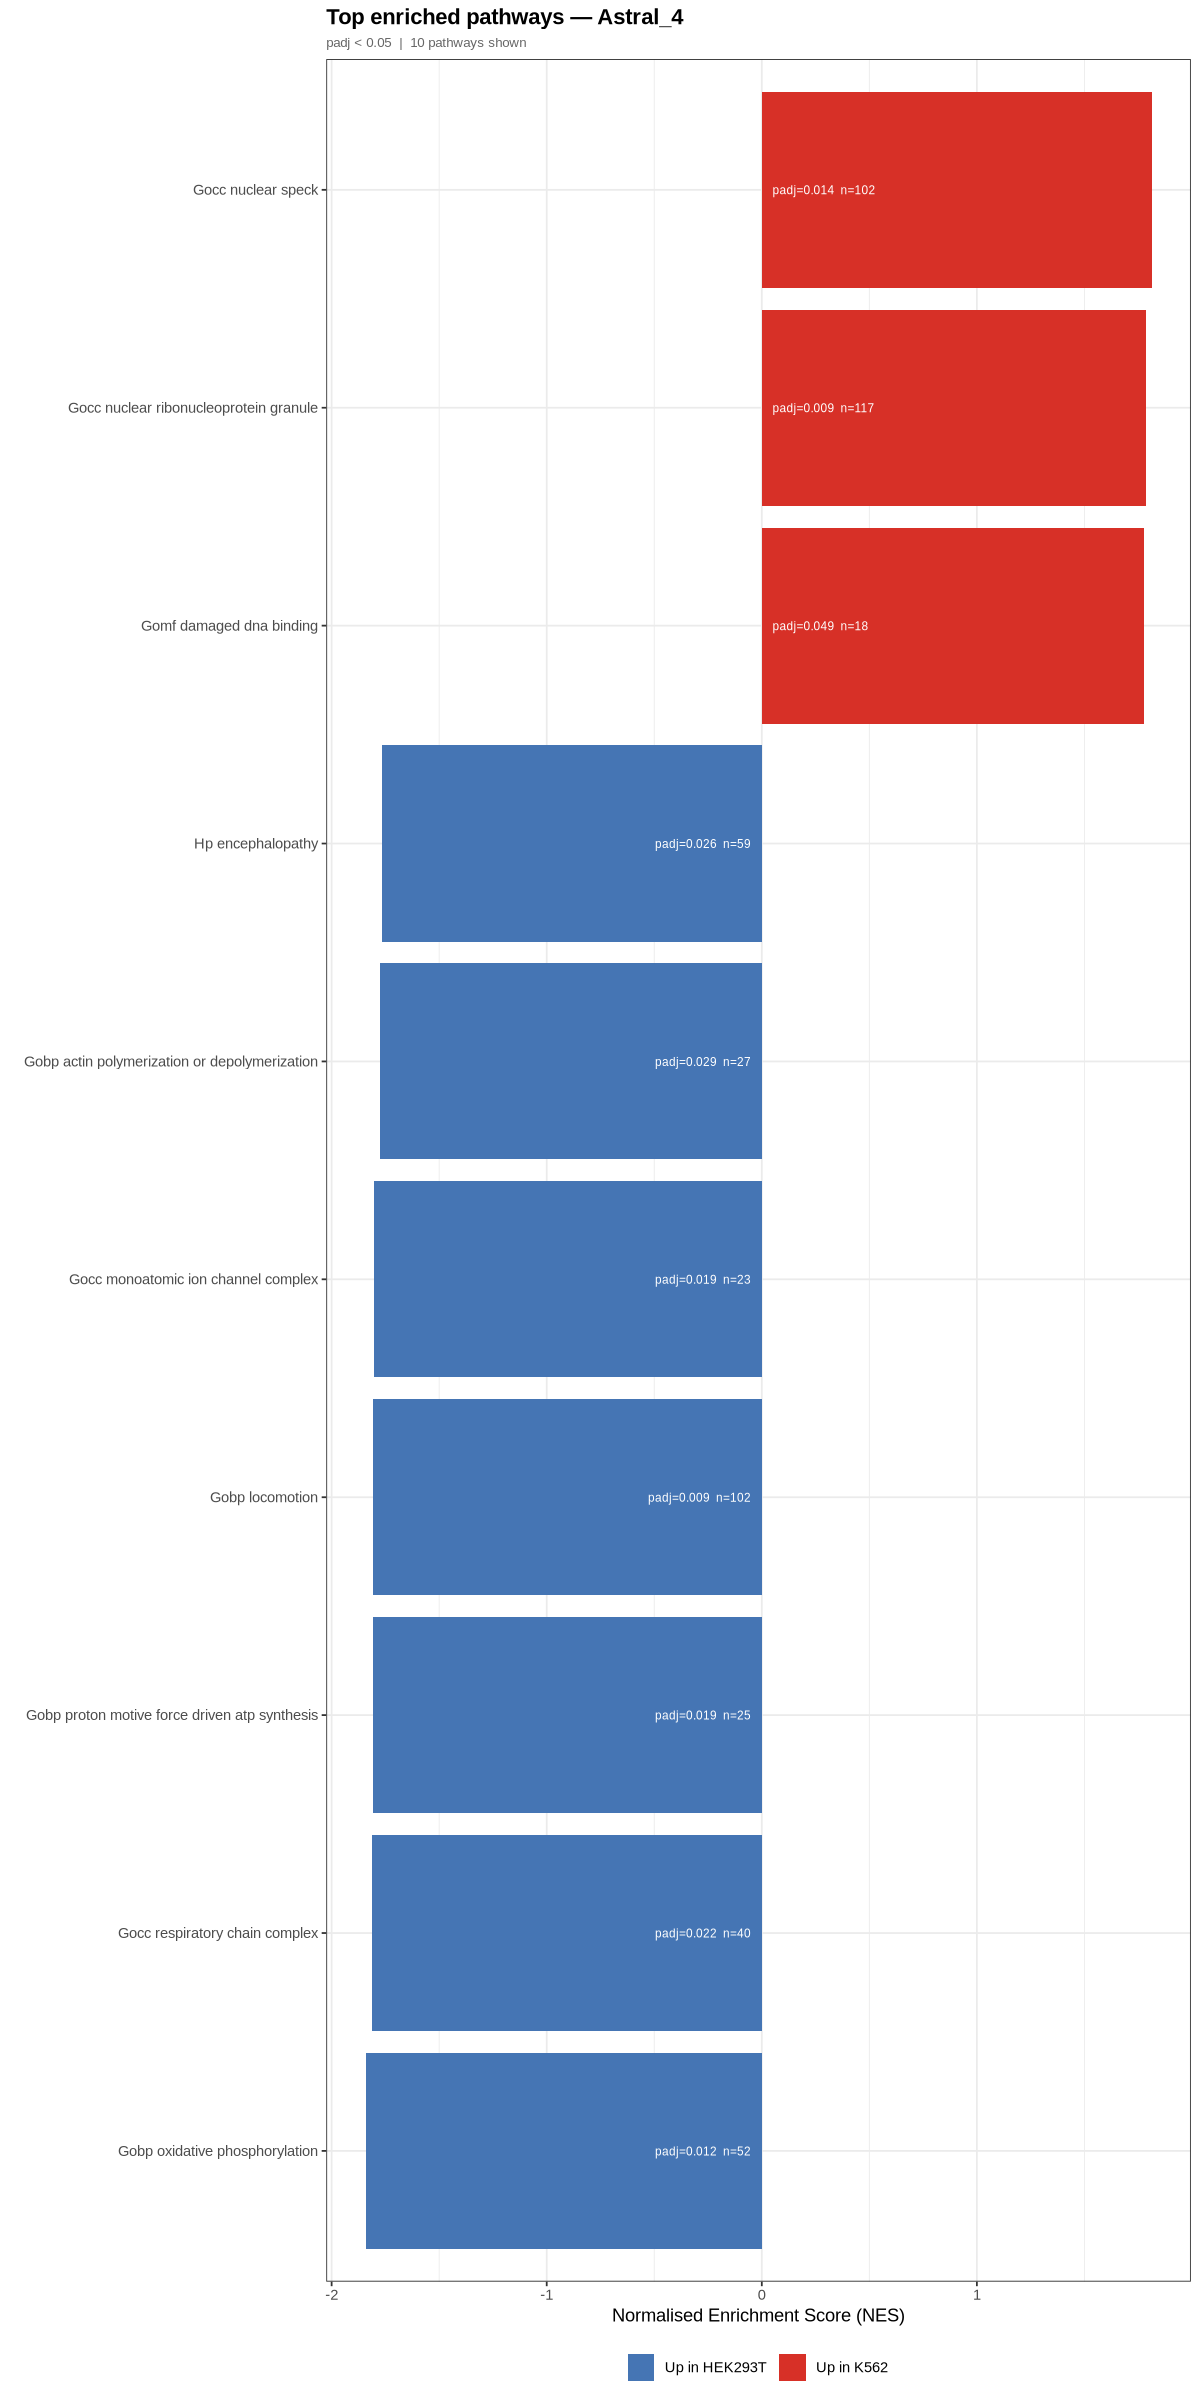

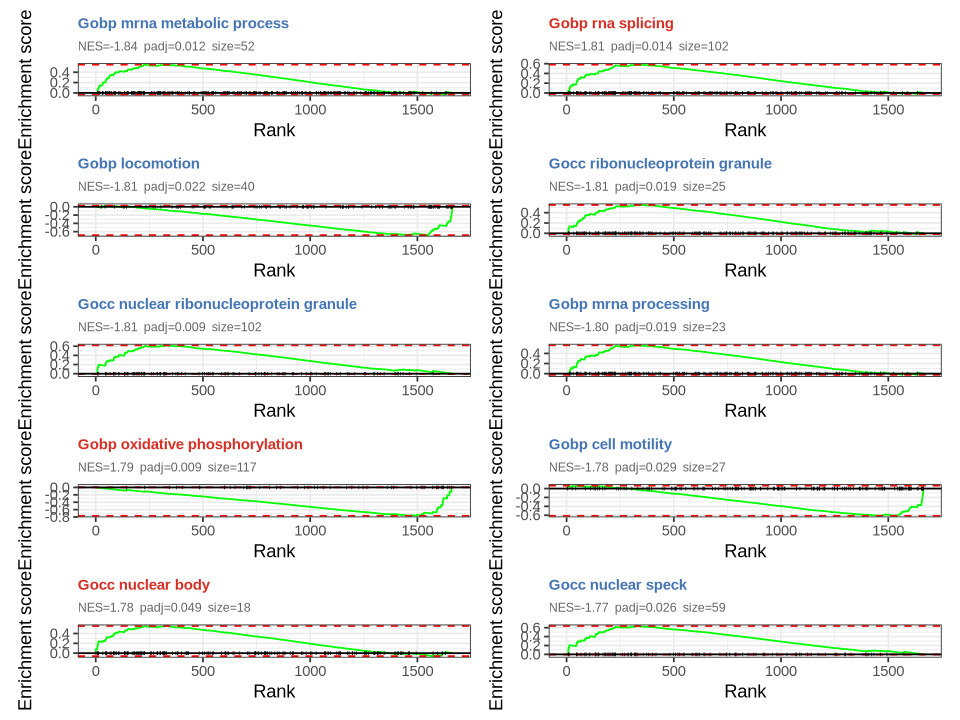

── Plotting Astral_5 ──


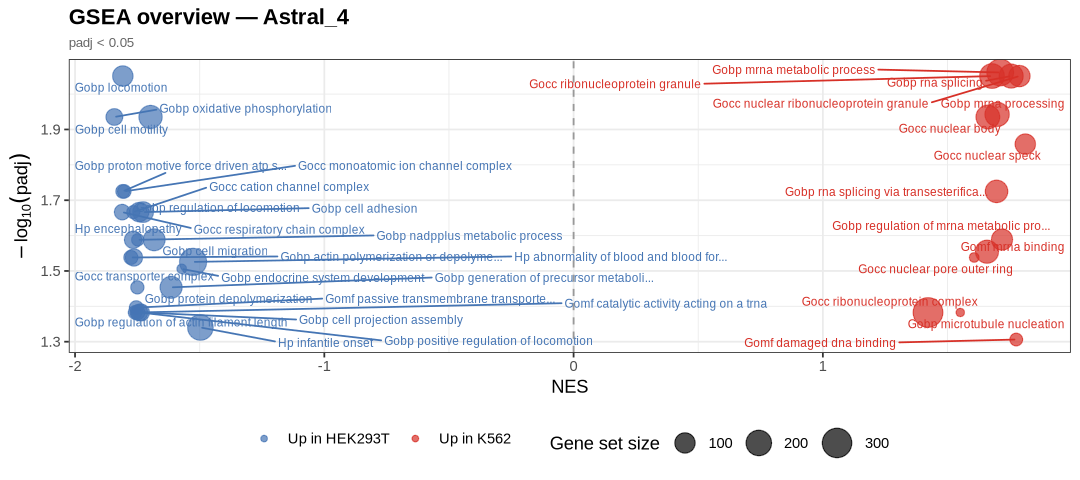

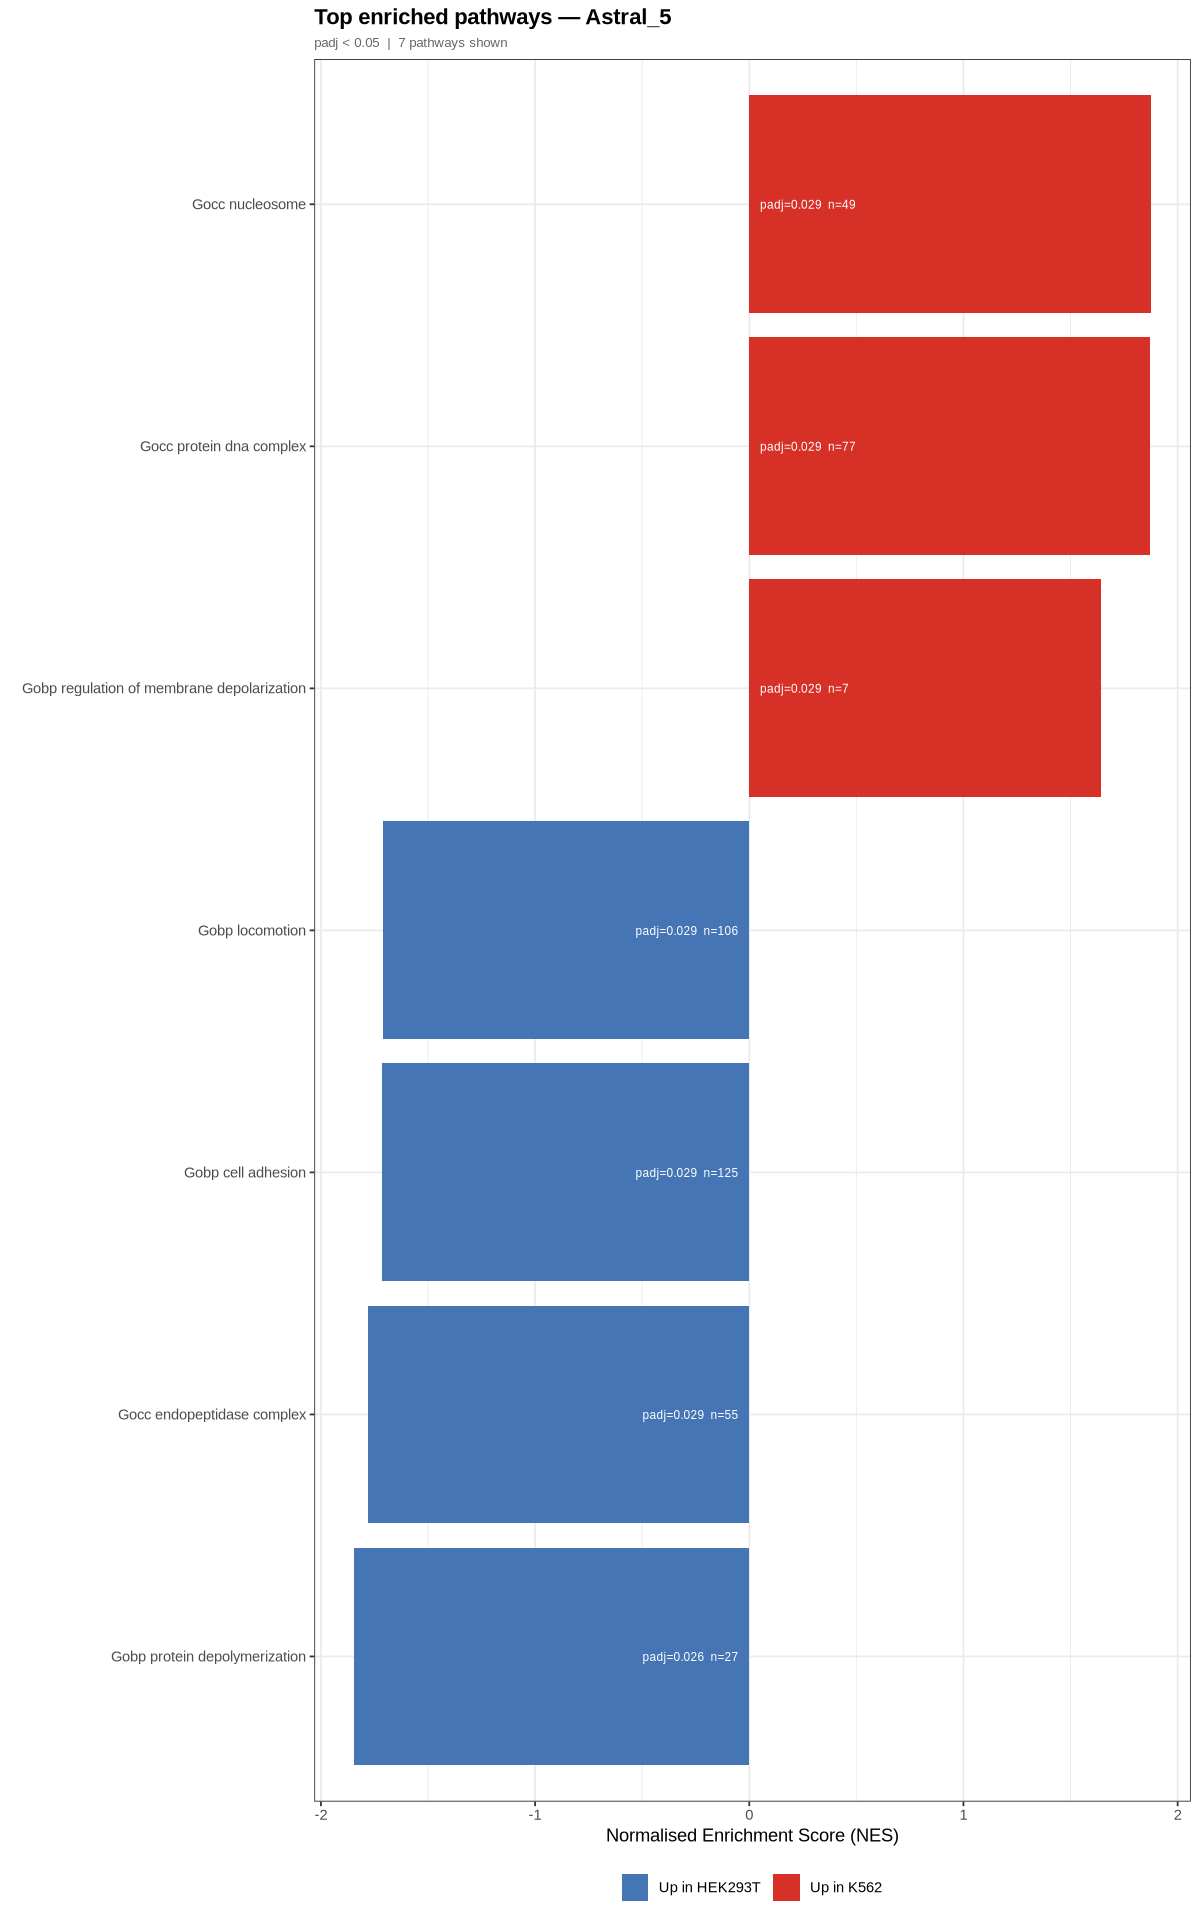

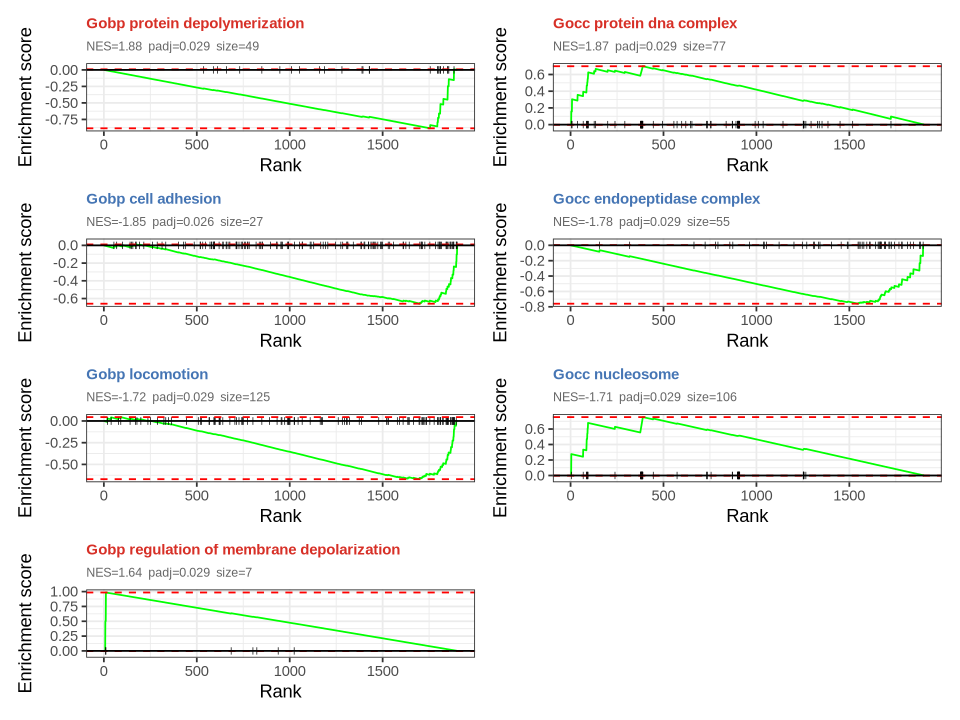

── Plotting Astral_6 ──


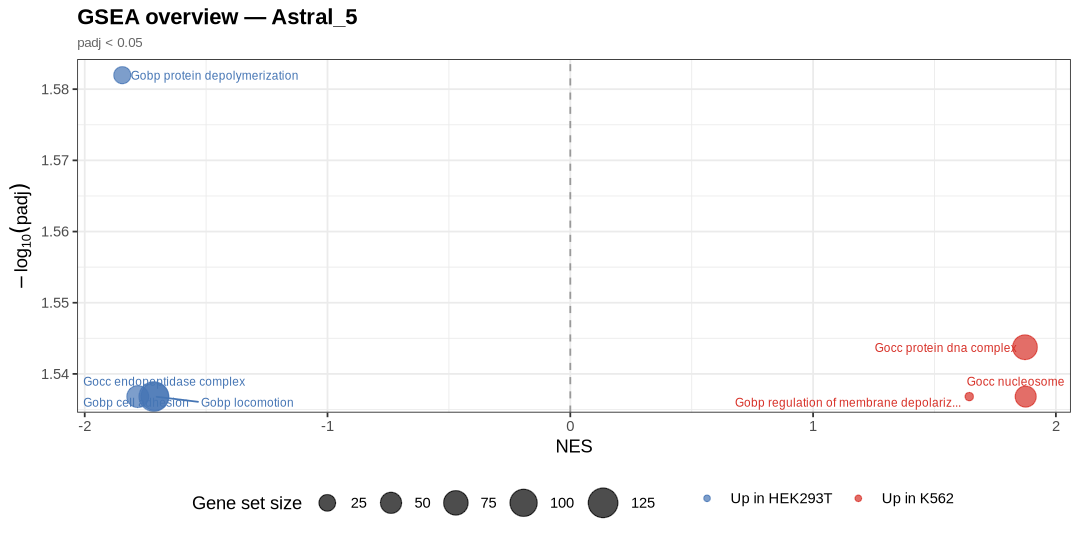

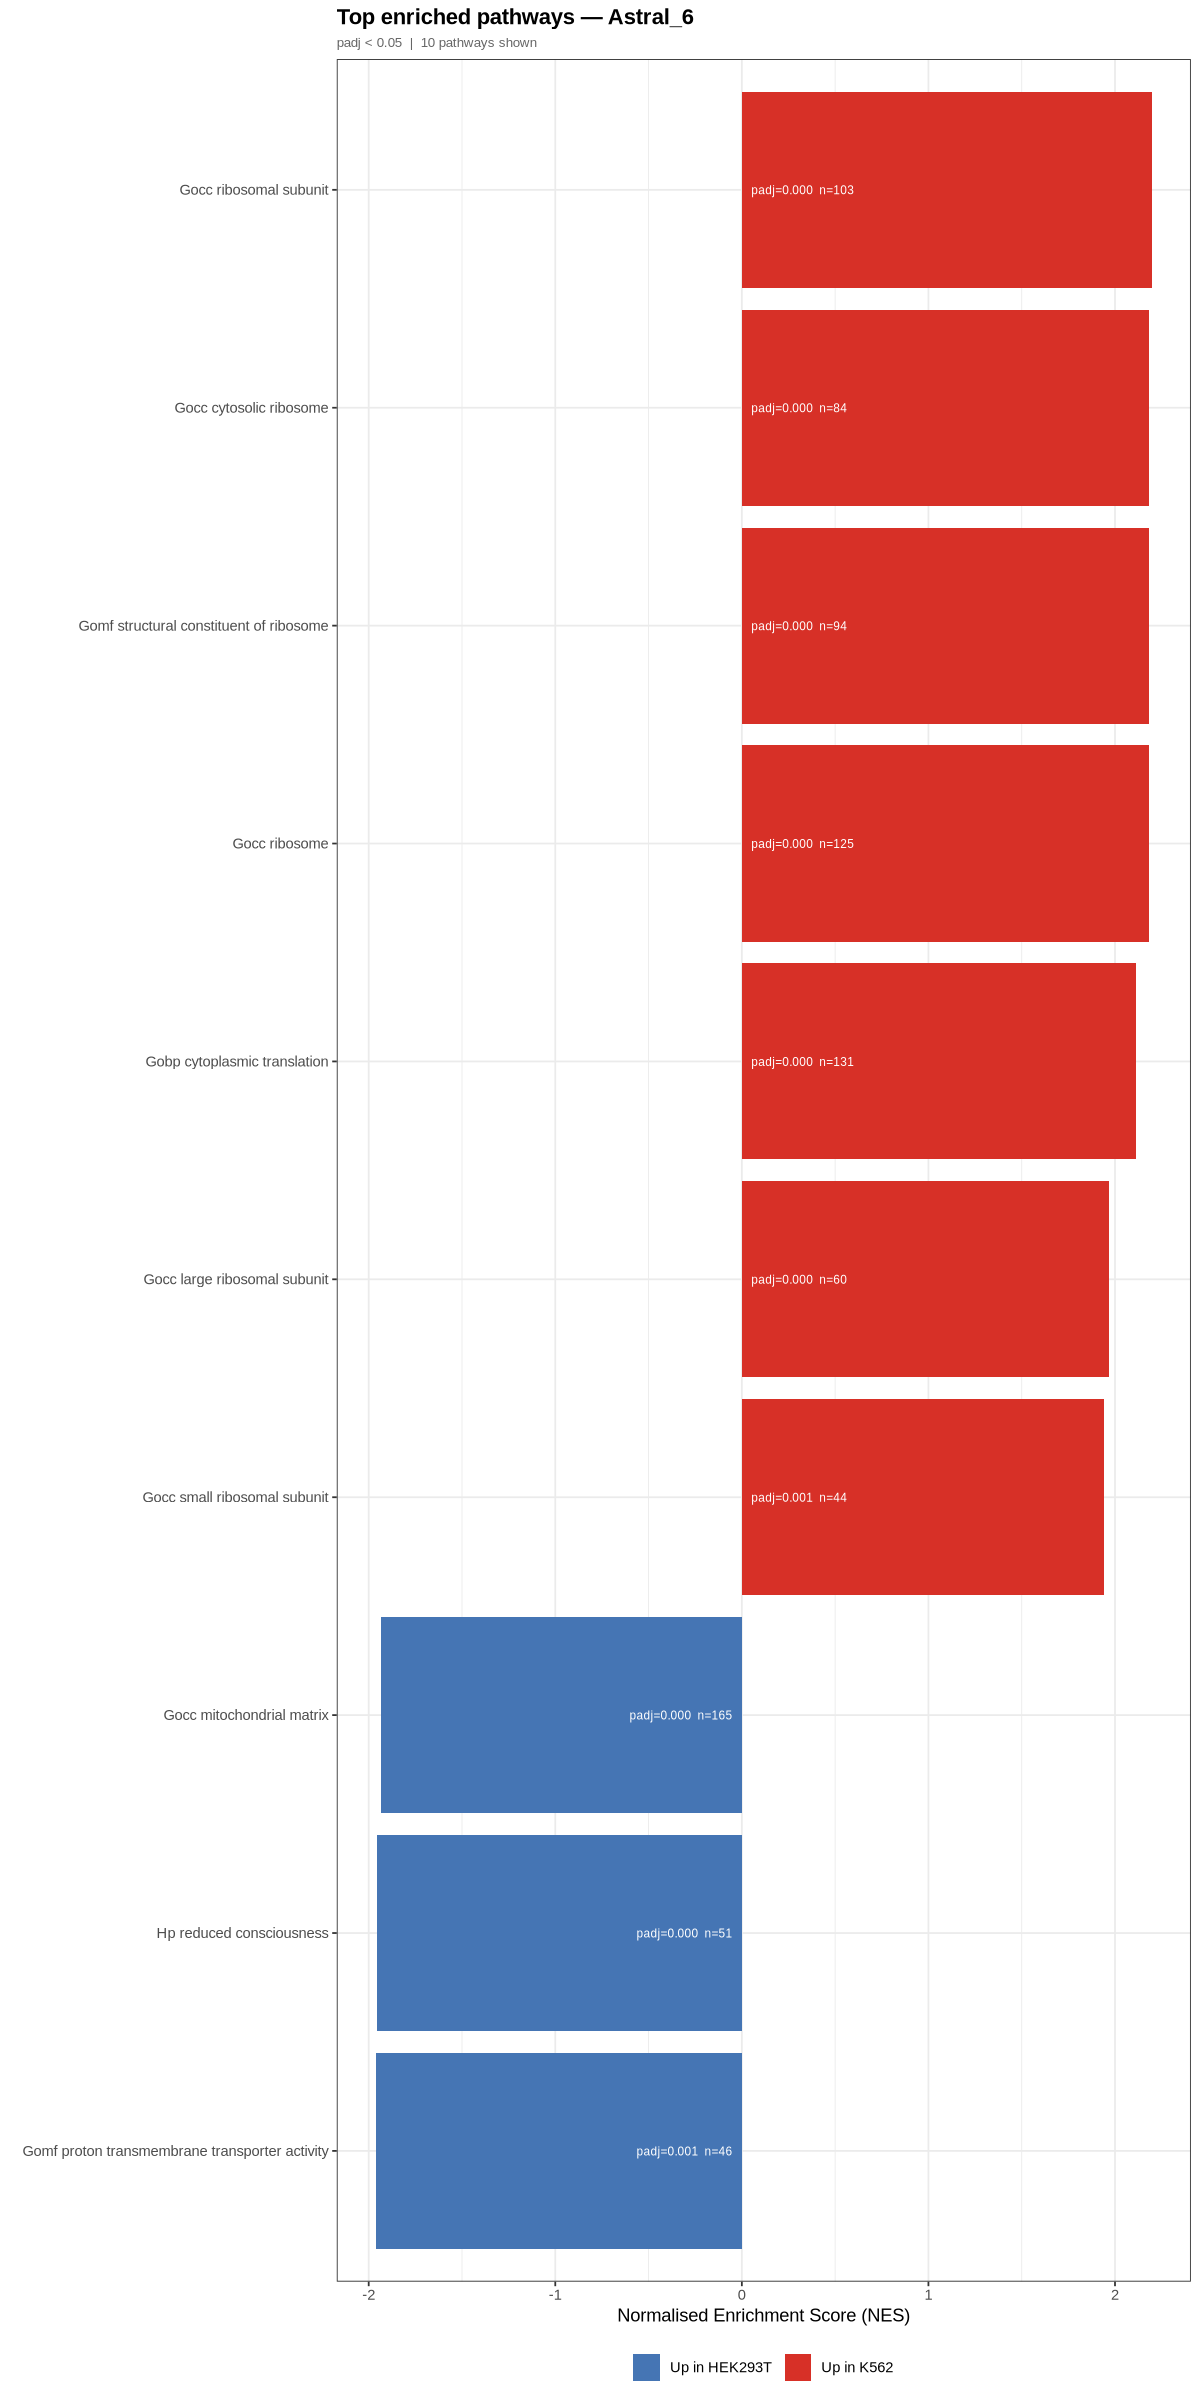

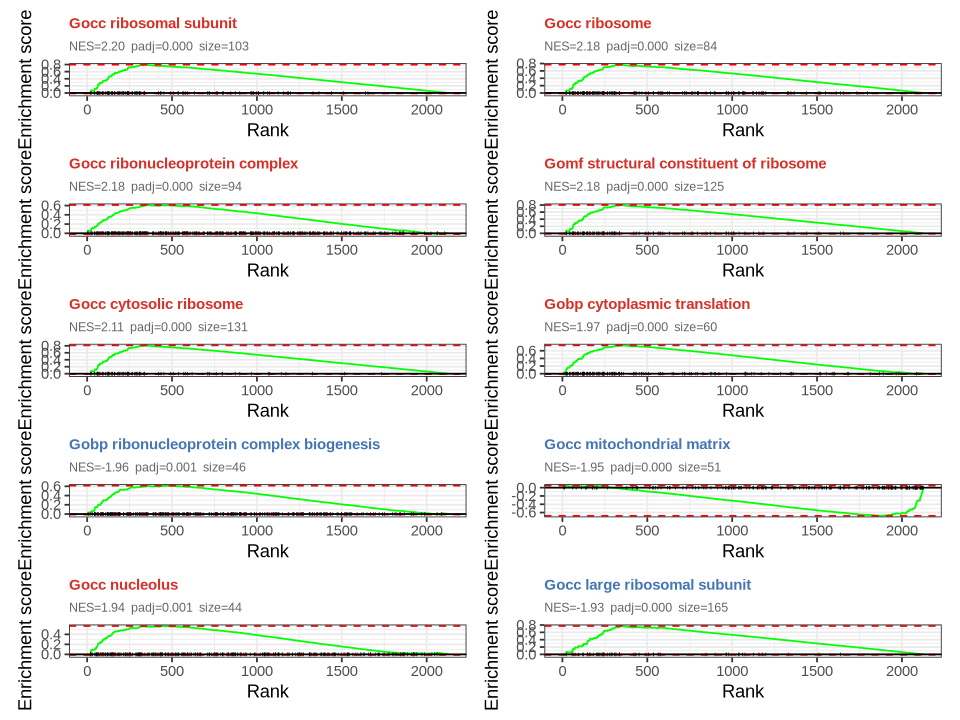

── Plotting timsTOF_1 ──


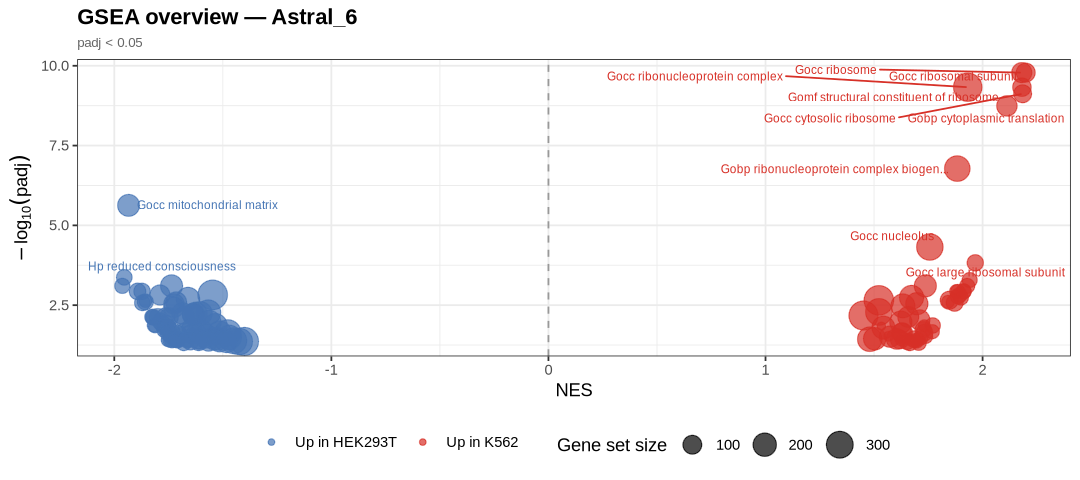

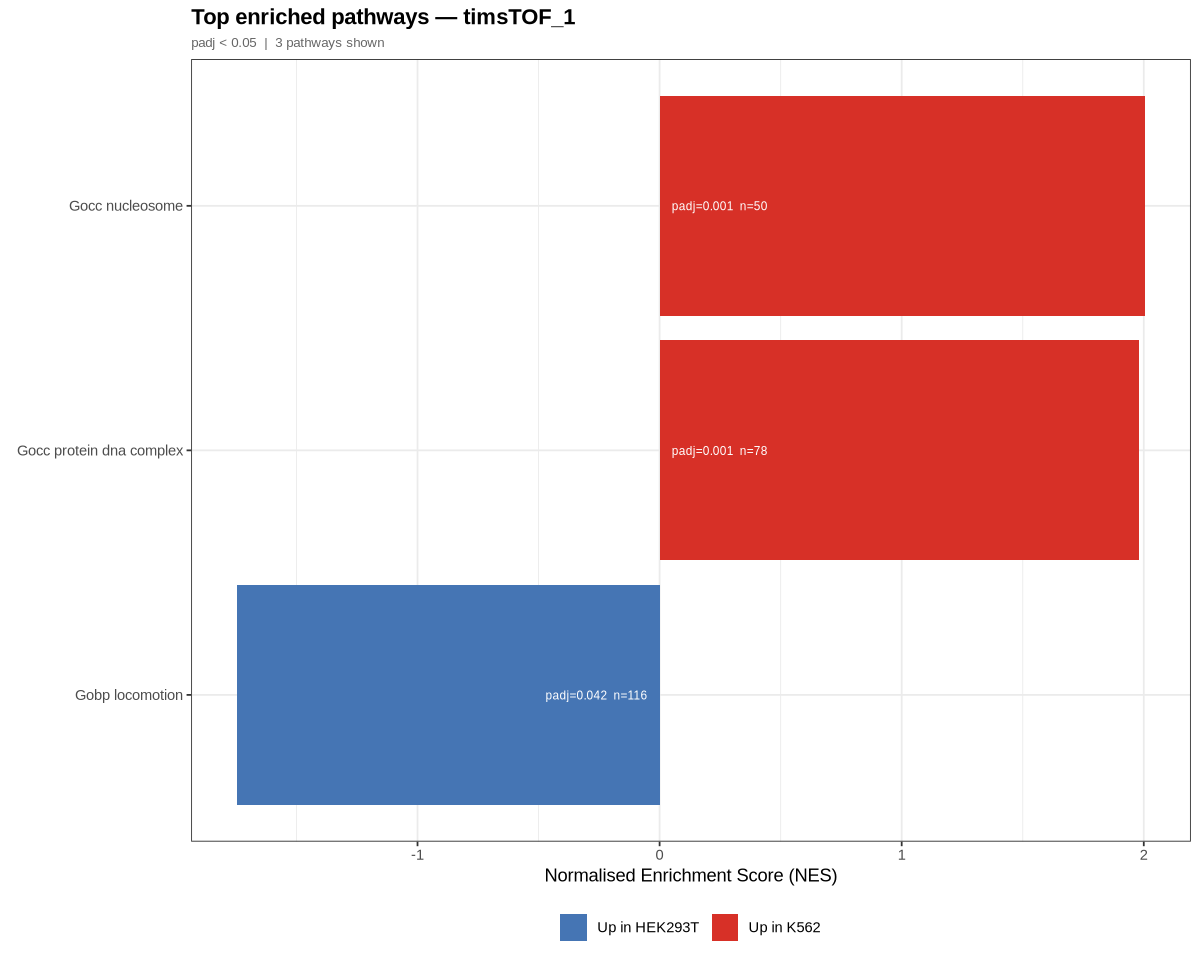

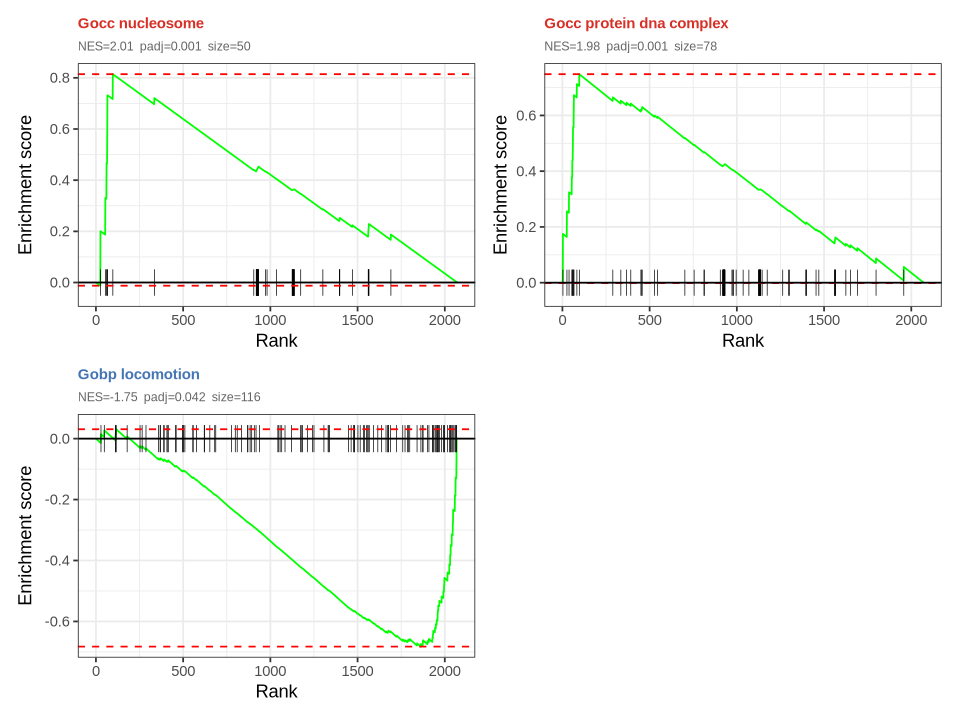

── Plotting timsTOF_2 ──


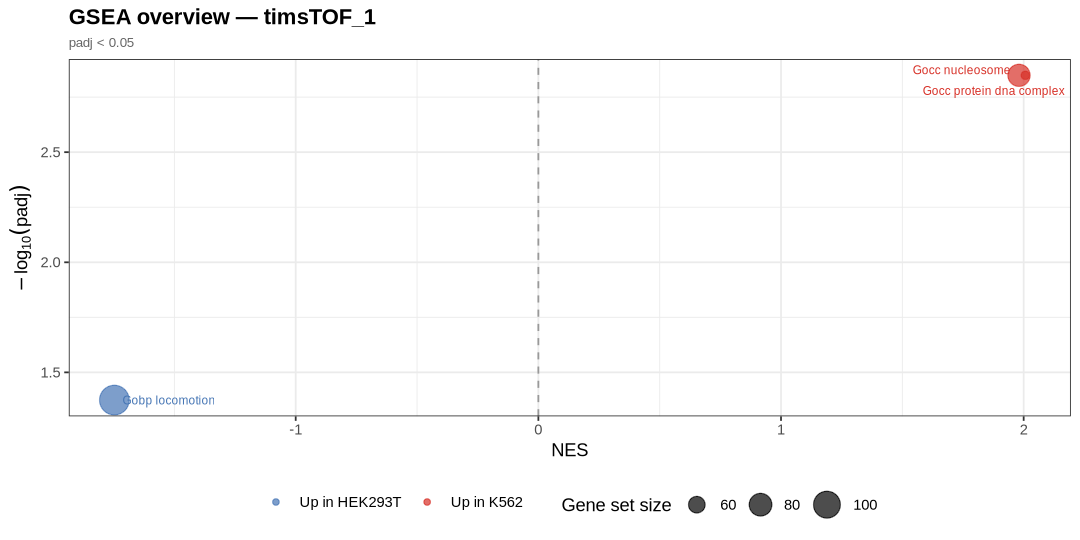

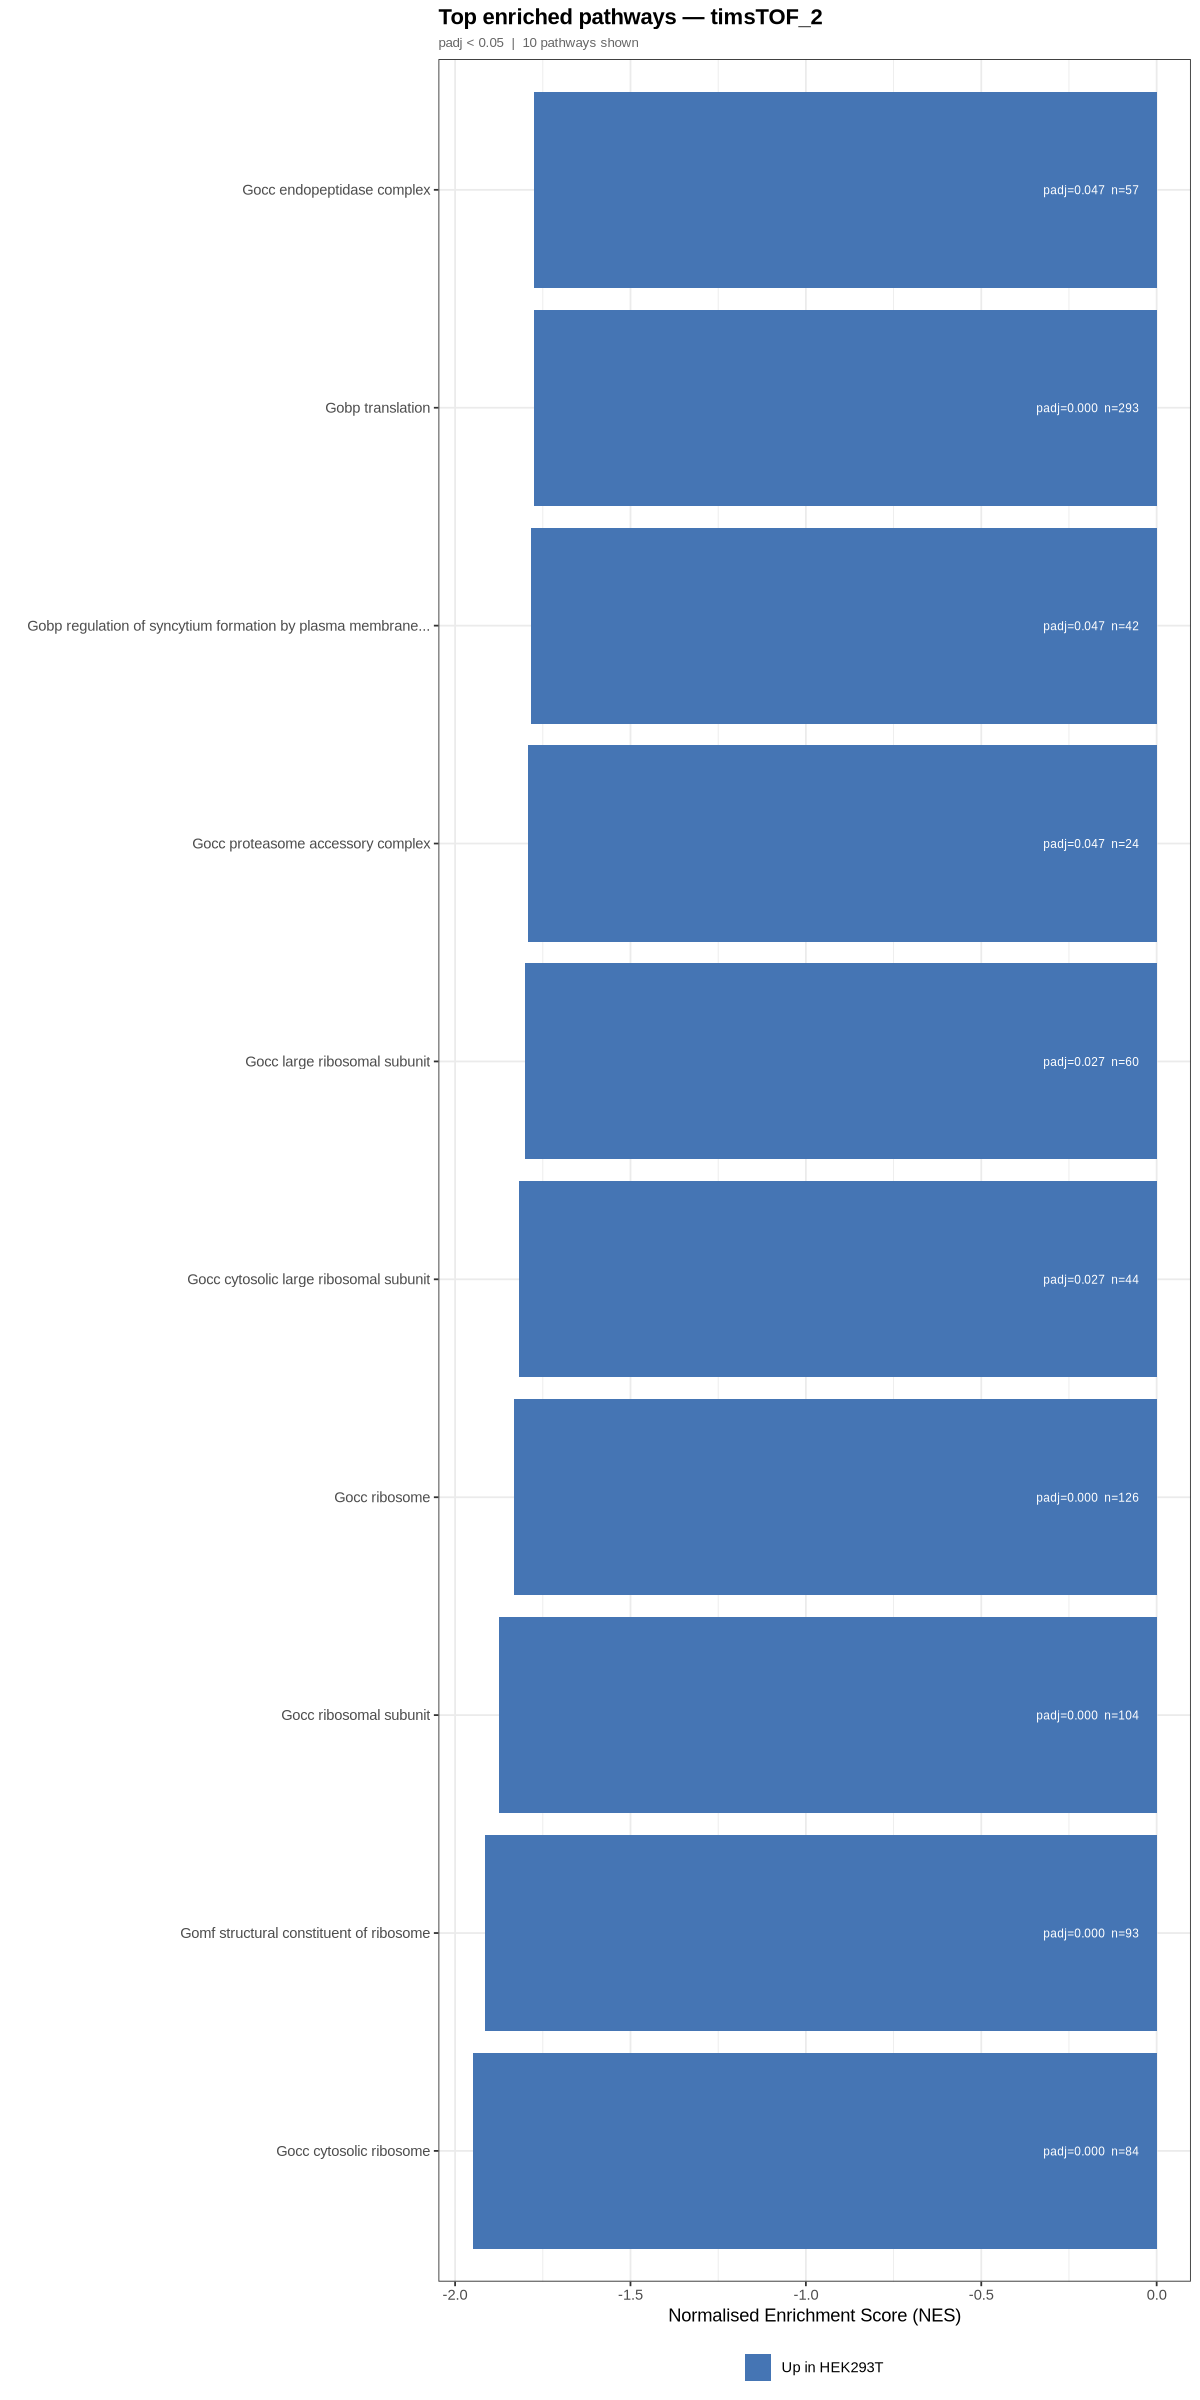

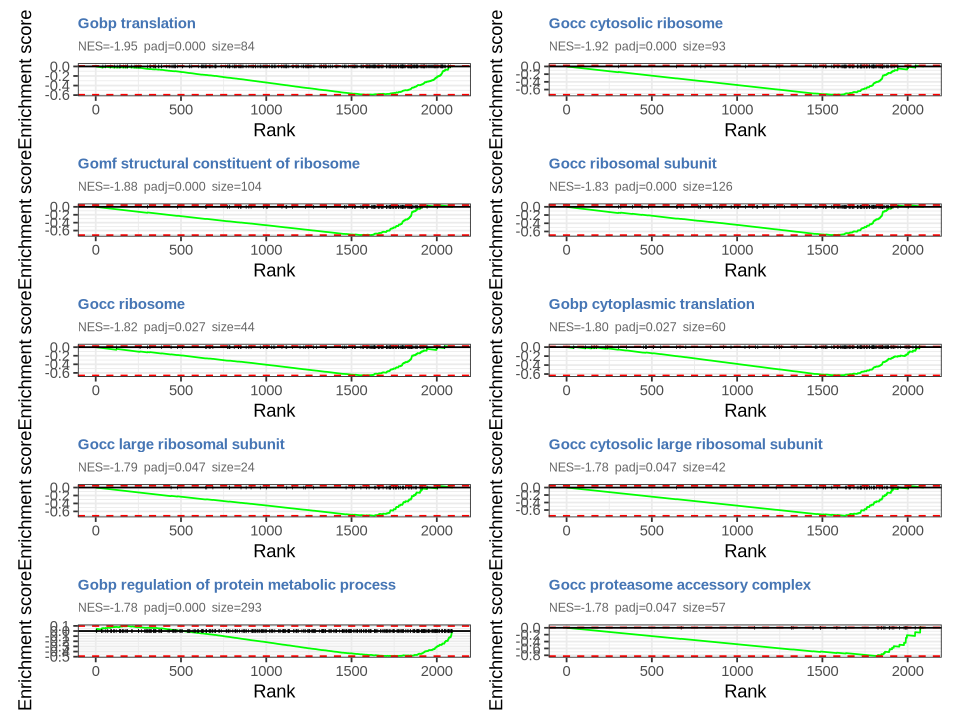

── Plotting timsTOF_3 ──


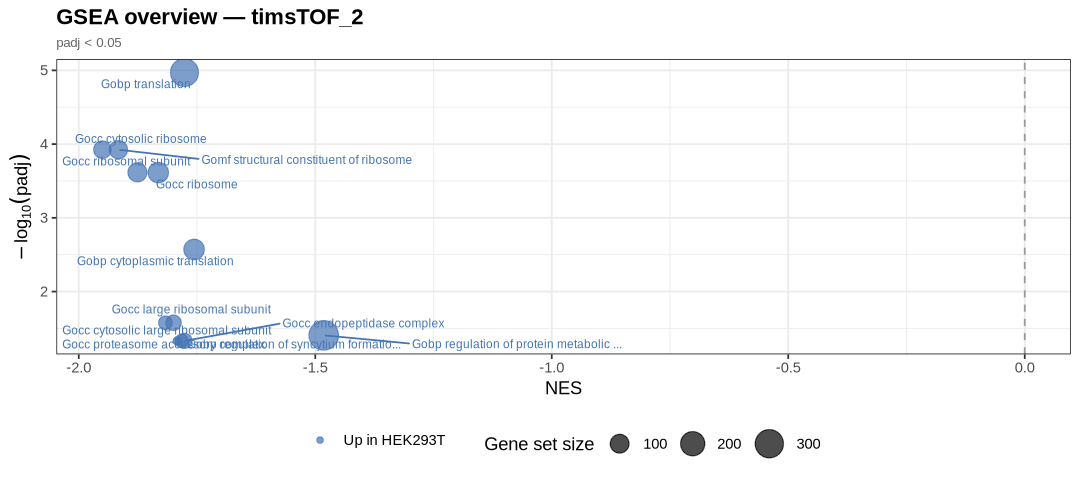

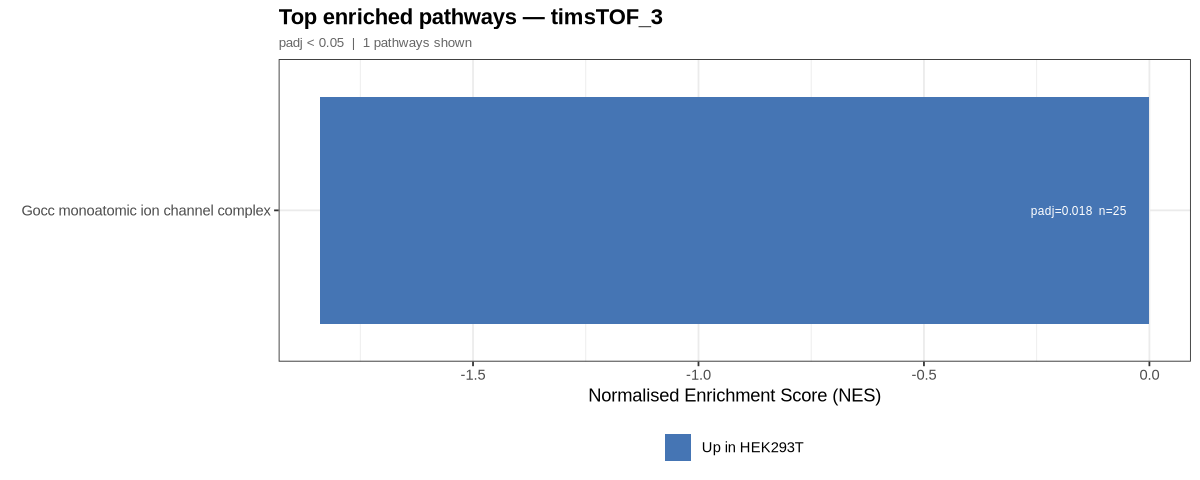

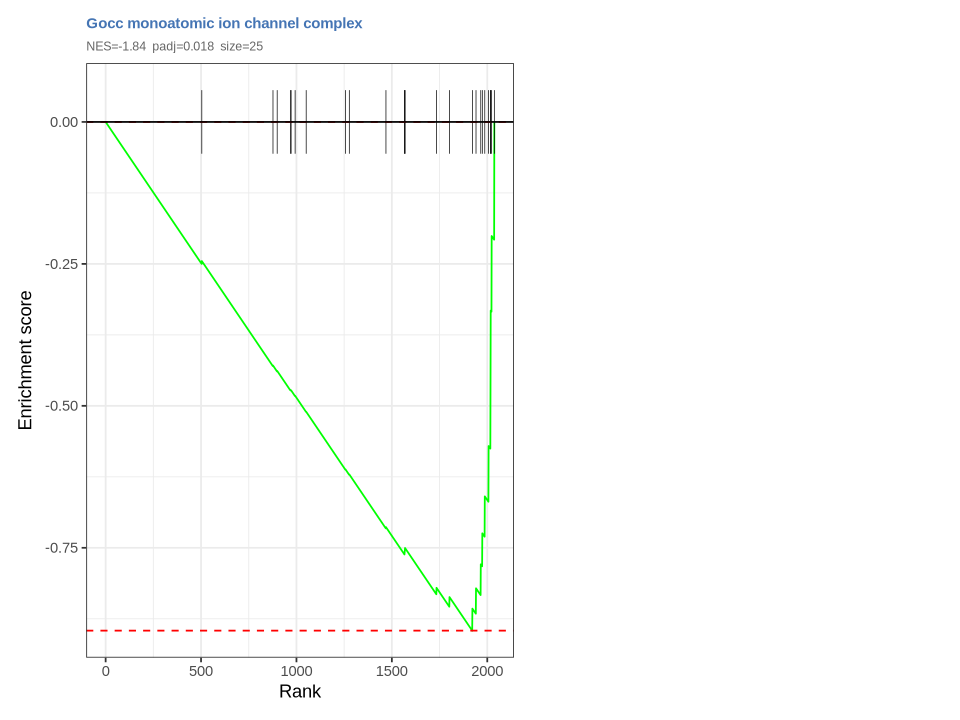

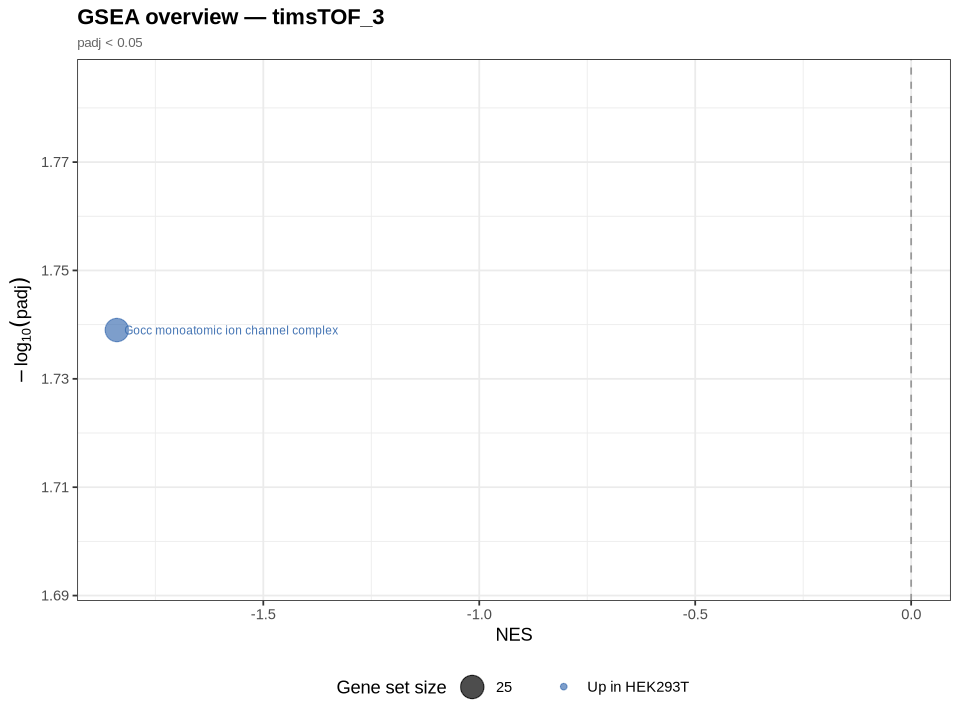

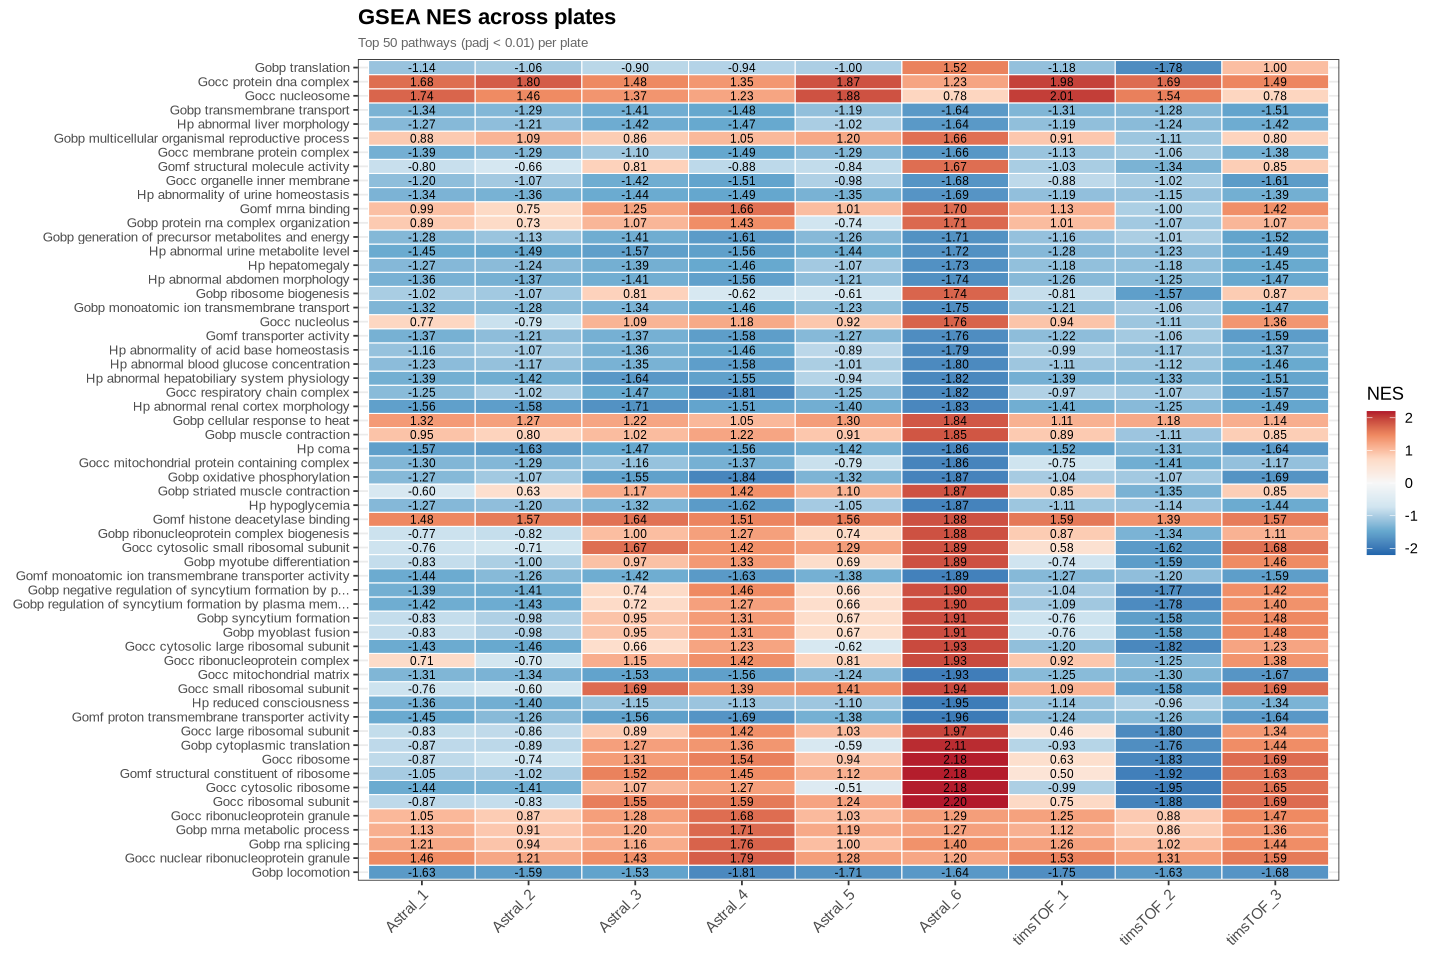

In [60]:
# ── Helper: enrichment plots for top N pathways per plate ─────────────────────
plot_gsea_plate <- function(gsea_out, pathways, plate_name,
                            n_top    = 10,
                            padj_cut = 0.05,
                            save_dir = NULL,
                            width    = 10,
                            height   = 4) {

    res   <- gsea_out$result
    ranks <- gsea_out$ranks

    # ── 1. Bar plot: top significant pathways by NES ───────────────────────────
    top_paths <- res %>%
        dplyr::filter(padj < padj_cut) %>%
        slice_max(abs(NES), n = n_top, with_ties = FALSE)

    if (nrow(top_paths) == 0) {
        cat(sprintf("  No significant pathways (padj < %.2f) for %s\n",
                    padj_cut, plate_name))
        return(invisible(NULL))
    }

    bar_fig <- top_paths %>%
        mutate(
            pathway   = stringr::str_trunc(
                            stringr::str_to_sentence(
                                gsub("_", " ", pathway)), 60),
            pathway   = factor(pathway, levels = pathway[order(NES)]),
            direction = ifelse(NES > 0, "Up in K562", "Up in HEK293T")
        ) %>%
        ggplot(aes(x = NES, y = pathway, fill = direction)) +
        geom_col() +
        geom_text(aes(
            label = sprintf("padj=%.3f  n=%d", padj, size),
            x     = ifelse(NES > 0, 0.05, -0.05),
            hjust = ifelse(NES > 0, 0, 1)
        ), size = 2.5, colour = "white") +
        scale_fill_manual(values = c("Up in K562"    = "#d73027",
                                     "Up in HEK293T" = "#4575b4")) +
        labs(
            title    = sprintf("Top enriched pathways — %s", plate_name),
            subtitle = sprintf("padj < %.2f  |  %d pathways shown",
                               padj_cut, nrow(top_paths)),
            x    = "Normalised Enrichment Score (NES)",
            y    = NULL,
            fill = NULL
        ) +
        theme_bw() +
        theme(
            plot.title    = element_text(face = "bold"),
            plot.subtitle = element_text(size = 8, colour = "grey40"),
            legend.position = "bottom"
        )

    # ── 2. Individual fgsea enrichment curves ─────────────────────────────────
    enrich_plots <- lapply(seq_len(nrow(top_paths)), function(i) {
        pw  <- top_paths$pathway[i]
        nes <- top_paths$NES[i]
        col <- if (nes > 0) "#d73027" else "#4575b4"

        # pathway name as stored in pathways list (original, not prettified)
        pw_orig <- res$pathway[i]

        plotEnrichment(pathways[[pw_orig]], ranks) +
            labs(
                title    = stringr::str_trunc(
                               stringr::str_to_sentence(
                                   gsub("_", " ", pw_orig)), 55),
                subtitle = sprintf("NES=%.2f  padj=%.3f  size=%d",
                                   top_paths$NES[i],
                                   top_paths$padj[i],
                                   top_paths$size[i]),
                x = "Rank",
                y = "Enrichment score"
            ) +
            theme_bw() +
            theme(
                plot.title    = element_text(size = 9,  face = "bold",
                                             colour = col),
                plot.subtitle = element_text(size = 7.5, colour = "grey40")
            )
    })

    n_cols      <- 2
    n_rows      <- ceiling(length(enrich_plots) / n_cols)
    enrich_grid <- patchwork::wrap_plots(enrich_plots, ncol = n_cols)

    # ── 3. Bubble plot: NES vs -log10(padj) ───────────────────────────────────
    bubble_fig <- res %>%
        dplyr::filter(padj < padj_cut) %>%
        mutate(
            label     = stringr::str_trunc(
                            stringr::str_to_sentence(
                                gsub("_", " ", pathway)), 40),
            direction = ifelse(NES > 0, "Up in K562", "Up in HEK293T"),
            sig       = -log10(padj)
        ) %>%
        ggplot(aes(x = NES, y = sig, size = size,
                   colour = direction, label = label)) +
        geom_point(alpha = 0.7) +
        ggrepel::geom_text_repel(size = 2.5, max.overlaps = 15,
                                 show.legend = FALSE) +
        geom_vline(xintercept = 0, linetype = "dashed", colour = "grey60") +
        scale_colour_manual(values = c("Up in K562"    = "#d73027",
                                       "Up in HEK293T" = "#4575b4")) +
        scale_size_continuous(range = c(2, 8), name = "Gene set size") +
        labs(
            title    = sprintf("GSEA overview — %s", plate_name),
            subtitle = sprintf("padj < %.2f", padj_cut),
            x        = "NES",
            y        = expression(-log[10](padj)),
            colour   = NULL
        ) +
        theme_bw() +
        theme(
            plot.title    = element_text(face = "bold"),
            plot.subtitle = element_text(size = 8, colour = "grey40"),
            legend.position = "bottom"
        )

    # ── Print / save ───────────────────────────────────────────────────────────
    plate_clean <- gsub("[/ ]", "_", plate_name)

    options(repr.plot.width = 9,
            repr.plot.height = max(4, nrow(top_paths) * 0.45))
    print(bar_fig)

    options(repr.plot.width = width, repr.plot.height = height * n_rows)
    print(enrich_grid)

    options(repr.plot.width = 8, repr.plot.height = 6)
    print(bubble_fig)

    if (!is.null(save_dir)) {
        dir.create(save_dir, showWarnings = FALSE, recursive = TRUE)
        save_figure(bar_fig,
                    file.path(save_dir, sprintf("gsea_bar_%s",      plate_clean)),
                    width = 9,
                    height = max(4, nrow(top_paths) * 0.45))
        save_figure(enrich_grid,
                    file.path(save_dir, sprintf("gsea_enrichment_%s", plate_clean)),
                    width  = width,
                    height = height * n_rows)
        save_figure(bubble_fig,
                    file.path(save_dir, sprintf("gsea_bubble_%s",   plate_clean)),
                    width = 8, height = 6)
    }

    invisible(list(bar = bar_fig, enrichment = enrich_grid, bubble = bubble_fig))
}


# ── Cross-plate summary heatmap ───────────────────────────────────────────────
plot_gsea_heatmap <- function(gsea_results,
                              n_top    = 20,
                              padj_cut = 0.05,
                              save_dir = NULL,
                              width    = 12,
                              height   = 8) {

    # collect top pathways across all plates
    top_per_plate <- lapply(names(gsea_results), function(plate) {
        res <- gsea_results[[plate]]$result
        res %>%
            dplyr::filter(padj < padj_cut) %>%
            slice_max(abs(NES), n = n_top, with_ties = FALSE) %>%
            dplyr::select(pathway, NES) %>%
            mutate(plate = plate)
    })

    top_pathways <- Reduce(union,
                           lapply(top_per_plate, function(x) x$pathway))

    if (length(top_pathways) == 0) {
        cat("No significant pathways found across any plate.\n")
        return(invisible(NULL))
    }

    # build NES matrix: pathways x plates
    nes_mat <- sapply(names(gsea_results), function(plate) {
        res <- gsea_results[[plate]]$result
        v   <- setNames(res$NES, res$pathway)
        v[top_pathways]          # NA if pathway not tested in this plate
    })
    rownames(nes_mat) <- top_pathways

    # prettify pathway names
    rownames(nes_mat) <- stringr::str_trunc(
        stringr::str_to_sentence(gsub("_", " ", rownames(nes_mat))), 55)

    df_long <- as.data.frame(nes_mat) %>%
        rownames_to_column("pathway") %>%
        pivot_longer(-pathway, names_to = "plate", values_to = "NES") %>%
        mutate(
            pathway = factor(pathway, levels = rownames(nes_mat)),
            plate   = factor(plate,   levels = names(gsea_results))
        )

    fig <- ggplot(df_long, aes(x = plate, y = pathway, fill = NES)) +
        geom_tile(colour = "white", linewidth = 0.3) +
        geom_text(aes(label = ifelse(!is.na(NES),
                                     sprintf("%.2f", NES), "")),
                  size = 2.5) +
        scale_fill_distiller(palette  = "RdBu",
                             direction = -1,
                             na.value  = "grey90",
                             name      = "NES",
                             limits    = c(-max(abs(nes_mat), na.rm = TRUE),
                                            max(abs(nes_mat), na.rm = TRUE))) +
        labs(
            title    = "GSEA NES across plates",
            subtitle = sprintf("Top %d pathways (padj < %.2f) per plate",
                               n_top, padj_cut),
            x = NULL, y = NULL
        ) +
        theme_bw() +
        theme(
            axis.text.x   = element_text(angle = 45, hjust = 1),
            axis.text.y   = element_text(size  = 8),
            plot.title    = element_text(face = "bold"),
            plot.subtitle = element_text(size = 8, colour = "grey40")
        )

    options(repr.plot.width = width, repr.plot.height = height)
    print(fig)

    if (!is.null(save_dir)) {
        dir.create(save_dir, showWarnings = FALSE, recursive = TRUE)
        save_figure(fig, file.path(save_dir, "gsea_heatmap"),
                    width = width, height = height)
    }

    invisible(fig)
}


# ── Run all plots ──────────────────────────────────────────────────────────────
gsea_plot_dir <- file.path(RESULTS_DIR, "gsea")

# per-plate plots
gsea_plots <- mapply(
    function(gsea_out, plate_name) {
        if (is.null(gsea_out)) return(NULL)
        cat(sprintf("── Plotting %s ──\n", plate_name))
        plot_gsea_plate(
            gsea_out   = gsea_out,
            pathways   = pathways_bg,
            plate_name = plate_name,
            n_top      = 10,
            padj_cut   = 0.05,
            save_dir   = gsea_plot_dir
        )
    },
    gsea_results, names(gsea_results),
    SIMPLIFY = FALSE
)

# cross-plate heatmap
plot_gsea_heatmap(
    gsea_results = gsea_results,
    n_top        = 50,
    padj_cut     = 0.01,
    save_dir     = gsea_plot_dir
)

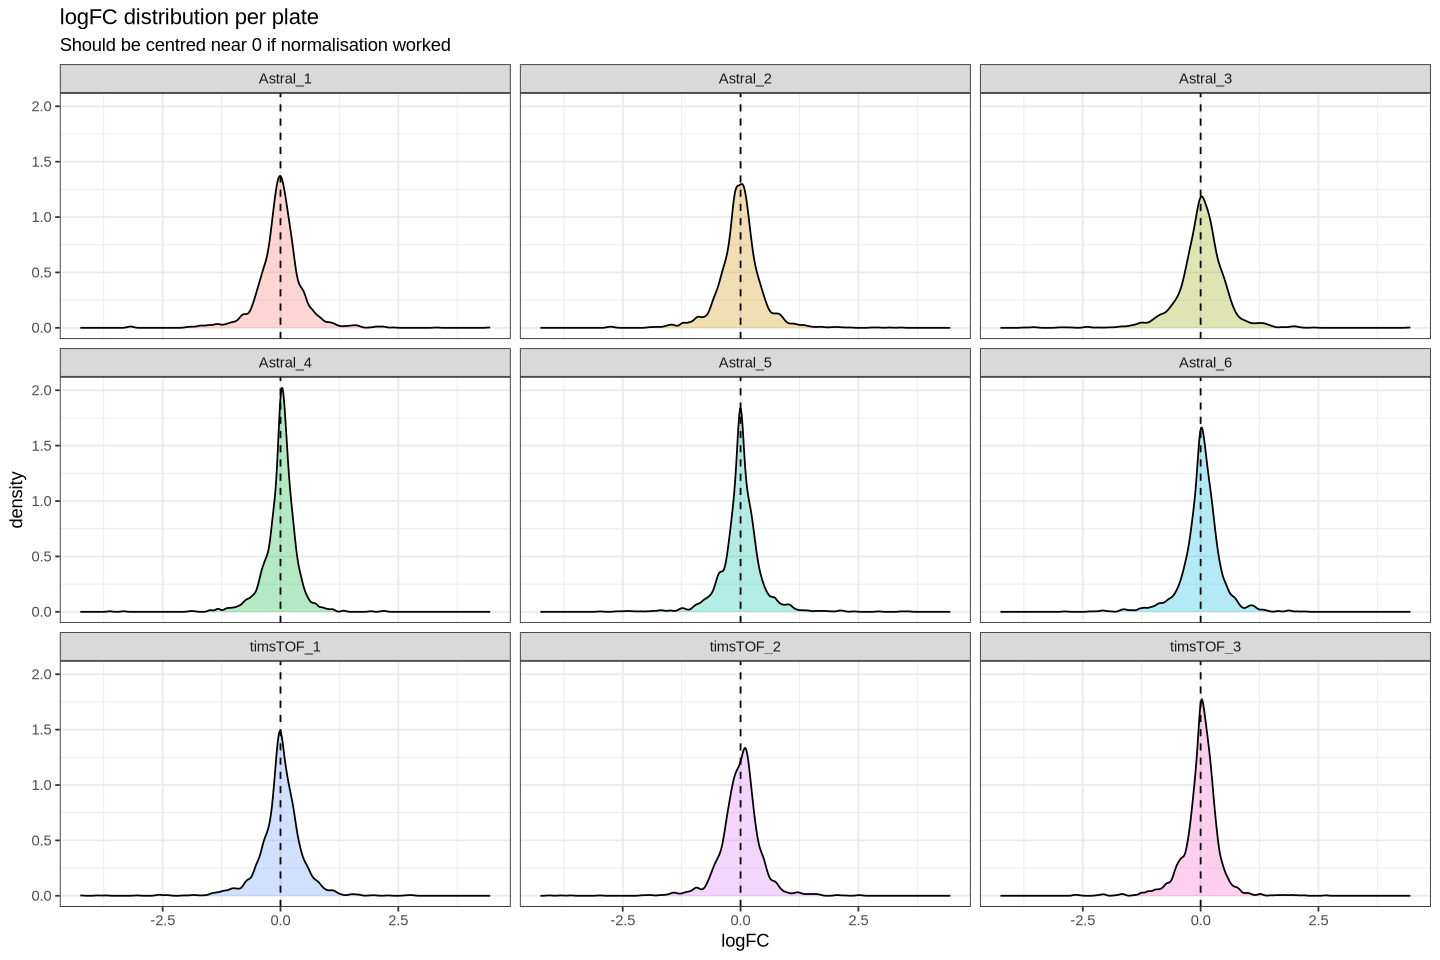

In [59]:
bind_rows(results_per_plate, .id = "plate") %>%
    filter(!is.na(logFC)) %>%
    ggplot(aes(x = logFC, fill = plate)) +
    geom_density(alpha = 0.3) +
    geom_vline(xintercept = 0, linetype = "dashed") +
    facet_wrap(~plate) +
    labs(title = "logFC distribution per plate",
         subtitle = "Should be centred near 0 if normalisation worked") +
    theme_bw() +
    theme(legend.position = "none")